# ĐỒ ÁN: PHÂN TÍCH VÀ ĐÁNH GIÁ SẢN PHẨM ĐA KHÍA CẠNH TỪ BÌNH LUẬN KHÁCH HÀNG SHOPEE

# PHẦN 0 – Hằng số và hàm dùng chung

In [1]:
## 1. Import thư viện cho các hàm - import

In [2]:
import re
import unicodedata

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.pipeline import Pipeline

In [3]:
## 2. Hằng số

In [4]:
RANDOM_STATE = 0
TI_LE_TEST = 0.3
SO_FOLD = 5

In [5]:
NHAN_TICH_CUC = 'positive'
NHAN_TIEU_CUC = 'negative'
TEN_TICH_CUC = 'Tích cực'
TEN_TRUNG_LAP = 'Trung lập'
TEN_TIEU_CUC = 'Tiêu cực'

In [6]:
NGUONG_DUOI = 0.20
NGUONG_TREN = 0.80
DS_CAP_NGUONG = [(0.40, 0.60), (0.30, 0.70), (0.20, 0.80)]

In [7]:
NGRAM_RANGE = (1, 2)
MIN_DF = 2
SUBLINEAR_TF = True
MAX_ITER = 1000

In [8]:
DO_DAI_TEN_TIEU_CHI = 30
DAU_NGAN_TIEU_CHI = '  '

MAU_EMOJI = '[\U0001F300-\U0001F3FA\U0001F400-\U0001FAFF☀-➿⬀-⯿]'

In [9]:
TEENCODE = {
    'ko': 'không', 'k': 'không', 'kh': 'không', 'khong': 'không', 'hok': 'không',
    'hong': 'không', 'hông': 'không', 'khg': 'không', 'hk': 'không',
    'dc': 'được', 'đc': 'được', 'duoc': 'được',
    'sp': 'sản phẩm', 'sd': 'sử dụng', 'hsd': 'hạn sử dụng', 'srm': 'sữa rửa mặt',
    'bt': 'bình thường', 'bth': 'bình thường', 'bthg': 'bình thường',
    'vs': 'với', 'j': 'gì', 'r': 'rồi', 'z': 'vậy',
    'mk': 'mình', 'mik': 'mình', 'mn': 'mọi người', 'mng': 'mọi người', 'ng': 'người',
    'nt': 'nhắn tin', 'cx': 'cũng', 'trc': 'trước', 'lun': 'luôn', 'lm': 'làm',
    'ntn': 'như thế nào', 'chx': 'chưa', 'nhìu': 'nhiều', 'nhiu': 'nhiều',
    'nma': 'nhưng mà', 'ncl': 'nói chung là', 'nch': 'nói chung', 'siu': 'siêu',
    'oke': 'ok', 'oki': 'ok', 'okie': 'ok',
    'tks': 'cảm ơn', 'thanks': 'cảm ơn', 'thank': 'cảm ơn',
    'ship': 'giao hàng', 'sốp': 'shop',
    'tot': 'tốt', 'dep': 'đẹp', 'thom': 'thơm',
}

In [10]:
DS_TU_PHU_DINH = ['không', 'chưa', 'chẳng', 'chả', 'đừng']
DS_TU_TUONG_PHAN = ['nhưng', 'tuy', 'mỗi tội', 'có điều', 'ngoại trừ']

TU_KHOA_KHIA_CANH = {
    'kc_giao_hang': ['giao', 'giao hàng', 'shipper', 'vận chuyển', 'đơn vị vận chuyển'],
    'kc_chat_luong': ['chất lượng', 'hàng giả', 'fake', 'chính hãng', 'hỏng', 'hư', 'lỗi', 'bền'],
    'kc_dong_goi': ['đóng gói', 'gói', 'hộp', 'móp', 'bọc', 'chống sốc', 'bao bì'],
    'kc_gia': ['giá', 'rẻ', 'đắt', 'mắc', 'tiền'],
    'kc_shop': ['shop', 'tư vấn', 'nhắn tin', 'trả lời', 'phản hồi', 'chăm sóc khách hàng'],
}

In [11]:
TIEU_CHI_NGANH_HANG = {
    'Mỹ phẩm': ['Mùi hương', 'Hương thơm', 'Dành cho da', 'Làm đẹp', 'Phù hợp với loại da',
                'Làm sạch', 'Dưỡng ẩm', 'Độ lưu hương', 'Dành cho tóc', 'Kiểm soát dầu', 'Làm sáng da'],
    'Thực phẩm': ['Hương vị', 'Độ giòn'],
    'Thời trang': ['Chất liệu', 'Màu sắc', 'Kích cỡ', 'Kích thước'],
}
NGANH_KHAC = 'Khác'
NGANH_KHONG_RO = 'Không rõ'

In [12]:
DS_NHAN_DO_DAI = ['Ngắn', 'Vừa', 'Dài']

In [13]:
SO_CAU_EMOJI_TOI_THIEU = 5
TI_LE_EMOJI_RO_RANG = 0.7

DS_EMOJI_TICH_CUC = ['🥰', '❤', '👍', '😍', '🤣', '💯', '🫶', '😘', '☺', '🌟', '😚']
DS_EMOJI_TIEU_CUC = ['🥲', '😡', '😭', '🙂', '🥹', '⭐', '😢', '😀', '😌', '🙃',
                     '👎', '😑', '🙄', '😓', '😃', '😞', '😥', '😤', '🙏', '🥺']
TU_EMOJI_TICH_CUC = 'emoji_tich_cuc'
TU_EMOJI_TIEU_CUC = 'emoji_tieu_cuc'

In [14]:
DS_KHIA_CANH = ['PRODUCT_QUALITY', 'DELIVERY', 'PACKAGING', 'PRICE', 'SELLER_SERVICE', 'PRODUCT_FEATURE']

TEN_KHIA_CANH_ABSA = {
    'PRODUCT_QUALITY': 'Chất lượng sản phẩm',
    'DELIVERY': 'Giao hàng',
    'PACKAGING': 'Đóng gói',
    'PRICE': 'Giá',
    'SELLER_SERVICE': 'Dịch vụ của shop',
    'PRODUCT_FEATURE': 'Thuộc tính sản phẩm',
}

TU_KHOA_ABSA = {
    'PRODUCT_QUALITY': ['chất lượng', 'hàng giả', 'fake', 'chính hãng', 'hỏng', 'hư', 'lỗi', 'bền',
                        'date', 'hạn sử dụng', 'hết hạn', 'hiệu quả', 'tác dụng', 'công dụng',
                        'sản phẩm tốt', 'sản phẩm ok', 'sản phẩm đẹp', 'hàng tốt', 'hàng ok', 'hàng đẹp',
                        'dùng tốt', 'dùng ok', 'dùng thích', 'xài tốt', 'xài ok',
                        'nên mua', 'đáng mua', 'mua lại', 'đúng mô tả', 'như mô tả', 'như quảng cáo',
                        'hài lòng', 'ưng', 'ưng ý', 'tuyệt vời', 'xuất sắc', 'như hình', 'giống hình', 'như ảnh',
                        'giống mô tả', 'hàng thật', 'hàng dỏm', 'nứt', 'sản phẩm ổn', 'dùng ổn', 'xài ổn',
                        'không dùng được'],
    'DELIVERY': ['giao hàng', 'giao nhanh', 'giao chậm', 'giao lâu', 'giao trễ', 'giao siêu nhanh', 'giao rất nhanh',
                 'giao khá nhanh', 'giao cũng nhanh', 'giao hơi lâu', 'giao quá lâu', 'ship', 'shipper', 'tài xế',
                 'vận chuyển', 'đơn vị vận chuyển', 'hỏa tốc', 'hoả tốc', 'hàng về', 'gửi hàng', 'nhận hàng nhanh'],
    'PACKAGING': ['đóng gói', 'gói hàng', 'đóng hàng', 'gói kỹ', 'gói kĩ', 'gói cẩn thận', 'hộp', 'móp', 'méo',
                  'bọc', 'chống sốc', 'bao bì', 'thùng hàng', 'thùng carton', 'thùng giấy',
                  'bể', 'vỡ', 'rách', 'chảy', 'seal', 'niêm phong'],
    'PRICE': ['giá', 'rẻ', 'đắt', 'mắc', 'giá tiền', 'đáng tiền', 'phí tiền', 'tiếc tiền', 'túi tiền',
              'sale', 'giảm giá', 'mã giảm', 'voucher'],
    'SELLER_SERVICE': ['tư vấn', 'nhắn tin', 'trả lời', 'phản hồi', 'chăm sóc khách hàng', 'cskh',
                       'nhân viên', 'hỗ trợ', 'rep', 'thái độ', 'uy tín', 'nhiệt tình',
                       'đổi trả', 'trả hàng', 'hoàn tiền', 'hoàn hàng',
                       'quà', 'tặng', 'khuyến mãi', 'giao thiếu', 'giao sai', 'thiếu hàng', 'sai hàng',
                       'dịch vụ', 'phục vụ', 'chăm sóc', 'chu đáo', 'thờ ơ', 'làm ăn', 'làm việc', 'trách nhiệm',
                       'giải quyết', 'lừa', 'lừa đảo', 'chặn', 'hủy đơn', 'huỷ đơn', 'deal', 'giao nhầm', 'giao đủ',
                       'đổi size', 'bảo hành'],
    'PRODUCT_FEATURE': ['mùi', 'thơm', 'hương', 'màu', 'hương vị', 'mùi vị', 'ngon', 'size', 'kích thước',
                        'kích cỡ', 'form', 'chất liệu', 'vải', 'chất kem', 'chất son', 'thiết kế', 'mẫu mã',
                        'kiểu dáng', 'thấm', 'mềm', 'mịn', 'mượt', 'bết', 'kích ứng', 'dưỡng ẩm', 'cấp ẩm',
                        'làm sạch', 'pin', 'âm thanh'],
}

TU_KHOA_ABSA_CU = {
    'PRODUCT_QUALITY': ['chất lượng', 'hàng giả', 'fake', 'chính hãng', 'hỏng', 'hư', 'lỗi', 'bền',
                        'date', 'hạn sử dụng', 'hết hạn', 'hiệu quả', 'tác dụng', 'công dụng',
                        'sản phẩm tốt', 'sản phẩm ok', 'sản phẩm đẹp', 'hàng tốt', 'hàng ok', 'hàng đẹp',
                        'dùng tốt', 'dùng ok', 'dùng thích', 'xài tốt', 'xài ok',
                        'nên mua', 'đáng mua', 'mua lại', 'đúng mô tả', 'như mô tả', 'như quảng cáo'],
    'DELIVERY': ['giao', 'giao hàng', 'shipper', 'vận chuyển', 'đơn vị vận chuyển', 'hàng về', 'nhận hàng nhanh'],
    'SELLER_SERVICE': ['shop', 'tư vấn', 'nhắn tin', 'trả lời', 'phản hồi', 'chăm sóc khách hàng', 'cskh',
                       'nhân viên', 'hỗ trợ', 'rep', 'thái độ', 'uy tín', 'nhiệt tình',
                       'đổi trả', 'trả hàng', 'hoàn tiền', 'hoàn hàng',
                       'quà', 'tặng', 'khuyến mãi', 'giao thiếu', 'giao sai', 'thiếu hàng', 'sai hàng'],
}

DS_CUM_TU_GAY_NHAM = ['đánh giá']

TIEU_CHI_KHIA_CANH = {
    'PACKAGING': ['Bao bì', 'Bao bì/Mẫu mã', 'Hộp'],
    'PRODUCT_QUALITY': ['Chất lượng sản phẩm', 'Chất lượng', 'Đúng với mô tả', 'Hiệu quả', 'Độ bền'],
}
DS_TIEU_CHI_BO_QUA = ['Kinh nghiệm sử dụng', 'Mẹo', 'Độ tuổi sử dụng', 'Đối tượng sử dụng',
                      'Độ tuổi', 'Lưu ý quan trọng']
KHIA_CANH_TIEU_CHI_CON_LAI = 'PRODUCT_FEATURE'

In [15]:
SO_CAU_LAN_LON = 90
SO_CAU_MOI_KHIA_CANH = 30
SO_CAU_KHONG_KHIA_CANH = 30
SO_CAU_TIM_LOI = 100

In [16]:
DS_TU_CAT_VE = ['tuy nhiên', 'nhưng mà', 'nhưng', 'tuy', 'mỗi tội', 'có điều', 'ngoại trừ', 'nma', 'nhg']
MAU_DAU_CAT_VE = r'[.,;!?\n]+'
C_CAM_XUC_ABSA = 10
NGUONG_KHEN_CHE = 0.5

In [17]:
NHAN_GAN_TAY = {'pos': NHAN_TICH_CUC, 'neg': NHAN_TIEU_CUC}

In [18]:
MAU_TICH_CUC = '#2e9e5b'
MAU_TIEU_CUC = '#d64545'
MAU_CHUNG = '#4c78a8'
BANG_MAU_NHAN = {NHAN_TICH_CUC: MAU_TICH_CUC, NHAN_TIEU_CUC: MAU_TIEU_CUC}

KIEU_NEN_BIEU_DO = 'dark_background'
MAU_NET = 'white'
if KIEU_NEN_BIEU_DO == 'default':
    MAU_NET = 'black'

In [19]:
## 3. Hàm - Tách tiêu chí Shopee

In [20]:
def la_ten_tieu_chi(ten: str) -> bool:
    if len(ten) == 0 or len(ten) > DO_DAI_TEN_TIEU_CHI:
        return False
    if not ten[0].isupper():
        return False
    if ten[-1] == ' ':
        return False
    for ky_tu in ten:
        if not (ky_tu.isalpha() or ky_tu == ' ' or ky_tu == '/'):
            return False
    return True

In [21]:
def tach_tieu_chi(review: str) -> tuple:
    vi_tri = review.find(':')
    if vi_tri == -1:
        return '', review
    if not la_ten_tieu_chi(review[:vi_tri]):
        return '', review

    ds_phan = review.split(DAU_NGAN_TIEU_CHI, 1)
    tieu_chi = ds_phan[0].strip()
    if len(ds_phan) == 2:
        noi_dung = ds_phan[1].strip()
    else:
        noi_dung = ''
    return tieu_chi, noi_dung

In [22]:
def tach_ten_va_gia_tri(tieu_chi: str) -> tuple:
    ds_ten = []
    ds_gia_tri = []
    if tieu_chi == '':
        return ds_ten, ds_gia_tri

    ds_doan = tieu_chi.split(':')
    ds_ten.append(ds_doan[0])

    for doan in ds_doan[1:-1]:
        ds_tu = doan.split(' ')
        vi_tri_ten = -1
        for i in range(len(ds_tu)):
            if ds_tu[i] != '' and ds_tu[i][0].isupper():
                vi_tri_ten = i
        if vi_tri_ten <= 0:
            ds_gia_tri.append(doan)
            ds_ten.append('')
        else:
            ds_gia_tri.append(' '.join(ds_tu[:vi_tri_ten]))
            ds_ten.append(' '.join(ds_tu[vi_tri_ten:]))

    if len(ds_doan) > 1:
        ds_gia_tri.append(ds_doan[-1])

    ds_ten = [ten for ten in ds_ten if ten != '']
    return ds_ten, ds_gia_tri

In [23]:
def lay_gia_tri_tieu_chi(tieu_chi: str) -> str:
    ds_ten, ds_gia_tri = tach_ten_va_gia_tri(tieu_chi)
    return ' '.join(ds_gia_tri)

In [24]:
def suy_nganh_hang(tieu_chi: str) -> str:
    if tieu_chi == '':
        return NGANH_KHONG_RO

    ds_ten, ds_gia_tri = tach_ten_va_gia_tri(tieu_chi)
    for nganh, ds_tieu_chi_nganh in TIEU_CHI_NGANH_HANG.items():
        for ten in ds_ten:
            if ten in ds_tieu_chi_nganh:
                return nganh
    return NGANH_KHAC

In [25]:
## 4. Hàm - Làm sạch văn bản

In [26]:
def chuan_hoa_unicode(chuoi: str) -> str:
    return unicodedata.normalize('NFC', chuoi)

In [27]:
def bo_link(chuoi: str) -> str:
    return re.sub(r'http\S+|www\.\S+', ' ', chuoi)

In [28]:
def bo_ky_tu_dac_biet(chuoi: str) -> str:
    chuoi = re.sub(r'[^\w\s]', ' ', chuoi)
    return chuoi.replace('_', ' ')

In [29]:
def chuan_hoa_teencode(chuoi: str) -> str:
    ds_tu_moi = []
    for tu in chuoi.split():
        ds_tu_moi.append(TEENCODE.get(tu, tu))
    return ' '.join(ds_tu_moi)

In [30]:
def bo_khoang_trang_thua(chuoi: str) -> str:
    return ' '.join(chuoi.split())

In [31]:
def lam_sach(chuoi: str) -> str:
    chuoi = chuan_hoa_unicode(chuoi)
    chuoi = chuoi.lower()
    chuoi = bo_link(chuoi)
    chuoi = bo_ky_tu_dac_biet(chuoi)
    chuoi = chuan_hoa_teencode(chuoi)
    chuoi = bo_khoang_trang_thua(chuoi)
    return chuoi

In [32]:
def lam_sach_binh_luan(binh_luan: str) -> str:
    tieu_chi, noi_dung = tach_tieu_chi(binh_luan)
    gia_tri = lay_gia_tri_tieu_chi(tieu_chi)
    return lam_sach(gia_tri + ' ' + noi_dung)

In [33]:
## 5. Hàm - Tạo đặc trưng

In [34]:
def dem_so_tu(chuoi: str) -> int:
    return len(chuoi.split())

In [35]:
def dem_emoji(chuoi: str) -> int:
    return len(re.findall(MAU_EMOJI, chuoi))

In [36]:
def co_tu_khoa(chuoi: str, ds_tu_khoa: list) -> int:
    chuoi_co_dem = ' ' + chuoi + ' '
    for tu_khoa in ds_tu_khoa:
        if ' ' + tu_khoa + ' ' in chuoi_co_dem:
            return 1
    return 0

In [37]:
def tinh_lech_sao(rating: int, label: str) -> int:
    if rating >= 4 and label == NHAN_TIEU_CUC:
        return 1
    if rating <= 2 and label == NHAN_TICH_CUC:
        return 1
    return 0

In [38]:
## 6. Hàm - Dự đoán

In [39]:
def gan_nhan(p: float, nguong_duoi: float = NGUONG_DUOI,
             nguong_tren: float = NGUONG_TREN) -> str:
    if p > nguong_tren:
        return TEN_TICH_CUC
    if p < nguong_duoi:
        return TEN_TIEU_CUC
    return TEN_TRUNG_LAP

In [40]:
def doi_chieu_sao(so_sao: int, nhan: str) -> str:
    if so_sao >= 4:
        nhan_theo_sao = TEN_TICH_CUC
    elif so_sao <= 2:
        nhan_theo_sao = TEN_TIEU_CUC
    else:
        nhan_theo_sao = TEN_TRUNG_LAP

    if nhan_theo_sao == nhan:
        return 'Khớp'
    if nhan_theo_sao == TEN_TRUNG_LAP or nhan == TEN_TRUNG_LAP:
        return 'Lệch nhẹ'
    return 'Lệch sao'

In [41]:
def tinh_xac_suat_tich_cuc(mo_hinh, ds_van_ban) -> list:
    ds_lop = list(mo_hinh.classes_)
    vi_tri_tich_cuc = ds_lop.index(NHAN_TICH_CUC)
    bang_xac_suat = mo_hinh.predict_proba(ds_van_ban)
    return bang_xac_suat[:, vi_tri_tich_cuc]

In [42]:
def du_doan(binh_luan: str, mo_hinh) -> dict:
    noi_dung_sach = lam_sach_binh_luan(binh_luan)
    ds_xac_suat = tinh_xac_suat_tich_cuc(mo_hinh, [noi_dung_sach])
    p = float(ds_xac_suat[0])
    ket_qua = {
        'nhan': gan_nhan(p),
        'xac_suat_tich_cuc': round(p, 4),
        'noi_dung_da_lam_sach': noi_dung_sach,
    }
    return ket_qua

In [43]:
## 7. Hàm - Xây dựng mô hình

In [44]:
def tao_pipeline_phan_loai(bo_phan_loai):
    buoc_tfidf = TfidfVectorizer(ngram_range=NGRAM_RANGE,
                                 min_df=MIN_DF,
                                 sublinear_tf=SUBLINEAR_TF)
    return Pipeline([('tfidf', buoc_tfidf), ('mo_hinh', bo_phan_loai)])

In [45]:
## 8. Hàm - Đánh giá mô hình

In [46]:
def danh_gia_mo_hinh(ten: str, mo_hinh, x_train, y_train, x_test, y_test) -> dict:
    y_du_doan = mo_hinh.predict(x_test)
    ket_qua = {
        'Mô hình': ten,
        'Accuracy train': round(mo_hinh.score(x_train, y_train), 4),
        'Accuracy test': round(accuracy_score(y_test, y_du_doan), 4),
        'F1 negative': round(f1_score(y_test, y_du_doan, pos_label=NHAN_TIEU_CUC), 4),
        'F1 positive': round(f1_score(y_test, y_du_doan, pos_label=NHAN_TICH_CUC), 4),
        'Macro-F1': round(f1_score(y_test, y_du_doan, average='macro'), 4),
    }
    return ket_qua

In [47]:
def lay_tu_quan_trong(mo_hinh, so_tu: int):
    ds_tu = mo_hinh.named_steps['tfidf'].get_feature_names_out()
    ds_he_so = mo_hinh.named_steps['mo_hinh'].coef_[0]
    bang = pd.DataFrame({'tu': ds_tu, 'he_so': ds_he_so})
    bang = bang.sort_values('he_so')

    bang_tieu_cuc = bang.head(so_tu).reset_index(drop=True)
    bang_tich_cuc = bang.tail(so_tu).iloc[::-1].reset_index(drop=True)
    ket_qua = pd.DataFrame({
        'Từ kéo về tiêu cực': bang_tieu_cuc['tu'],
        'Hệ số âm': bang_tieu_cuc['he_so'].round(2),
        'Từ kéo về tích cực': bang_tich_cuc['tu'],
        'Hệ số dương': bang_tich_cuc['he_so'].round(2),
    })
    return ket_qua

In [48]:
def thong_ke_nguong(ds_xac_suat, y_that, nguong_duoi: float, nguong_tren: float) -> dict:
    ds_nhan_3_lop = [gan_nhan(p, nguong_duoi, nguong_tren) for p in ds_xac_suat]
    bang = pd.DataFrame({'p': list(ds_xac_suat), 'that': list(y_that), 'nhan_3_lop': ds_nhan_3_lop})

    bang['du_doan_2_nhan'] = NHAN_TIEU_CUC
    bang.loc[bang['p'] > 0.5, 'du_doan_2_nhan'] = NHAN_TICH_CUC
    bang['dung'] = bang['du_doan_2_nhan'] == bang['that']

    bang_trung_lap = bang[bang['nhan_3_lop'] == TEN_TRUNG_LAP]
    bang_ro_rang = bang[bang['nhan_3_lop'] != TEN_TRUNG_LAP]
    so_cau = len(bang)
    ket_qua = {
        'Ngưỡng dưới': nguong_duoi,
        'Ngưỡng trên': nguong_tren,
        '% Tiêu cực': round((bang['nhan_3_lop'] == TEN_TIEU_CUC).sum() / so_cau * 100, 1),
        '% Trung lập': round(len(bang_trung_lap) / so_cau * 100, 1),
        '% Tích cực': round((bang['nhan_3_lop'] == TEN_TICH_CUC).sum() / so_cau * 100, 1),
        'Accuracy ngoài vùng Trung lập': round(bang_ro_rang['dung'].mean(), 4),
        'Số câu sai rơi vào Trung lập': int((~bang_trung_lap['dung']).sum()),
    }
    return ket_qua

In [49]:
## 9. Hàm - Giải thích dự đoán

In [50]:
def lay_tu_anh_huong(mo_hinh, van_ban: str, so_tu: int) -> list:
    buoc_tfidf = mo_hinh.named_steps['tfidf']
    ds_tu = buoc_tfidf.get_feature_names_out()
    ds_he_so = mo_hinh.named_steps['mo_hinh'].coef_[0]

    vector = buoc_tfidf.transform([van_ban])
    bang = pd.DataFrame({'tu': ds_tu[vector.indices],
                         'dong_gop': vector.data * ds_he_so[vector.indices]})
    bang['do_lon'] = bang['dong_gop'].abs()
    bang = bang.sort_values('do_lon', ascending=False).head(so_tu)

    ket_qua = []
    for i in range(len(bang)):
        ket_qua.append({'tu': bang['tu'].iloc[i], 'dong_gop': round(float(bang['dong_gop'].iloc[i]), 4)})
    return ket_qua

In [51]:
## 10. Hàm - Làm sạch cho ABSA

In [52]:
def doi_emoji(chuoi: str) -> str:
    for emoji in DS_EMOJI_TICH_CUC:
        chuoi = chuoi.replace(emoji, ' ' + TU_EMOJI_TICH_CUC + ' ')
    for emoji in DS_EMOJI_TIEU_CUC:
        chuoi = chuoi.replace(emoji, ' ' + TU_EMOJI_TIEU_CUC + ' ')
    return chuoi

In [53]:
def rut_ky_tu_lap(chuoi: str) -> str:
    return re.sub(r'([a-zà-ỹ])\1{2,}', r'\1', chuoi)

In [54]:
def lam_sach_absa(chuoi: str) -> str:
    chuoi = chuan_hoa_unicode(chuoi)
    chuoi = chuoi.lower()
    chuoi = bo_link(chuoi)
    chuoi = doi_emoji(chuoi)
    chuoi = re.sub(r'[^\w\s]', ' ', chuoi)
    chuoi = chuan_hoa_teencode(chuoi)
    chuoi = rut_ky_tu_lap(chuoi)
    chuoi = bo_khoang_trang_thua(chuoi)
    return chuoi

In [55]:
def lam_sach_binh_luan_absa(binh_luan: str) -> str:
    tieu_chi, noi_dung = tach_tieu_chi(binh_luan)
    gia_tri = lay_gia_tri_tieu_chi(tieu_chi)
    return lam_sach_absa(gia_tri + ' ' + noi_dung)

In [56]:
## 11. Hàm - Nhận diện khía cạnh (ABSA)

In [57]:
def tim_khia_canh_tu_khoa(van_ban: str) -> list:
    for cum_tu in DS_CUM_TU_GAY_NHAM:
        van_ban = van_ban.replace(cum_tu, ' ')

    ds_khia_canh = []
    for ma in DS_KHIA_CANH:
        if co_tu_khoa(van_ban, TU_KHOA_ABSA[ma]) == 1:
            ds_khia_canh.append(ma)
    return ds_khia_canh

In [58]:
def tim_khia_canh_tieu_chi(tieu_chi: str) -> list:
    ds_ten, ds_gia_tri = tach_ten_va_gia_tri(tieu_chi)
    ds_khia_canh = []
    for ten in ds_ten:
        if ten in DS_TIEU_CHI_BO_QUA:
            continue
        ma = KHIA_CANH_TIEU_CHI_CON_LAI
        for ma_khia_canh, ds_ten_tieu_chi in TIEU_CHI_KHIA_CANH.items():
            if ten in ds_ten_tieu_chi:
                ma = ma_khia_canh
        if ma not in ds_khia_canh:
            ds_khia_canh.append(ma)
    return ds_khia_canh

In [59]:
def tim_khia_canh(binh_luan: str) -> list:
    tieu_chi, noi_dung = tach_tieu_chi(binh_luan)
    ds_theo_tu_khoa = tim_khia_canh_tu_khoa(lam_sach_binh_luan_absa(binh_luan))
    ds_theo_tieu_chi = tim_khia_canh_tieu_chi(tieu_chi)
    return [ma for ma in DS_KHIA_CANH if ma in ds_theo_tu_khoa or ma in ds_theo_tieu_chi]

In [60]:
def du_doan_khia_canh(binh_luan: str, mo_hinh_khia_canh) -> list:
    van_ban = lam_sach_absa(binh_luan)
    ds_0_1 = mo_hinh_khia_canh.predict([van_ban])[0]
    ds_khia_canh = []
    for i in range(len(DS_KHIA_CANH)):
        if ds_0_1[i] == 1:
            ds_khia_canh.append(DS_KHIA_CANH[i])
    return ds_khia_canh

In [61]:
## 12. Hàm - Cảm xúc theo khía cạnh (ABSA)

In [62]:
def cat_ve_cau(noi_dung: str) -> list:
    noi_dung = chuan_hoa_unicode(noi_dung).lower()
    for tu in DS_TU_CAT_VE:
        noi_dung = re.sub(r'\b' + tu + r'\b', '.', noi_dung)

    ds_ve = []
    for ve in re.split(MAU_DAU_CAT_VE, noi_dung):
        if ve.strip() != '':
            ds_ve.append(ve.strip())
    return ds_ve

In [63]:
def tach_ve_binh_luan(binh_luan: str) -> list:
    tieu_chi, noi_dung = tach_tieu_chi(binh_luan)
    ds_ve = []

    ds_ten, ds_gia_tri = tach_ten_va_gia_tri(tieu_chi)
    if len(ds_ten) == len(ds_gia_tri):
        for i in range(len(ds_ten)):
            van_ban = lam_sach_absa(ds_gia_tri[i])
            ds_khia_canh = tim_khia_canh_tieu_chi(ds_ten[i] + ':')
            for ma in tim_khia_canh_tu_khoa(van_ban):
                if ma not in ds_khia_canh:
                    ds_khia_canh.append(ma)
            if van_ban != '' and len(ds_khia_canh) > 0:
                ds_ve.append({'ve': van_ban, 'ds_khia_canh': ds_khia_canh})

    for ve in cat_ve_cau(noi_dung):
        van_ban = lam_sach_absa(ve)
        ds_khia_canh = tim_khia_canh_tu_khoa(van_ban)
        if len(ds_khia_canh) > 0:
            ds_ve.append({'ve': van_ban, 'ds_khia_canh': ds_khia_canh})
    return ds_ve

In [64]:
def cham_cam_xuc_khia_canh(binh_luan: str, mo_hinh_cam_xuc) -> dict:
    ds_ve = tach_ve_binh_luan(binh_luan)
    if len(ds_ve) == 0:
        return {}

    ds_van_ban = [ve['ve'] for ve in ds_ve]
    ds_xac_suat = tinh_xac_suat_tich_cuc(mo_hinh_cam_xuc, ds_van_ban)

    xac_suat_theo_khia_canh = {}
    for i in range(len(ds_ve)):
        for ma in ds_ve[i]['ds_khia_canh']:
            if ma not in xac_suat_theo_khia_canh:
                xac_suat_theo_khia_canh[ma] = []
            xac_suat_theo_khia_canh[ma].append(float(ds_xac_suat[i]))

    ket_qua = {}
    for ma in DS_KHIA_CANH:
        if ma in xac_suat_theo_khia_canh:
            ds_p = xac_suat_theo_khia_canh[ma]
            ket_qua[ma] = round(sum(ds_p) / len(ds_p), 4)
    return ket_qua

In [65]:
## 13. Hàm - Ghép ABSA

In [66]:
def phan_tich_absa(binh_luan: str, mo_hinh_cam_xuc) -> dict:
    ds_khia_canh = tim_khia_canh(binh_luan)
    xac_suat_theo_ve = cham_cam_xuc_khia_canh(binh_luan, mo_hinh_cam_xuc)
    ds_p_ca_cau = tinh_xac_suat_tich_cuc(mo_hinh_cam_xuc, [lam_sach_binh_luan_absa(binh_luan)])
    p_ca_cau = round(float(ds_p_ca_cau[0]), 4)

    ds_ket_qua = []
    for ma in DS_KHIA_CANH:
        if ma in xac_suat_theo_ve:
            p = xac_suat_theo_ve[ma]
        elif ma in ds_khia_canh:
            p = p_ca_cau
        else:
            continue
        if p >= NGUONG_KHEN_CHE:
            cam_xuc = NHAN_TICH_CUC
        else:
            cam_xuc = NHAN_TIEU_CUC
        ds_ket_qua.append({'aspect': ma, 'sentiment': cam_xuc, 'xac_suat_tich_cuc': p})
    return {'review': binh_luan, 'aspects': ds_ket_qua}

In [67]:
## 14. Hàm - Đánh giá ABSA

In [68]:
def cham_nhan_dien_khia_canh(df_tay, ten_cot: str):
    ds_dong = []
    for ma in DS_KHIA_CANH:
        y_that = (df_tay[ma] != '').astype(int)
        y_du_doan = df_tay[ten_cot].apply(lambda ds: int(ma in ds))
        ds_dong.append({'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                        'so_cau': y_that.sum(),
                        'precision': round(precision_score(y_that, y_du_doan, zero_division=0), 3),
                        'recall': round(recall_score(y_that, y_du_doan, zero_division=0), 3),
                        'f1': round(f1_score(y_that, y_du_doan, zero_division=0), 3)})
    return pd.DataFrame(ds_dong)

In [69]:
def cham_cam_xuc_theo_khia_canh(df_tay, ten_cot_absa: str):
    ds_dong = []
    for ma in DS_KHIA_CANH:
        df_co_nhac = df_tay[df_tay[ma] != '']
        ds_that = []
        ds_absa = []
        ds_moc = []
        for i in range(len(df_co_nhac)):
            for khia_canh in df_co_nhac[ten_cot_absa].iloc[i]['aspects']:
                if khia_canh['aspect'] == ma:
                    ds_that.append(NHAN_GAN_TAY[df_co_nhac[ma].iloc[i]])
                    ds_absa.append(khia_canh['sentiment'])
                    ds_moc.append(df_co_nhac['label'].iloc[i])
        dong = {'khia_canh': TEN_KHIA_CANH_ABSA[ma], 'so_cau': len(df_co_nhac), 'may_nhan_ra': len(ds_that)}
        if len(ds_that) > 0:
            dong['dung_absa'] = round(accuracy_score(ds_that, ds_absa), 3)
            dong['dung_nhan_ca_cau'] = round(accuracy_score(ds_that, ds_moc), 3)
        ds_dong.append(dong)
    return pd.DataFrame(ds_dong)

# PHẦN 1 – Nhập và hiểu bộ dữ liệu (slide Bài 1)

In [70]:
## 1. Import thư viện - import

In [71]:
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import statsmodels
import scipy

In [72]:
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("statsmodels:", statsmodels.__version__)
print("scipy:", scipy.__version__)

numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
statsmodels: 0.15.0
scipy: 1.18.1


In [73]:
## 2. Đặt vấn đề

In [74]:
## 3. Nhập bộ dữ liệu - read_csv

In [75]:
df = pd.read_csv('../dataset/shopee_reviews_dataset.csv')

In [76]:
type(df)

pandas.DataFrame

In [77]:
## 4. Xem bộ dữ liệu - head, tail, shape, dtypes, info, describe

In [78]:
df

,id,review,rating,label
0,74263765409,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy...,3,negative
1,11104151002,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm M...,5,positive
2,15888299382,Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lầ...,5,positive
3,81030214453,Độ tuổi sử dụng:em bes Chất lượng sản phẩm:tot...,5,positive
4,88484377297,"Hương vị:Mix vị, Tím Mình mua 64 gói (32 gói ...",1,negative
...,...,...,...,...
9594,58831494778,"Minh co huy đơn ma shop ko huy , va đong luon ...",4,negative
9595,71515797667,Hương thơm:thơm Mẹo:k có Bao bì:đẹp0 Vẫn rụng...,5,negative
9596,78483048459,Không có tặng phẩm kèm như trên hình quảng cáo...,5,negative
9597,11674465396,Bao bì/Mẫu mã:mính đã nhận được hàng .đó...,1,positive


In [79]:
df.head()

,id,review,rating,label
0,74263765409,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy...,3,negative
1,11104151002,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm M...,5,positive
2,15888299382,Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lầ...,5,positive
3,81030214453,Độ tuổi sử dụng:em bes Chất lượng sản phẩm:tot...,5,positive
4,88484377297,"Hương vị:Mix vị, Tím Mình mua 64 gói (32 gói ...",1,negative


In [80]:
df.tail(3)

,id,review,rating,label
9596,78483048459,Không có tặng phẩm kèm như trên hình quảng cáo...,5,negative
9597,11674465396,Bao bì/Mẫu mã:mính đã nhận được hàng .đó...,1,positive
9598,88000736619,Kem từ bao bì đến chất lượng bên trong thấy đề...,1,positive


In [81]:
df.shape

(9599, 4)

In [82]:
df.dtypes

id        int64
review      str
rating    int64
label       str
dtype: object

In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9599 entries, 0 to 9598
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      9599 non-null   int64
 1   review  9599 non-null   str  
 2   rating  9599 non-null   int64
 3   label   9599 non-null   str  
dtypes: int64(2), str(2)
memory usage: 300.1 KB


In [84]:
df.describe()

,id,rating
count,9.599000e+03,9599.000000
mean,5.507602e+10,2.995833
std,2.945366e+10,1.686204
min,1.045407e+10,1.000000
25%,1.919659e+10,1.000000
50%,6.699776e+10,3.000000
75%,8.171427e+10,5.000000
max,9.156571e+10,5.000000


In [85]:
df.describe(include='all')

,id,review,rating,label
count,9.599000e+03,9599,9599.000000,9599
unique,NaN,9599,NaN,2
top,NaN,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy...,NaN,negative
freq,NaN,1,NaN,5965
mean,5.507602e+10,NaN,2.995833,NaN
std,2.945366e+10,NaN,1.686204,NaN
min,1.045407e+10,NaN,1.000000,NaN
25%,1.919659e+10,NaN,1.000000,NaN
50%,6.699776e+10,NaN,3.000000,NaN
75%,8.171427e+10,NaN,5.000000,NaN


In [86]:
df['id'].nunique()

9599

In [87]:
## 5. Chọn mẫu dữ liệu - iloc, loc

In [88]:
df.iloc[0]

id                                              74263765409
review    Hương vị:thom  Chắc do bên giao hàng bị vỡ mấy...
rating                                                    3
label                                              negative
Name: 0, dtype: object

In [89]:
df.iloc[0:3, 2:4]

,rating,label
0,3,negative
1,5,positive
2,5,positive


In [90]:
df.loc[0, 'review']

'Hương vị:thom  Chắc do bên giao hàng bị vỡ mấy gói'

In [91]:
df.loc[df['rating'] == 4, ['rating', 'label']].head()

,rating,label
102,4,positive
271,4,positive
322,4,positive
340,4,positive
366,4,positive


In [92]:
len(df.loc[df['rating'] == 4])

96

In [93]:
## 6. Mô tả thuộc tính của bộ dữ liệu

In [94]:
df['rating'].unique()

array([3, 5, 1, 2, 4])

In [95]:
df['label'].unique()

<StringArray>
['negative', 'positive']
Length: 2, dtype: str

# PHẦN 2 – Sắp xếp dữ liệu (slide Bài 2)

In [100]:
## 1. Chuẩn bị - import, đọc dữ liệu

In [101]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [102]:
df = pd.read_csv('../dataset/shopee_reviews_dataset.csv')
df.shape

(9599, 4)

In [103]:
bang_so_dong = []
bang_so_dong.append(['Dữ liệu gốc', len(df)])

In [104]:
## 2. Xử lý giá trị khuyết - isna, notna, replace, fillna, dropna

In [105]:
df.isna().sum()

id        0
review    0
rating    0
label     0
dtype: int64

In [106]:
df.notna().sum()

id        9599
review    9599
rating    9599
label     9599
dtype: int64

In [107]:
df.loc[1299, 'review']

'Làm sạch:tốt Hương thơm:dễ chịu  Mình ko nhận được quà tặng kèm'

In [108]:
tach_tieu_chi(df.loc[1299, 'review'])

('Làm sạch:tốt Hương thơm:dễ chịu', 'Mình ko nhận được quà tặng kèm')

In [109]:
ds_tach = df['review'].apply(tach_tieu_chi)
df['tieu_chi'] = ds_tach.str[0]
df['noi_dung'] = ds_tach.str[1]

In [110]:
df[['review', 'tieu_chi', 'noi_dung']].head(3)

,review,tieu_chi,noi_dung
0,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy...,Hương vị:thom,Chắc do bên giao hàng bị vỡ mấy gói
1,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm M...,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm M...,Shop đóng gói cẩn thận chu đáo lắm Ship nhanh ...
2,Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lầ...,Chất lượng sản phẩm:ok Đúng với mô tả:đúng,"Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất..."


In [111]:
(df['tieu_chi'] != '').sum()

np.int64(3235)

In [112]:
df['noi_dung'] = df['noi_dung'].replace('', np.nan)

In [113]:
df['noi_dung'].isna().sum()

np.int64(408)

In [114]:
df.loc[df['noi_dung'].isna(), ['review', 'label']].head()

,review,label
8,Chất lượng sản phẩm:thấy mọi người rư nhiều nê...,negative
22,Lợi ích:san pham oke da duong am mem min Làm đ...,positive
49,Kiểm soát dầu:tóc bết dã man bết Làm sạch:công...,negative
60,Làm sạch:Sachj da và giúp cải thiện mụn lưng H...,positive
74,Dưỡng ẩm:tooi thấy kem tốt khi cấp ẩm cho da K...,positive


In [115]:
df.loc[df['noi_dung'].isna(), 'label'].value_counts()

label
negative    249
positive    159
Name: count, dtype: int64

In [116]:
df.dropna(subset=['noi_dung'], axis=0).shape

(9191, 6)

In [117]:
df['gia_tri_tieu_chi'] = df['tieu_chi'].apply(lay_gia_tri_tieu_chi)
df.loc[[2355, 1999, 613], ['tieu_chi', 'gia_tri_tieu_chi']]

,tieu_chi,gia_tri_tieu_chi
2355,Âm thanh:rè khi để im,rè khi để im
1999,Thiết kế:Sản phẩm xấu,Sản phẩm xấu
613,Bao bì/Mẫu mã:thiếu hàng,thiếu hàng


In [118]:
df['noi_dung'] = df['noi_dung'].fillna(df['gia_tri_tieu_chi'])
df['noi_dung'].isna().sum()

np.int64(0)

In [119]:
bang_so_dong.append(['Sau khi xử lý giá trị khuyết', len(df)])

In [120]:
## 3. Kiểm tra trùng lặp - duplicated

In [121]:
df['id'].duplicated().sum()

np.int64(0)

In [122]:
df['review'].duplicated().sum()

np.int64(0)

In [123]:
## 4. Định dạng dữ liệu - dtypes, astype, replace

In [124]:
df.dtypes

id                   int64
review                 str
rating               int64
label                  str
tieu_chi            object
noi_dung            object
gia_tri_tieu_chi       str
dtype: object

In [125]:
df['label'].unique()

<StringArray>
['negative', 'positive']
Length: 2, dtype: str

In [126]:
df['label'] = df['label'].str.strip().str.lower()
df['label'].value_counts()

label
negative    5965
positive    3634
Name: count, dtype: int64

In [127]:
tat_ca_tu = ' '.join(df['review']).lower().split()
dem_tu = pd.Series(tat_ca_tu).value_counts()
dem_tu[['không', 'ko', 'k', 'kh', 'khong']]

không    3140
ko       2380
k        1979
kh        173
khong      40
Name: count, dtype: int64

In [128]:
vi_du = pd.Series(['không', 'ko', 'k', 'kh', 'khong'])
vi_du.replace(TEENCODE)

0    không
1    không
2    không
3    không
4    không
dtype: str

In [129]:
len(TEENCODE)

52

In [130]:
## 5. Làm sạch văn bản

In [131]:
ds_vi_du = [df.loc[1261, 'review'], df.loc[1371, 'review'], df.loc[7009, 'review']]
ds_vi_du

['Mùi hương:thơm  shop bảo tặng 3 chai mini mà nhận đc 2 chai à😭',
 'Sp có quà tặng kèm mà shop k gửi 😡',
 'Sữa ngon, chất lượng tốt. Sale cuối tháng đón Halloween:https://vn.shp.ee/QJfhHoW']

In [132]:
buoc_2 = [chuan_hoa_unicode(cau).lower() for cau in ds_vi_du]
buoc_2

['mùi hương:thơm  shop bảo tặng 3 chai mini mà nhận đc 2 chai à😭',
 'sp có quà tặng kèm mà shop k gửi 😡',
 'sữa ngon, chất lượng tốt. sale cuối tháng đón halloween:https://vn.shp.ee/qjfhhow']

In [133]:
buoc_3 = [bo_link(cau) for cau in buoc_2]
buoc_3

['mùi hương:thơm  shop bảo tặng 3 chai mini mà nhận đc 2 chai à😭',
 'sp có quà tặng kèm mà shop k gửi 😡',
 'sữa ngon, chất lượng tốt. sale cuối tháng đón halloween: ']

In [134]:
buoc_4 = [bo_ky_tu_dac_biet(cau) for cau in buoc_3]
buoc_4

['mùi hương thơm  shop bảo tặng 3 chai mini mà nhận đc 2 chai à ',
 'sp có quà tặng kèm mà shop k gửi  ',
 'sữa ngon  chất lượng tốt  sale cuối tháng đón halloween  ']

In [135]:
buoc_5 = [chuan_hoa_teencode(cau) for cau in buoc_4]
buoc_5

['mùi hương thơm shop bảo tặng 3 chai mini mà nhận được 2 chai à',
 'sản phẩm có quà tặng kèm mà shop không gửi',
 'sữa ngon chất lượng tốt sale cuối tháng đón halloween']

In [136]:
buoc_6 = [bo_khoang_trang_thua(cau) for cau in buoc_5]
buoc_6

['mùi hương thơm shop bảo tặng 3 chai mini mà nhận được 2 chai à',
 'sản phẩm có quà tặng kèm mà shop không gửi',
 'sữa ngon chất lượng tốt sale cuối tháng đón halloween']

In [137]:
lam_sach_binh_luan(df.loc[1261, 'review'])

'thơm shop bảo tặng 3 chai mini mà nhận được 2 chai à'

In [138]:
df['noi_dung_sach'] = df['review'].apply(lam_sach_binh_luan)
df[['review', 'noi_dung_sach']].head(3)

,review,noi_dung_sach
0,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy...,thơm chắc do bên giao hàng bị vỡ mấy gói
1,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm M...,nhẹ nhàng phục hồi cấp ẩm không có shop đóng g...
2,Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lầ...,ok đúng lần đầu mua ở shop đóng gói kĩ sản phẩ...


In [139]:
df['noi_dung_sach'] = df['noi_dung_sach'].replace('', np.nan)
df['noi_dung_sach'].isna().sum()

np.int64(0)

In [140]:
df['noi_dung_sach'].duplicated().sum()

np.int64(15)

In [141]:
df.loc[[418, 7915, 7351], ['review', 'noi_dung_sach', 'rating', 'label']]

,review,noi_dung_sach,rating,label
418,Không có quà tặng kèm!,không có quà tặng kèm,1,negative
7915,Không có quà tặng kèm,không có quà tặng kèm,3,negative
7351,Không có quà tặng kèm.,không có quà tặng kèm,1,negative


In [142]:
df_trung = df[df['noi_dung_sach'].duplicated(keep=False)]
so_nhan_moi_nhom = df_trung.groupby('noi_dung_sach')['label'].nunique()
(so_nhan_moi_nhom > 1).sum()

np.int64(0)

In [143]:
df = df.drop_duplicates(subset=['noi_dung_sach'], keep='first')
df = df.reset_index(drop=True)
df.shape

(9584, 8)

In [144]:
bang_so_dong.append(['Sau khi bỏ trùng lặp (sau làm sạch)', len(df)])

In [145]:
## 6. Tạo đặc trưng mới

In [146]:
df['label_so'] = (df['label'] == NHAN_TICH_CUC).astype('int')
df[['label', 'label_so']].head(3)

,label,label_so
0,negative,0
1,positive,1
2,positive,1


In [147]:
df['label_so'].mean()

np.float64(0.37906928213689484)

In [148]:
df['so_tu'] = df['review'].apply(dem_so_tu)
df['so_ky_tu'] = df['review'].str.len()
df['so_emoji'] = df['review'].apply(dem_emoji)

In [149]:
df[['so_tu', 'so_ky_tu', 'so_emoji']].describe()

,so_tu,so_ky_tu,so_emoji
count,9584.000000,9584.000000,9584.000000
mean,30.221932,133.954299,0.119887
std,24.938369,109.195001,0.810763
min,3.000000,20.000000,0.000000
25%,16.000000,71.000000,0.000000
50%,24.000000,106.000000,0.000000
75%,36.000000,159.000000,0.000000
max,444.000000,2021.000000,38.000000


In [150]:
(df['so_emoji'] > 0).sum()

np.int64(546)

In [151]:
df['co_phu_dinh'] = df['noi_dung_sach'].apply(co_tu_khoa, ds_tu_khoa=DS_TU_PHU_DINH)
df['co_tuong_phan'] = df['noi_dung_sach'].apply(co_tu_khoa, ds_tu_khoa=DS_TU_TUONG_PHAN)

In [152]:
df[['co_phu_dinh', 'co_tuong_phan']].mean()

co_phu_dinh      0.562813
co_tuong_phan    0.194386
dtype: float64

In [153]:
df.groupby('co_phu_dinh')['label_so'].mean()

co_phu_dinh
0    0.602864
1    0.205228
Name: label_so, dtype: float64

In [154]:
df['lech_sao'] = df.apply(lambda dong: tinh_lech_sao(dong['rating'], dong['label']), axis=1)
df['lech_sao'].sum()

np.int64(118)

In [155]:
df.loc[df['lech_sao'] == 1, ['review', 'rating', 'label']].head(4)

,review,rating,label
42,Phù hợp với loại da:ok Mùi hương:ok Công dụng:...,5,negative
334,Chất liệu:không biết có thể là vải nhung Màu s...,5,negative
343,mua ve ung lắm con không biết đem bỏ sọt rác d...,5,negative
395,"mùi kiểu da thịt mà mới tắm xong á, lưu hương ...",5,negative


In [156]:
for ten_cot, ds_tu_khoa in TU_KHOA_KHIA_CANH.items():
    df[ten_cot] = df['noi_dung_sach'].apply(co_tu_khoa, ds_tu_khoa=ds_tu_khoa)

In [157]:
ds_cot_khia_canh = list(TU_KHOA_KHIA_CANH.keys())
df[ds_cot_khia_canh].sum()

kc_giao_hang     3132
kc_chat_luong    1410
kc_dong_goi      3318
kc_gia           1628
kc_shop          2657
dtype: int64

In [158]:
suy_nganh_hang('Mùi hương:thơm Bao bì:đẹp')

'Mỹ phẩm'

In [159]:
df['nganh_hang'] = df['tieu_chi'].apply(suy_nganh_hang)
df['nganh_hang'].value_counts()

nganh_hang
Không rõ      6353
Mỹ phẩm       1347
Khác          1317
Thực phẩm      352
Thời trang     215
Name: count, dtype: int64

In [160]:
## 7. Chuẩn hóa dữ liệu - scale, min_max, z-score

In [161]:
df[['so_tu', 'so_ky_tu']].describe().loc[['min', 'max', 'mean', 'std']]

,so_tu,so_ky_tu
min,3.000000,20.000000
max,444.000000,2021.000000
mean,30.221932,133.954299
std,24.938369,109.195001


In [162]:
df['so_tu_scale'] = df['so_tu'] / df['so_tu'].max()

In [163]:
df['so_tu_min_max'] = (df['so_tu'] - df['so_tu'].min()) / (df['so_tu'].max() - df['so_tu'].min())

In [164]:
df['so_tu_zscore'] = (df['so_tu'] - df['so_tu'].mean()) / df['so_tu'].std()

In [165]:
df[['so_tu', 'so_tu_scale', 'so_tu_min_max', 'so_tu_zscore']].head()

,so_tu,so_tu_scale,so_tu_min_max,so_tu_zscore
0,11,0.024775,0.018141,-0.770777
1,30,0.067568,0.061224,-0.008899
2,31,0.069820,0.063492,0.031200
3,23,0.051802,0.045351,-0.289591
4,75,0.168919,0.163265,1.795549


In [166]:
df[['so_tu_scale', 'so_tu_min_max', 'so_tu_zscore']].describe().loc[['min', 'max', 'mean', 'std']]

,so_tu_scale,so_tu_min_max,so_tu_zscore
min,0.006757,0.000000,-1.091568e+00
max,1.000000,1.000000,1.659203e+01
mean,0.068067,0.061728,1.334492e-17
std,0.056167,0.056550,1.000000e+00


In [167]:
scaler = MinMaxScaler()
so_tu_min_max_2 = scaler.fit_transform(df[['so_tu']])
np.allclose(df['so_tu_min_max'], so_tu_min_max_2[:, 0])

True

In [168]:
scaler = StandardScaler()
so_tu_zscore_2 = scaler.fit_transform(df[['so_tu']])
so_tu_zscore_3 = stats.zscore(df['so_tu'])
np.allclose(so_tu_zscore_2[:, 0], so_tu_zscore_3)

True

In [169]:
np.abs(df['so_tu_zscore'] - so_tu_zscore_2[:, 0]).max()

np.float64(0.0008656784484060154)

In [170]:
so_tu_zscore_4 = (df['so_tu'] - df['so_tu'].mean()) / df['so_tu'].std(ddof=0)
np.allclose(so_tu_zscore_4, so_tu_zscore_2[:, 0])

True

In [171]:
df['so_ky_tu_scale'] = df['so_ky_tu'] / df['so_ky_tu'].max()
df['so_ky_tu_min_max'] = (df['so_ky_tu'] - df['so_ky_tu'].min()) / (df['so_ky_tu'].max() - df['so_ky_tu'].min())
df['so_ky_tu_zscore'] = (df['so_ky_tu'] - df['so_ky_tu'].mean()) / df['so_ky_tu'].std()

In [172]:
df[['so_tu_min_max', 'so_ky_tu_min_max']].describe().loc[['min', 'max', 'mean']]

,so_tu_min_max,so_ky_tu_min_max
min,0.000000,0.000000
max,1.000000,1.000000
mean,0.061728,0.056949


In [173]:
## 8. Chuyển giá trị số thành giá trị phân loại - linspace, cut

In [174]:
bins = np.linspace(df['so_tu'].min(), df['so_tu'].max(), 4)
bins

array([  3., 150., 297., 444.])

In [175]:
do_dai_chia_deu = pd.cut(df['so_tu'], bins, labels=DS_NHAN_DO_DAI, include_lowest=True)
do_dai_chia_deu.value_counts()

so_tu
Ngắn    9523
Vừa       59
Dài        2
Name: count, dtype: int64

In [176]:
ds_phan_vi = np.linspace(0, 1, 4)
ds_phan_vi

array([0.        , 0.33333333, 0.66666667, 1.        ])

In [177]:
bins = df['so_tu'].quantile(ds_phan_vi).tolist()
bins

[3.0, 18.0, 30.0, 444.0]

In [178]:
df['do_dai'] = pd.cut(df['so_tu'], bins, labels=DS_NHAN_DO_DAI, include_lowest=True)
df['do_dai'].value_counts()

do_dai
Ngắn    3270
Dài     3164
Vừa     3150
Name: count, dtype: int64

In [179]:
df.groupby('do_dai', observed=True)['so_tu'].agg(['min', 'max'])

,min,max
do_dai,,
Ngắn,3,18
Vừa,19,30
Dài,31,444


In [180]:
## 9. Chuyển giá trị phân loại thành giá trị số - get_dummies

In [181]:
df_do_dai = pd.get_dummies(df['do_dai'], prefix='do_dai', dtype='int')
df_do_dai.head(3)

,do_dai_Ngắn,do_dai_Vừa,do_dai_Dài
0,1,0,0
1,0,1,0
2,0,0,1


In [182]:
df_nganh_hang = pd.get_dummies(df['nganh_hang'], prefix='nganh', dtype='int')
df_nganh_hang.head(3)

,nganh_Khác,nganh_Không rõ,nganh_Mỹ phẩm,nganh_Thời trang,nganh_Thực phẩm
0,0,0,0,0,1
1,0,0,1,0,0
2,1,0,0,0,0


In [183]:
df = pd.concat([df, df_do_dai, df_nganh_hang], axis=1)
df.shape

(9584, 36)

In [184]:
## 10. Xuất dữ liệu - to_csv

In [185]:
df.to_csv('../dataset/du_lieu_dac_trung.csv', index=False)
bang_so_dong.append(['Dữ liệu xuất ra file', len(df)])

In [186]:
df_kiem_tra = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df_kiem_tra.shape

(9584, 36)

In [187]:
list(df_kiem_tra.columns)

['id',
 'review',
 'rating',
 'label',
 'tieu_chi',
 'noi_dung',
 'gia_tri_tieu_chi',
 'noi_dung_sach',
 'label_so',
 'so_tu',
 'so_ky_tu',
 'so_emoji',
 'co_phu_dinh',
 'co_tuong_phan',
 'lech_sao',
 'kc_giao_hang',
 'kc_chat_luong',
 'kc_dong_goi',
 'kc_gia',
 'kc_shop',
 'nganh_hang',
 'so_tu_scale',
 'so_tu_min_max',
 'so_tu_zscore',
 'so_ky_tu_scale',
 'so_ky_tu_min_max',
 'so_ky_tu_zscore',
 'do_dai',
 'do_dai_Ngắn',
 'do_dai_Vừa',
 'do_dai_Dài',
 'nganh_Khác',
 'nganh_Không rõ',
 'nganh_Mỹ phẩm',
 'nganh_Thời trang',
 'nganh_Thực phẩm']

In [188]:
pd.DataFrame(bang_so_dong, columns=['Bước', 'Số dòng'])

,Bước,Số dòng
0,Dữ liệu gốc,9599
1,Sau khi xử lý giá trị khuyết,9599
2,Sau khi bỏ trùng lặp (sau làm sạch),9584
3,Dữ liệu xuất ra file,9584


# PHẦN 3 – Trực quan hóa dữ liệu (slide Bài 3, 4)

In [189]:
## 1. Chuẩn bị - import, đọc dữ liệu

In [190]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [191]:
plt.style.use(KIEU_NEN_BIEU_DO)

In [192]:
df = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df.shape

(9584, 36)

In [193]:
## 2. Biểu đồ cột - plot(kind='bar'), plot(kind='barh')

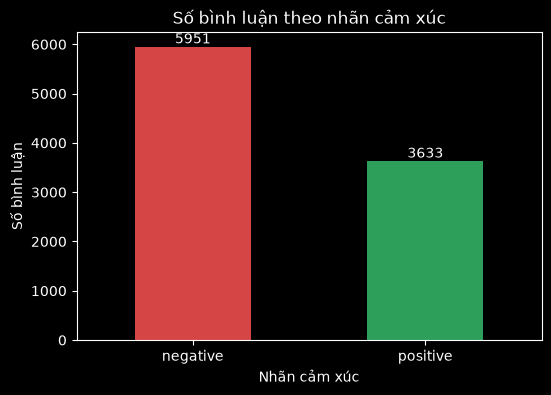

In [194]:
so_luong_nhan = df['label'].value_counts()
ds_mau = [BANG_MAU_NHAN[nhan] for nhan in so_luong_nhan.index]
ax = so_luong_nhan.plot(kind='bar', figsize=(6, 4), color=ds_mau, rot=0)
ax.bar_label(ax.containers[0])
plt.title("Số bình luận theo nhãn cảm xúc")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số bình luận")
plt.show()

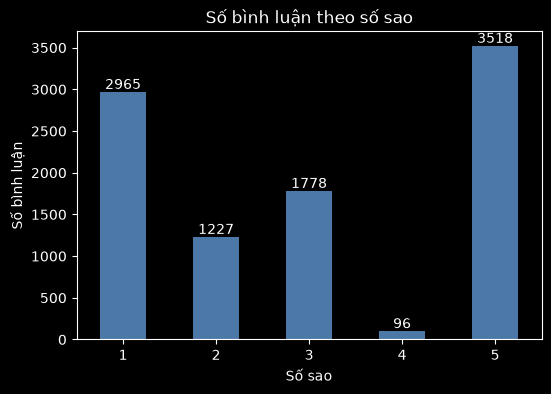

In [195]:
so_luong_sao = df['rating'].value_counts().sort_index()
ax = so_luong_sao.plot(kind='bar', figsize=(6, 4), color=MAU_CHUNG, rot=0)
ax.bar_label(ax.containers[0])
plt.title("Số bình luận theo số sao")
plt.xlabel("Số sao")
plt.ylabel("Số bình luận")
plt.show()

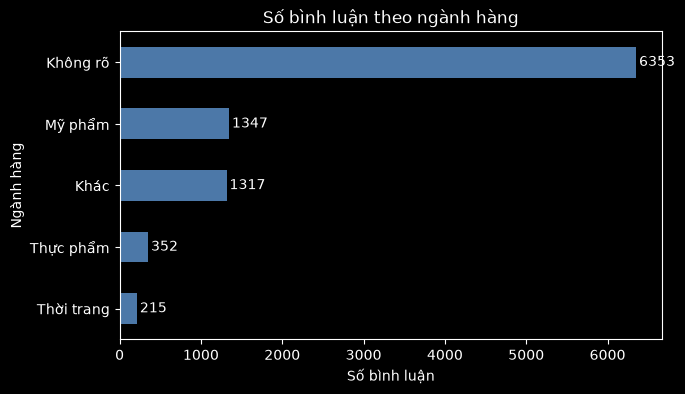

In [196]:
so_luong_nganh = df['nganh_hang'].value_counts().sort_values()
ax = so_luong_nganh.plot(kind='barh', figsize=(7, 4), color=MAU_CHUNG)
ax.bar_label(ax.containers[0], padding=2)
plt.title("Số bình luận theo ngành hàng")
plt.xlabel("Số bình luận")
plt.ylabel("Ngành hàng")
plt.show()

In [197]:
## 3. Biểu đồ cột ghép - crosstab, groupby, plot(kind='bar')

In [198]:
bang_sao_nhan = pd.crosstab(df['rating'], df['label'], normalize='index') * 100
bang_sao_nhan.round(1)

label,negative,positive
rating,,
1,99.5,0.5
2,99.3,0.7
3,94.9,5.1
4,30.2,69.8
5,1.9,98.1


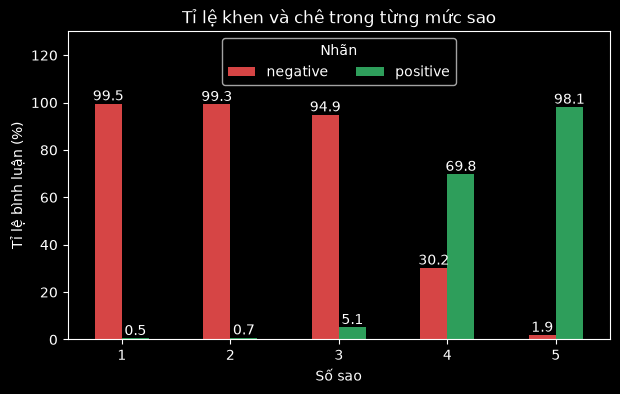

In [199]:
ax = bang_sao_nhan.plot(kind='bar', figsize=(7, 4), color=BANG_MAU_NHAN, rot=0)
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot, fmt='%.1f')
plt.title("Tỉ lệ khen và chê trong từng mức sao")
plt.xlabel("Số sao")
plt.ylabel("Tỉ lệ bình luận (%)")
plt.ylim(0, 130)
plt.legend(title="Nhãn", loc='upper center', ncol=2)
plt.show()

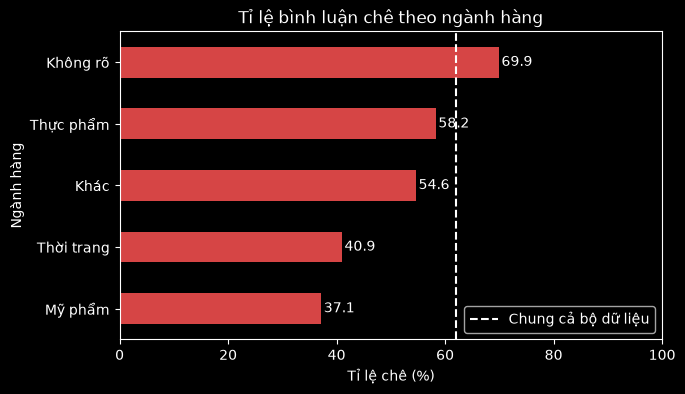

In [200]:
df['la_che'] = (df['label'] == NHAN_TIEU_CUC) * 100
ti_le_che_chung = df['la_che'].mean()
ti_le_che_nganh = df.groupby('nganh_hang')['la_che'].mean().sort_values()
ax = ti_le_che_nganh.plot(kind='barh', figsize=(7, 4), color=MAU_TIEU_CUC)
ax.bar_label(ax.containers[0], fmt='%.1f', padding=2)
duong_chung = plt.axvline(ti_le_che_chung, color=MAU_NET, linestyle='--', label="Chung cả bộ dữ liệu")
plt.title("Tỉ lệ bình luận chê theo ngành hàng")
plt.xlabel("Tỉ lệ chê (%)")
plt.ylabel("Ngành hàng")
plt.xlim(0, 100)
plt.legend(handles=[duong_chung], loc='lower right')
plt.show()

In [201]:
df.groupby('nganh_hang')['la_che'].mean().sort_values(ascending=False).round(1)

nganh_hang
Không rõ      69.9
Thực phẩm     58.2
Khác          54.6
Thời trang    40.9
Mỹ phẩm       37.1
Name: la_che, dtype: float64

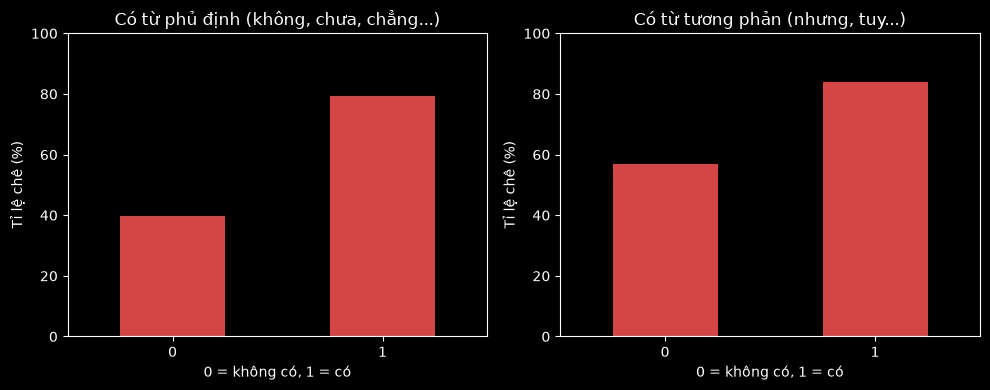

In [202]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
df.groupby('co_phu_dinh')['la_che'].mean().plot(kind='bar', color=MAU_TIEU_CUC, rot=0, ax=axs[0])
axs[0].set_title("Có từ phủ định (không, chưa, chẳng...)")
axs[0].set_xlabel("0 = không có, 1 = có")
axs[0].set_ylabel("Tỉ lệ chê (%)")
axs[0].set_ylim(0, 100)
df.groupby('co_tuong_phan')['la_che'].mean().plot(kind='bar', color=MAU_TIEU_CUC, rot=0, ax=axs[1])
axs[1].set_title("Có từ tương phản (nhưng, tuy...)")
axs[1].set_xlabel("0 = không có, 1 = có")
axs[1].set_ylabel("Tỉ lệ chê (%)")
axs[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [203]:
print(df.groupby('co_phu_dinh')['la_che'].agg(['count', 'mean']).round(1))
print(df.groupby('co_tuong_phan')['la_che'].agg(['count', 'mean']).round(1))

             count  mean
co_phu_dinh             
0             4190  39.7
1             5394  79.5
               count  mean
co_tuong_phan             
0               7721  56.9
1               1863  83.8


In [204]:
## 4. Biểu đồ tần suất - plot(kind='hist')

200 bình luận dài hơn 100 từ không được vẽ


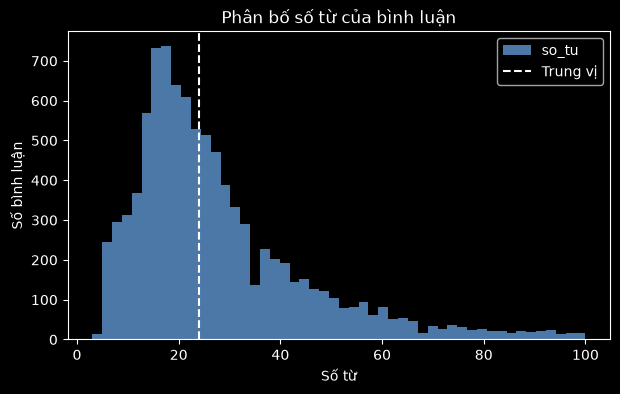

In [205]:
df_ve = df[df['so_tu'] <= 100]
print(len(df) - len(df_ve), "bình luận dài hơn 100 từ không được vẽ")
df_ve['so_tu'].plot(kind='hist', bins=50, figsize=(7, 4), color=MAU_CHUNG)
plt.axvline(df['so_tu'].median(), color=MAU_NET, linestyle='--', label="Trung vị")
plt.title("Phân bố số từ của bình luận")
plt.xlabel("Số từ")
plt.ylabel("Số bình luận")
plt.legend()
plt.show()

In [206]:
df['so_tu'].describe().round(1)

count    9584.0
mean       30.2
std        24.9
min         3.0
25%        16.0
50%        24.0
75%        36.0
max       444.0
Name: so_tu, dtype: float64

In [207]:
## 5. Biểu đồ hộp - boxplot

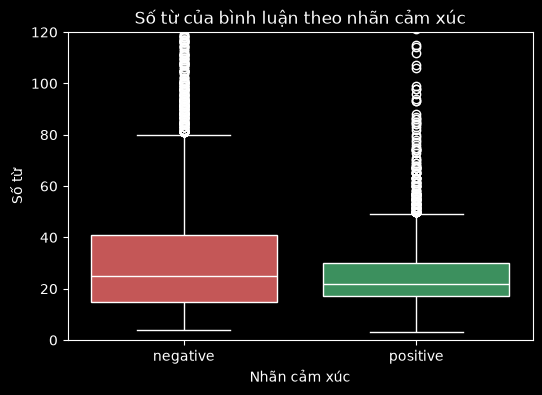

In [208]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='label', y='so_tu', hue='label', palette=BANG_MAU_NHAN, linecolor=MAU_NET)
plt.title("Số từ của bình luận theo nhãn cảm xúc")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số từ")
plt.ylim(0, 120)
plt.show()

In [209]:
df.groupby('label')['so_tu'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,5951.0,33.3,29.3,4.0,15.0,25.0,41.0,444.0
positive,3633.0,25.2,13.9,3.0,17.0,22.0,30.0,241.0


# PHẦN 4 – Phân tích thăm dò (slide Bài 5)

In [210]:
## 1. Chuẩn bị - import, đọc dữ liệu

In [211]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import seaborn as sns

In [212]:
df = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df.shape

(9584, 36)

In [213]:
## 2. Thống kê mô tả - describe, mean, median, mode, skew

In [214]:
df[['so_tu', 'so_ky_tu', 'rating']].describe().round(2)

,so_tu,so_ky_tu,rating
count,9584.00,9584.00,9584.00
mean,30.22,133.95,3.00
std,24.94,109.20,1.69
min,3.00,20.00,1.00
25%,16.00,71.00,1.00
50%,24.00,106.00,3.00
75%,36.00,159.00,5.00
max,444.00,2021.00,5.00


In [215]:
print("Trung bình:", round(df['so_tu'].mean(), 2))
print("Trung vị:", df['so_tu'].median())
print("Yếu vị:", df['so_tu'].mode()[0])
print("Độ lệch (skew):", round(df['so_tu'].skew(), 2))

Trung bình: 30.22
Trung vị: 24.0
Yếu vị: 16
Độ lệch (skew): 3.77


In [216]:
q1 = df['so_tu'].quantile(0.25)
q3 = df['so_tu'].quantile(0.75)
iqr = q3 - q1
nguong_ngoai_le = q3 + 1.5 * iqr
print(q1, q3, iqr, nguong_ngoai_le)
print((df['so_tu'] > nguong_ngoai_le).sum())

16.0 36.0 20.0 66.0
609


In [217]:
## 3. Tương quan - corr, pearsonr, heatmap, regplot

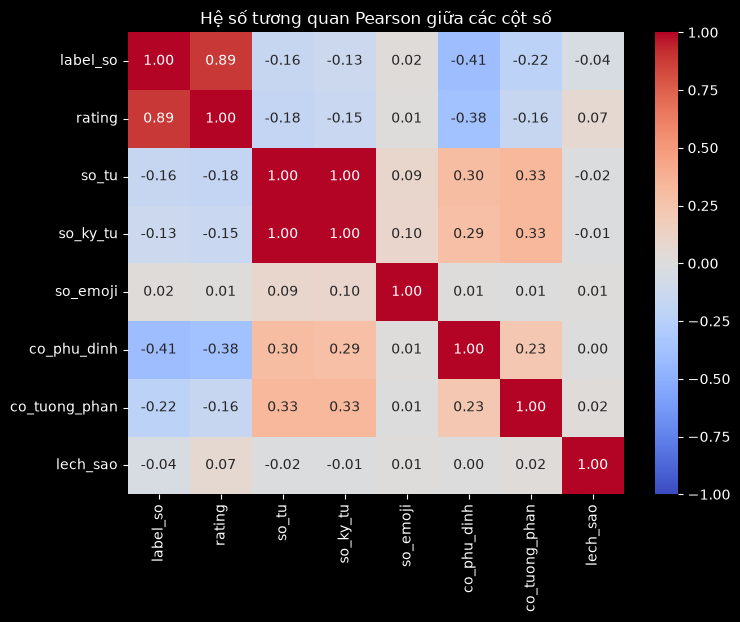

In [218]:
ds_cot_so = ['label_so', 'rating', 'so_tu', 'so_ky_tu', 'so_emoji', 'co_phu_dinh', 'co_tuong_phan', 'lech_sao']
bang_tuong_quan = df[ds_cot_so].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(bang_tuong_quan, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Hệ số tương quan Pearson giữa các cột số")
plt.show()

In [219]:
ds_dong = []
for ten_cot in ['rating', 'so_tu', 'so_ky_tu', 'so_emoji', 'co_phu_dinh', 'co_tuong_phan']:
    he_so, p_value = stats.pearsonr(df[ten_cot], df['label_so'])
    ds_dong.append({'cot': ten_cot, 'he_so_pearson': round(he_so, 3), 'p_value': p_value})
pd.DataFrame(ds_dong)

,cot,he_so_pearson,p_value
0,rating,0.886,0.000000e+00
1,so_tu,-0.156,1.628203e-53
2,so_ky_tu,-0.125,9.333154e-35
3,so_emoji,0.017,8.919903e-02
4,co_phu_dinh,-0.407,0.000000e+00
5,co_tuong_phan,-0.220,4.539972e-105


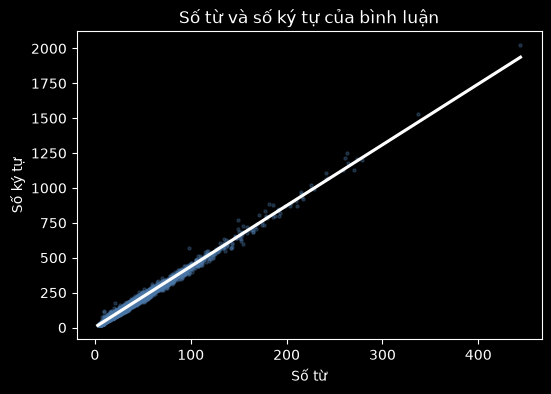

In [220]:
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='so_tu', y='so_ky_tu', scatter_kws={'s': 5, 'alpha': 0.3}, line_kws={'color': MAU_NET}, color=MAU_CHUNG)
plt.title("Số từ và số ký tự của bình luận")
plt.xlabel("Số từ")
plt.ylabel("Số ký tự")
plt.show()

In [221]:
he_so, p_value = stats.pearsonr(df['so_tu'], df['so_ky_tu'])
print("Hệ số Pearson:", round(he_so, 3))
print("p-value:", p_value)

Hệ số Pearson: 0.995
p-value: 0.0


In [222]:
## 4. Gom nhóm - groupby, pivot

In [223]:
df.groupby('rating')['so_tu'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
rating,,,
1,2965,35.7,26.0
2,1227,32.5,25.0
3,1778,29.5,24.0
4,96,34.6,27.0
5,3518,25.1,22.0


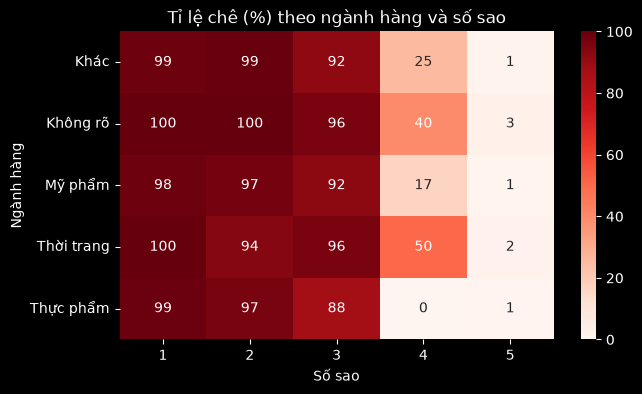

In [224]:
df['la_che'] = (df['label'] == NHAN_TIEU_CUC) * 100
bang_nganh_sao = df.pivot_table(index='nganh_hang', columns='rating', values='la_che', aggfunc='mean')
plt.figure(figsize=(7, 4))
sns.heatmap(bang_nganh_sao, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100)
plt.title("Tỉ lệ chê (%) theo ngành hàng và số sao")
plt.xlabel("Số sao")
plt.ylabel("Ngành hàng")
plt.show()

In [225]:
pd.crosstab(df['nganh_hang'], df['rating'])

rating,1,2,3,4,5
nganh_hang,,,,,
Khác,347,149,237,16,568
Không rõ,2284,901,1242,48,1878
Mỹ phẩm,199,102,209,18,819
Thời trang,43,16,26,6,124
Thực phẩm,92,59,64,8,129


In [226]:
## 5. Kiểm định ANOVA - f_oneway

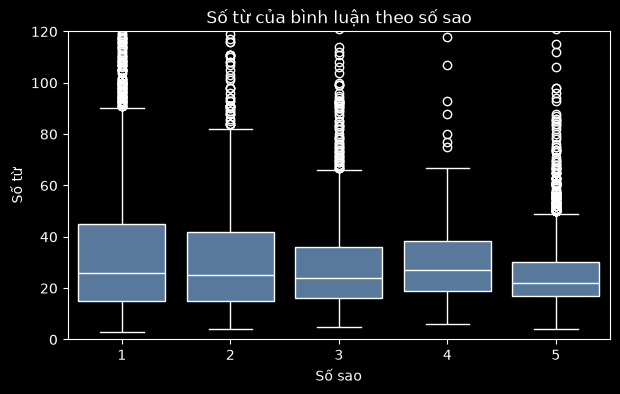

In [227]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='rating', y='so_tu', color=MAU_CHUNG, linecolor=MAU_NET)
plt.title("Số từ của bình luận theo số sao")
plt.xlabel("Số sao")
plt.ylabel("Số từ")
plt.ylim(0, 120)
plt.show()

In [228]:
ds_nhom = [df[df['rating'] == so_sao]['so_tu'] for so_sao in [1, 2, 3, 4, 5]]
f1, p_value = stats.f_oneway(ds_nhom[0], ds_nhom[1], ds_nhom[2], ds_nhom[3], ds_nhom[4])
print("Giá trị thống kê F:", f1)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Có sự khác biệt có ý nghĩa thống kê về số từ giữa các mức sao.")
else:
    print("Không có sự khác biệt có ý nghĩa thống kê về số từ giữa các mức sao.")

Giá trị thống kê F: 78.7931045762348
p-value: 7.067637584781593e-66
Có sự khác biệt có ý nghĩa thống kê về số từ giữa các mức sao.


In [229]:
f1, p_value = stats.f_oneway(df[df['label'] == NHAN_TICH_CUC]['so_tu'],
                             df[df['label'] == NHAN_TIEU_CUC]['so_tu'])
print("Giá trị thống kê F:", f1)
print("p-value:", p_value)
if p_value < alpha:
    print("Có sự khác biệt có ý nghĩa thống kê về số từ giữa hai nhãn.")
else:
    print("Không có sự khác biệt có ý nghĩa thống kê về số từ giữa hai nhãn.")

Giá trị thống kê F: 240.14256534457598
p-value: 1.6282034687181303e-53
Có sự khác biệt có ý nghĩa thống kê về số từ giữa hai nhãn.


In [230]:
ds_nhom = [df[df['nganh_hang'] == nganh]['label_so'] for nganh in df['nganh_hang'].unique()]
f1, p_value = stats.f_oneway(ds_nhom[0], ds_nhom[1], ds_nhom[2], ds_nhom[3], ds_nhom[4])
print("Giá trị thống kê F:", f1)
print("p-value:", p_value)
if p_value < alpha:
    print("Có sự khác biệt có ý nghĩa thống kê về tỉ lệ khen giữa các ngành hàng.")
else:
    print("Không có sự khác biệt có ý nghĩa thống kê về tỉ lệ khen giữa các ngành hàng.")

Giá trị thống kê F: 158.47436080656533
p-value: 1.5438065486205506e-131
Có sự khác biệt có ý nghĩa thống kê về tỉ lệ khen giữa các ngành hàng.


# PHẦN 5 – Xây dựng mô hình phân loại cảm xúc (slide Bài 6)

In [231]:
## 1. Chuẩn bị dữ liệu - train_test_split

In [232]:
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [233]:
df = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df.shape

(9584, 36)

In [234]:
x_data = df['noi_dung_sach']
y_data = df['label']

In [235]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data,
                                                    test_size=TI_LE_TEST,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y_data)

In [236]:
print(len(x_train))
print(len(x_test))

6708
2876


In [237]:
y_train.value_counts(normalize=True).round(3)

label
negative    0.621
positive    0.379
Name: proportion, dtype: float64

In [238]:
y_test.value_counts(normalize=True).round(3)

label
negative    0.621
positive    0.379
Name: proportion, dtype: float64

In [239]:
## 2. Đổi văn bản thành số - TF-IDF

In [240]:
ds_cau = ['hàng đẹp', 'hàng không đẹp', 'giao hàng nhanh']
tfidf_vi_du = TfidfVectorizer()
ma_tran_vi_du = tfidf_vi_du.fit_transform(ds_cau)

In [241]:
pd.DataFrame(ma_tran_vi_du.toarray().round(4), columns=tfidf_vi_du.get_feature_names_out(), index=ds_cau)

,giao,hàng,không,nhanh,đẹp
hàng đẹp,0.0000,0.6134,0.0000,0.0000,0.7898
hàng không đẹp,0.0000,0.4254,0.7203,0.0000,0.5478
giao hàng nhanh,0.6525,0.3854,0.0000,0.6525,0.0000


In [242]:
pd.Series(tfidf_vi_du.idf_.round(4), index=tfidf_vi_du.get_feature_names_out())

giao     1.6931
hàng     1.0000
không    1.6931
nhanh    1.6931
đẹp      1.2877
dtype: float64

In [243]:
tfidf_vi_du_2 = TfidfVectorizer(ngram_range=(1, 2))
tfidf_vi_du_2.fit(ds_cau)
list(tfidf_vi_du_2.get_feature_names_out())

['giao',
 'giao hàng',
 'hàng',
 'hàng không',
 'hàng nhanh',
 'hàng đẹp',
 'không',
 'không đẹp',
 'nhanh',
 'đẹp']

In [244]:
tfidf = TfidfVectorizer(ngram_range=NGRAM_RANGE, min_df=MIN_DF, sublinear_tf=SUBLINEAR_TF)
ma_tran_train = tfidf.fit_transform(x_train)
ma_tran_train.shape

(6708, 21740)

In [245]:
## 3. Huấn luyện 3 mô hình phân loại - Pipeline

In [246]:
pipe_nb = tao_pipeline_phan_loai(MultinomialNB())
pipe_nb.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](2,)","['negative','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [247]:
pipe_lr = tao_pipeline_phan_loai(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced'))
pipe_lr.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [248]:
pipe_svc = tao_pipeline_phan_loai(LinearSVC(class_weight='balanced'))
pipe_svc.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [249]:
## 4. Đánh giá mô hình - accuracy, precision, recall, F1, confusion matrix

In [250]:
y_du_doan_lr = pipe_lr.predict(x_test)
y_du_doan_lr[:5]

array(['positive', 'negative', 'negative', 'negative', 'negative'],
      dtype=object)

In [251]:
accuracy_score(y_test, y_du_doan_lr)

0.9374130737134909

In [252]:
ds_nhan = [NHAN_TIEU_CUC, NHAN_TICH_CUC]
ma_tran_lr = confusion_matrix(y_test, y_du_doan_lr, labels=ds_nhan)
pd.DataFrame(ma_tran_lr, index=['Thật: negative', 'Thật: positive'], columns=['Đoán: negative', 'Đoán: positive'])

,Đoán: negative,Đoán: positive
Thật: negative,1680,106
Thật: positive,74,1016


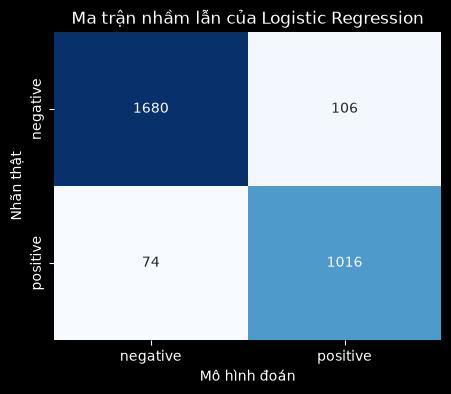

In [253]:
plt.figure(figsize=(5, 4))
sns.heatmap(ma_tran_lr, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=ds_nhan, yticklabels=ds_nhan)
plt.title("Ma trận nhầm lẫn của Logistic Regression")
plt.xlabel("Mô hình đoán")
plt.ylabel("Nhãn thật")
plt.show()

In [254]:
print(classification_report(y_test, y_du_doan_lr, digits=4))

              precision    recall  f1-score   support

    negative     0.9578    0.9406    0.9492      1786
    positive     0.9055    0.9321    0.9186      1090

    accuracy                         0.9374      2876
   macro avg     0.9317    0.9364    0.9339      2876
weighted avg     0.9380    0.9374    0.9376      2876



In [255]:
ds_ket_qua = []
ds_ket_qua.append(danh_gia_mo_hinh('Naive Bayes', pipe_nb, x_train, y_train, x_test, y_test))
ds_ket_qua.append(danh_gia_mo_hinh('Logistic Regression', pipe_lr, x_train, y_train, x_test, y_test))
ds_ket_qua.append(danh_gia_mo_hinh('Linear SVC', pipe_svc, x_train, y_train, x_test, y_test))
bang_so_sanh = pd.DataFrame(ds_ket_qua)
bang_so_sanh

,Mô hình,Accuracy train,Accuracy test,F1 negative,F1 positive,Macro-F1
0,Naive Bayes,0.9647,0.9332,0.9470,0.9099,0.9285
1,Logistic Regression,0.9694,0.9374,0.9492,0.9186,0.9339
2,Linear SVC,0.9984,0.9499,0.9596,0.9342,0.9469


In [256]:
print(confusion_matrix(y_test, pipe_nb.predict(x_test), labels=ds_nhan))
print(confusion_matrix(y_test, pipe_svc.predict(x_test), labels=ds_nhan))

[[1714   72]
 [ 120  970]]
[[1709   77]
 [  67 1023]]


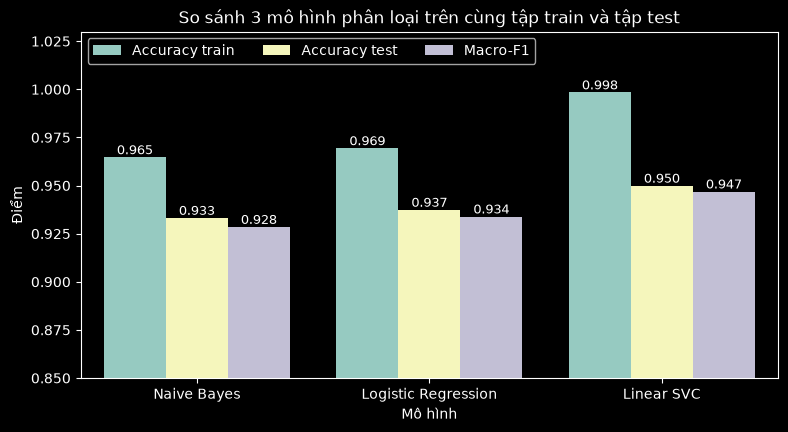

In [257]:
bang_ve = bang_so_sanh.melt(id_vars='Mô hình', value_vars=['Accuracy train', 'Accuracy test', 'Macro-F1'],
                            var_name='Thang đo', value_name='Điểm')
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=bang_ve, x='Mô hình', y='Điểm', hue='Thang đo')
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot, fmt='%.3f', fontsize=9)
plt.title("So sánh 3 mô hình phân loại trên cùng tập train và tập test")
plt.xlabel("Mô hình")
plt.ylabel("Điểm")
plt.ylim(0.85, 1.03)
plt.legend(loc='upper left', ncol=3)
plt.show()

In [258]:
lay_tu_quan_trong(pipe_lr, 10)

,Từ kéo về tiêu cực,Hệ số âm,Từ kéo về tích cực,Hệ số dương
0,không,-6.52,nhanh,5.19
1,bị,-3.88,tốt,4.39
2,mà,-3.54,ok,4.14
3,nhưng,-3.32,thơm,4.10
4,như,-3.07,không bị,4.02
5,tệ,-3.06,đẹp,3.69
6,ra,-2.87,hàng nhanh,3.48
7,hộp,-2.81,nha,3.23
8,thì,-2.78,da,3.12
9,móp,-2.63,thích,2.87


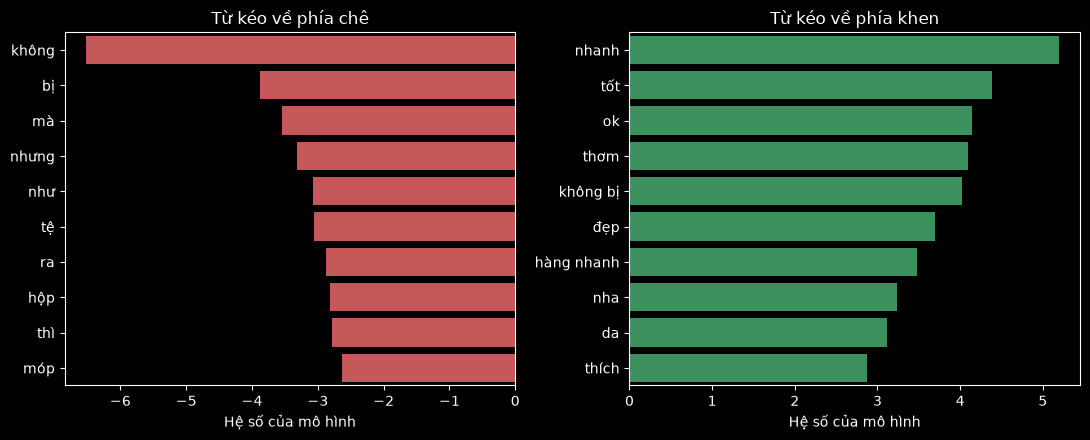

In [259]:
bang_tu = lay_tu_quan_trong(pipe_lr, 10)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(data=bang_tu, x='Hệ số âm', y='Từ kéo về tiêu cực', color=MAU_TIEU_CUC, ax=axs[0])
axs[0].set_title("Từ kéo về phía chê")
axs[0].set_xlabel("Hệ số của mô hình")
axs[0].set_ylabel("")
sns.barplot(data=bang_tu, x='Hệ số dương', y='Từ kéo về tích cực', color=MAU_TICH_CUC, ax=axs[1])
axs[1].set_title("Từ kéo về phía khen")
axs[1].set_xlabel("Hệ số của mô hình")
axs[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [260]:
## 5. Phân tích lỗi

In [261]:
df_test = df.loc[x_test.index, ['noi_dung_sach', 'rating', 'label', 'co_tuong_phan']].copy()
df_test['du_doan'] = y_du_doan_lr
df_test['xac_suat'] = tinh_xac_suat_tich_cuc(pipe_lr, x_test)

In [262]:
df_sai = df_test[df_test['label'] != df_test['du_doan']]
len(df_sai)

180

In [263]:
pd.set_option('display.max_colwidth', 160)
df_sai[['noi_dung_sach', 'rating', 'label', 'du_doan', 'xac_suat']].head(20)

,noi_dung_sach,rating,label,du_doan,xac_suat
3868,sản phẩm nhận được giống như hình ảnh shop đã đăng tải mút mềm,5,positive,negative,0.499975
4691,giao hang nhâh dong goi can than dung bi kich ung ca 2 người bi zz,2,negative,positive,0.543142
3680,thùng 48 bịch sữa tiệt trùng dutch lady cô gái hà lan không đường 180ml 48x180ml ung ho lan sau đóng gói ok,5,positive,negative,0.432879
8382,đóng gói ok khá kĩ mình mua thấy giá khá đắt nha gần 200k cho 200g với tác dụng ngăn ngừa gàu nấm thì mình thấy cũng gọi là ổn mình gội trộm vía ít gàu hơn ...,3,negative,positive,0.589249
1945,muốn mềm hơn thì sử dụng ttbc của loại khác của cocoon thơm mùi cafe lần đầu mua thì dùng rất thik mua lần 2 thì chán quó tẩy nó cứ tượt,3,negative,positive,0.674651
4533,mùi thơm nhưng mà khi sấy tóc xong thì không còn mùi dùng 3 lần rồi nhưng chưa thấy mềm mượt hơn tí nào,5,positive,negative,0.470497
7996,thơm sach gau cung mem toc giao hàng nhanh shipper nhiệt tình đóng gói cẩn thận giao hàng hộp hơi móp méo,2,negative,positive,0.834983
1108,tốt tốt kém,1,negative,positive,0.742930
8909,moi dùng 2 lần nên chưa biết thoa lên thấy không nâng tone mùi thơm nhẹ dễ chịu nếu thao lên nâng tone nữa thì tuyệt vời dùng thêm ban đêm nếu hiệu quả sẽ ủ...,3,negative,positive,0.920293
8578,túi đẹp hy vọng bền nói chung tạm thời chưa có điểm gì không hài lòng,5,positive,negative,0.432127


In [264]:
df_dung = df_test[df_test['label'] == df_test['du_doan']]
print(round(df_sai['co_tuong_phan'].mean(), 3))
print(round(df_dung['co_tuong_phan'].mean(), 3))

0.317
0.182


In [265]:
ti_le_sai = df_sai['rating'].value_counts().sort_index() / df_test['rating'].value_counts().sort_index()
ti_le_sai.round(3)

rating
1    0.027
2    0.073
3    0.096
4    0.290
5    0.067
Name: count, dtype: float64

In [266]:
## 6. Tạo nhãn Trung lập bằng ngưỡng xác suất

In [267]:
df_test[['noi_dung_sach', 'label', 'xac_suat']].head(5)

,noi_dung_sach,label,xac_suat
4178,làm sach da thoa du len da không mui giao hàng nhanh đóng gói cẩn thận khá ưng ý với sản phẩm của shop,positive,0.968099
339,chống nắng chưa sử dụng mua trên live nói là được tặng túi nhưng không thấy túi đâu nhỉ hay là mình bị nhầm lẫn ở đây,negative,0.087066
1411,mình không hiểu vì sao vẫn có người đánh giá 5 sao shop làm ăn quá tệ bán đồ cho em bé mà vậy đóng hàng rất kỹ đây là cố tình giao hộp sữa móp méo cho khách...,negative,0.036064
3848,ok ok hộp bị móp,negative,0.258925
923,ok đã mua lần 2 vào trang chính hãng đặt nhận hàng chỉ còn hai tháng hàng date ngắn không được thông báo không hài lòng với hàng cận date cần thông báo rõ t...,negative,0.296801


In [268]:
print(gan_nhan(0.94))
print(gan_nhan(0.47))
print(gan_nhan(0.02))

Tích cực
Trung lập
Tiêu cực


In [269]:
print(gan_nhan(0.80))
print(gan_nhan(0.81))
print(gan_nhan(0.20))
print(gan_nhan(0.19))

Trung lập
Tích cực
Trung lập
Tiêu cực


In [270]:
bins = np.linspace(0, 1, 11)
khoang_xac_suat = pd.cut(df_test['xac_suat'], bins, include_lowest=True)
khoang_xac_suat.value_counts().sort_index()

xac_suat
(-0.001, 0.1]    873
(0.1, 0.2]       404
(0.2, 0.3]       238
(0.3, 0.4]       137
(0.4, 0.5]       102
(0.5, 0.6]        90
(0.6, 0.7]       110
(0.7, 0.8]       144
(0.8, 0.9]       248
(0.9, 1.0]       530
Name: count, dtype: int64

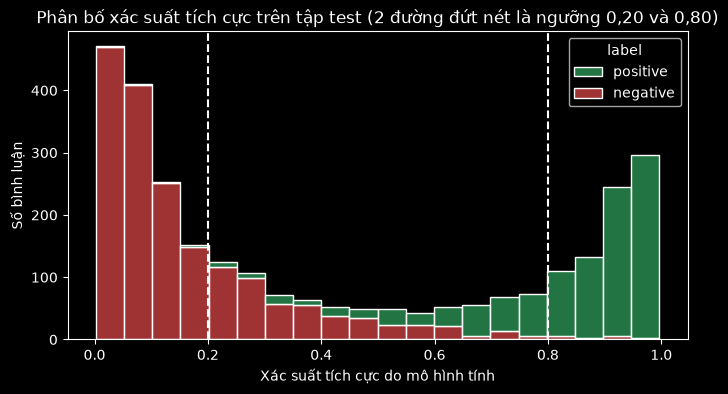

In [271]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df_test, x='xac_suat', hue='label', palette=BANG_MAU_NHAN, bins=20, multiple='stack')
plt.axvline(NGUONG_DUOI, color=MAU_NET, linestyle='--')
plt.axvline(NGUONG_TREN, color=MAU_NET, linestyle='--')
plt.title("Phân bố xác suất tích cực trên tập test (2 đường đứt nét là ngưỡng 0,20 và 0,80)")
plt.xlabel("Xác suất tích cực do mô hình tính")
plt.ylabel("Số bình luận")
plt.show()

In [272]:
ds_thong_ke = []
for nguong_duoi, nguong_tren in DS_CAP_NGUONG:
    ds_thong_ke.append(thong_ke_nguong(df_test['xac_suat'], df_test['label'], nguong_duoi, nguong_tren))
pd.DataFrame(ds_thong_ke)

,Ngưỡng dưới,Ngưỡng trên,% Tiêu cực,% Trung lập,% Tích cực,Accuracy ngoài vùng Trung lập,Số câu sai rơi vào Trung lập
0,0.4,0.6,57.4,6.7,35.9,0.9616,77
1,0.3,0.7,52.7,15.3,32.1,0.9778,126
2,0.2,0.8,44.4,28.5,27.1,0.9898,159


In [273]:
df_test['nhan_3_lop'] = df_test['xac_suat'].apply(gan_nhan)
df_test['nhan_3_lop'].value_counts()

nhan_3_lop
Tiêu cực     1277
Trung lập     821
Tích cực      778
Name: count, dtype: int64

In [274]:
pd.crosstab(df_test['rating'], df_test['nhan_3_lop'], normalize='index').round(3)

nhan_3_lop,Tiêu cực,Trung lập,Tích cực
rating,,,
1,0.789,0.210,0.001
2,0.704,0.280,0.016
3,0.554,0.395,0.051
4,0.226,0.484,0.290
5,0.011,0.293,0.696


In [275]:
pd.crosstab(df_test['rating'], df_test['nhan_3_lop'])

nhan_3_lop,Tiêu cực,Trung lập,Tích cực
rating,,,
1,714,190,1
2,261,104,6
3,283,202,26
4,7,15,9
5,12,310,736


In [276]:
## 7. Lưu mô hình và thử dự đoán

In [277]:
os.makedirs('../mo_hinh', exist_ok=True)
ds_file_da_luu = joblib.dump(pipe_lr, '../mo_hinh/mo_hinh.joblib')
os.path.exists('../mo_hinh/mo_hinh.joblib')

True

In [278]:
mo_hinh = joblib.load('../mo_hinh/mo_hinh.joblib')
(mo_hinh.predict(x_test) == y_du_doan_lr).all()

np.True_

In [279]:
ds_binh_luan_mau = [
    'Hàng đẹp, giao nhanh, shop nhiệt tình',
    'Giao sai màu, nhắn shop ko trả lời',
    'Son lên màu đẹp, mỗi tội hơi khô môi',
    'Sp tốt nhưng giao hàng hơi lâu',
    'Bình thường, không có gì đặc biệt',
]

In [280]:
ds_du_doan = [du_doan(binh_luan, mo_hinh) for binh_luan in ds_binh_luan_mau]
bang_du_doan = pd.DataFrame(ds_du_doan)
bang_du_doan['binh_luan'] = ds_binh_luan_mau
bang_du_doan[['binh_luan', 'noi_dung_da_lam_sach', 'xac_suat_tich_cuc', 'nhan']]

,binh_luan,noi_dung_da_lam_sach,xac_suat_tich_cuc,nhan
0,"Hàng đẹp, giao nhanh, shop nhiệt tình",hàng đẹp giao nhanh shop nhiệt tình,0.9544,Tích cực
1,"Giao sai màu, nhắn shop ko trả lời",giao sai màu nhắn shop không trả lời,0.0505,Tiêu cực
2,"Son lên màu đẹp, mỗi tội hơi khô môi",son lên màu đẹp mỗi tội hơi khô môi,0.4509,Trung lập
3,Sp tốt nhưng giao hàng hơi lâu,sản phẩm tốt nhưng giao hàng hơi lâu,0.4645,Trung lập
4,"Bình thường, không có gì đặc biệt",bình thường không có gì đặc biệt,0.0791,Tiêu cực


# PHẦN 6 – Đánh giá và tinh chỉnh mô hình (slide Bài 7)

In [281]:
## 1. Chuẩn bị - import, đọc dữ liệu, chia train/test

In [282]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [283]:
df = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df.shape

(9584, 36)

In [284]:
x_data = df['noi_dung_sach']
y_data = df['label']

In [285]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data,
                                                    test_size=TI_LE_TEST,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y_data)

In [286]:
lr = tao_pipeline_phan_loai(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced'))
lr.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [287]:
## 2. Đánh giá trên tập train và tập test - score

In [288]:
diem_train = lr.score(x_train, y_train)
diem_test = lr.score(x_test, y_test)
print("Điểm trên tập train:", round(diem_train, 4))
print("Điểm trên tập test:", round(diem_test, 4))

Điểm trên tập train: 0.9694
Điểm trên tập test: 0.9374


In [289]:
round(diem_train - diem_test, 4)

0.032

In [290]:
## 3. Kiểm chứng chéo - cross_val_score, cross_val_predict

In [291]:
scores = cross_val_score(lr, x_data, y_data, cv=SO_FOLD)
scores.round(4)

array([0.9296, 0.9421, 0.9463, 0.9364, 0.9384])

In [292]:
print("Trung bình:", round(np.mean(scores), 4))
print("Độ lệch chuẩn:", round(np.std(scores), 4))

Trung bình: 0.9385
Độ lệch chuẩn: 0.0056


In [293]:
bang_cv = []
for so_phan in [3, 5, 10]:
    scores_thu = cross_val_score(lr, x_data, y_data, cv=so_phan)
    bang_cv.append([so_phan, round(np.mean(scores_thu), 4), round(np.std(scores_thu), 4)])
pd.DataFrame(bang_cv, columns=['Số phần (cv)', 'Accuracy trung bình', 'Độ lệch chuẩn'])

,Số phần (cv),Accuracy trung bình,Độ lệch chuẩn
0,3,0.9375,0.0043
1,5,0.9385,0.0056
2,10,0.9398,0.0085


In [294]:
scores_f1 = cross_val_score(lr, x_data, y_data, cv=SO_FOLD, scoring='f1_macro')
print(scores_f1.round(4))
print("Trung bình:", round(np.mean(scores_f1), 4))

[0.9256 0.9387 0.9433 0.9329 0.9349]
Trung bình: 0.9351


In [295]:
y_du_doan_cv = cross_val_predict(lr, x_data, y_data, cv=SO_FOLD)
y_du_doan_cv[:5]

array(['negative', 'positive', 'positive', 'positive', 'negative'],
      dtype=object)

In [296]:
ds_nhan = [NHAN_TIEU_CUC, NHAN_TICH_CUC]
ma_tran_cv = confusion_matrix(y_data, y_du_doan_cv, labels=ds_nhan)
pd.DataFrame(ma_tran_cv, index=['Thật: negative', 'Thật: positive'], columns=['Đoán: negative', 'Đoán: positive'])

,Đoán: negative,Đoán: positive
Thật: negative,5601,350
Thật: positive,239,3394


In [297]:
round(accuracy_score(y_data, y_du_doan_cv), 4)

0.9385

In [298]:
## 4. Overfitting - Underfitting - tham số điều chuẩn C

In [299]:
ds_c = np.logspace(-3, 3, 7)
ds_c

array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])

In [300]:
bang_c = []
for c in ds_c:
    mo_hinh_thu = tao_pipeline_phan_loai(LogisticRegression(C=c, max_iter=MAX_ITER, class_weight='balanced'))
    mo_hinh_thu.fit(x_train, y_train)
    diem_train_thu = mo_hinh_thu.score(x_train, y_train)
    diem_test_thu = mo_hinh_thu.score(x_test, y_test)
    bang_c.append([c, round(diem_train_thu, 4), round(diem_test_thu, 4), round(diem_train_thu - diem_test_thu, 4)])
pd.DataFrame(bang_c, columns=['C', 'Điểm train', 'Điểm test', 'Chênh lệch'])

,C,Điểm train,Điểm test,Chênh lệch
0,0.001,0.9088,0.9033,0.0054
1,0.010,0.9138,0.9082,0.0056
2,0.100,0.9347,0.9190,0.0157
3,1.000,0.9694,0.9374,0.0320
4,10.000,0.9966,0.9475,0.0491
5,100.000,0.9958,0.9451,0.0508
6,1000.000,0.9985,0.9468,0.0517


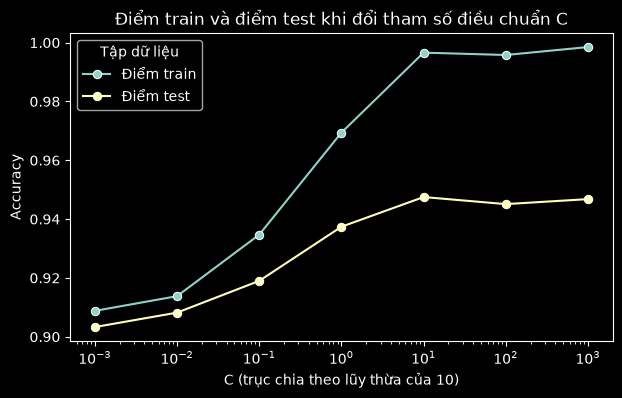

In [301]:
bang_c_ve = pd.DataFrame(bang_c, columns=['C', 'Điểm train', 'Điểm test', 'Chênh lệch'])
bang_c_ve = bang_c_ve.melt(id_vars='C', value_vars=['Điểm train', 'Điểm test'],
                           var_name='Tập dữ liệu', value_name='Accuracy')
plt.figure(figsize=(7, 4))
sns.lineplot(data=bang_c_ve, x='C', y='Accuracy', hue='Tập dữ liệu', marker='o')
plt.xscale('log')
plt.title("Điểm train và điểm test khi đổi tham số điều chuẩn C")
plt.xlabel("C (trục chia theo lũy thừa của 10)")
plt.ylabel("Accuracy")
plt.show()

In [302]:
## 5. Tìm tham số tốt nhất - GridSearchCV

In [303]:
parameters = {'mo_hinh__C': [0.1, 1, 10, 100],
              'tfidf__ngram_range': [(1, 1), (1, 2)]}

In [304]:
grid = GridSearchCV(lr, parameters, cv=SO_FOLD, scoring='f1_macro')
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'mo_hinh__C': [0.1, 1, ...], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verb

In [305]:
grid.best_params_

{'mo_hinh__C': 10, 'tfidf__ngram_range': (1, 2)}

In [306]:
print(round(grid.best_score_, 4))

0.9423


In [307]:
bang_grid = pd.DataFrame(grid.cv_results_)
bang_grid = bang_grid[['param_mo_hinh__C', 'param_tfidf__ngram_range', 'mean_test_score', 'std_test_score', 'rank_test_score']]
bang_grid.round(4).sort_values('rank_test_score')

,param_mo_hinh__C,param_tfidf__ngram_range,mean_test_score,std_test_score,rank_test_score
5,10.0,"(1, 2)",0.9423,0.0039,1
7,100.0,"(1, 2)",0.9422,0.0031,2
3,1.0,"(1, 2)",0.9326,0.0025,3
4,10.0,"(1, 1)",0.9277,0.0042,4
2,1.0,"(1, 1)",0.9256,0.0049,5
1,0.1,"(1, 2)",0.9166,0.0056,6
6,100.0,"(1, 1)",0.9159,0.0049,7
0,0.1,"(1, 1)",0.9153,0.0056,8


In [308]:
## 6. Đánh giá mô hình tốt nhất trên tập test

In [309]:
mo_hinh_tot_nhat = grid.best_estimator_

In [310]:
ds_ket_qua = []
ds_ket_qua.append(danh_gia_mo_hinh('Trước khi tinh chỉnh (C = 1)', lr, x_train, y_train, x_test, y_test))
ds_ket_qua.append(danh_gia_mo_hinh('Sau khi tinh chỉnh (C = 10)', mo_hinh_tot_nhat, x_train, y_train, x_test, y_test))
pd.DataFrame(ds_ket_qua)

,Mô hình,Accuracy train,Accuracy test,F1 negative,F1 positive,Macro-F1
0,Trước khi tinh chỉnh (C = 1),0.9694,0.9374,0.9492,0.9186,0.9339
1,Sau khi tinh chỉnh (C = 10),0.9966,0.9475,0.9575,0.9312,0.9444


In [311]:
print(confusion_matrix(y_test, lr.predict(x_test), labels=ds_nhan))
print(confusion_matrix(y_test, mo_hinh_tot_nhat.predict(x_test), labels=ds_nhan))

[[1680  106]
 [  74 1016]]
[[1703   83]
 [  68 1022]]


In [312]:
ds_xac_suat = tinh_xac_suat_tich_cuc(mo_hinh_tot_nhat, x_test)
ds_thong_ke = []
for nguong_duoi, nguong_tren in DS_CAP_NGUONG:
    ds_thong_ke.append(thong_ke_nguong(ds_xac_suat, y_test, nguong_duoi, nguong_tren))
pd.DataFrame(ds_thong_ke)

,Ngưỡng dưới,Ngưỡng trên,% Tiêu cực,% Trung lập,% Tích cực,Accuracy ngoài vùng Trung lập,Số câu sai rơi vào Trung lập
0,0.4,0.6,60.3,3.0,36.7,0.9595,38
1,0.3,0.7,58.2,6.8,35.0,0.9690,68
2,0.2,0.8,54.8,12.4,32.8,0.9809,103


In [313]:
ds_xac_suat_cu = tinh_xac_suat_tich_cuc(lr, x_test)
ds_thong_ke_cu = []
for nguong_duoi, nguong_tren in DS_CAP_NGUONG:
    ds_thong_ke_cu.append(thong_ke_nguong(ds_xac_suat_cu, y_test, nguong_duoi, nguong_tren))
pd.DataFrame(ds_thong_ke_cu)

,Ngưỡng dưới,Ngưỡng trên,% Tiêu cực,% Trung lập,% Tích cực,Accuracy ngoài vùng Trung lập,Số câu sai rơi vào Trung lập
0,0.4,0.6,57.4,6.7,35.9,0.9616,77
1,0.3,0.7,52.7,15.3,32.1,0.9778,126
2,0.2,0.8,44.4,28.5,27.1,0.9898,159


In [314]:
df_test = df.loc[x_test.index, ['rating', 'label']].copy()
df_test['nhan_3_lop'] = [gan_nhan(p) for p in ds_xac_suat]
df_test['nhan_3_lop'].value_counts()

nhan_3_lop
Tiêu cực     1575
Tích cực      943
Trung lập     358
Name: count, dtype: int64

In [315]:
pd.crosstab(df_test['rating'], df_test['nhan_3_lop'], normalize='index').round(3)

nhan_3_lop,Tiêu cực,Trung lập,Tích cực
rating,,,
1,0.931,0.063,0.006
2,0.852,0.127,0.022
3,0.734,0.205,0.061
4,0.355,0.226,0.419
5,0.028,0.134,0.837


In [316]:
pd.crosstab(df_test['rating'], df_test['nhan_3_lop'])

nhan_3_lop,Tiêu cực,Trung lập,Tích cực
rating,,,
1,843,57,5
2,316,47,8
3,375,105,31
4,11,7,13
5,30,142,886


In [317]:
## 7. Huấn luyện lại trên toàn bộ dữ liệu và lưu mô hình - joblib

In [318]:
mo_hinh_cuoi = tao_pipeline_phan_loai(LogisticRegression(C=grid.best_params_['mo_hinh__C'],
                                                             max_iter=MAX_ITER,
                                                             class_weight='balanced'))
mo_hinh_cuoi.fit(x_data, y_data)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [319]:
len(mo_hinh_cuoi.named_steps['tfidf'].get_feature_names_out())

29373

In [320]:
ds_file_da_luu = joblib.dump(mo_hinh_cuoi, '../mo_hinh/mo_hinh.joblib')

In [321]:
## 8. Thử dự đoán bằng mô hình đã lưu - joblib.load

In [322]:
mo_hinh = joblib.load('../mo_hinh/mo_hinh.joblib')

In [323]:
ds_binh_luan_mau = [
    'Hàng đẹp, giao nhanh, shop nhiệt tình',
    'Giao sai màu, nhắn shop ko trả lời',
    'Son lên màu đẹp, mỗi tội hơi khô môi',
    'Sp tốt nhưng giao hàng hơi lâu',
    'Bình thường, không có gì đặc biệt',
]

In [324]:
ds_du_doan = [du_doan(binh_luan, mo_hinh) for binh_luan in ds_binh_luan_mau]
bang_du_doan = pd.DataFrame(ds_du_doan)
bang_du_doan['binh_luan'] = ds_binh_luan_mau
bang_du_doan[['binh_luan', 'xac_suat_tich_cuc', 'nhan']]

,binh_luan,xac_suat_tich_cuc,nhan
0,"Hàng đẹp, giao nhanh, shop nhiệt tình",0.9979,Tích cực
1,"Giao sai màu, nhắn shop ko trả lời",0.0004,Tiêu cực
2,"Son lên màu đẹp, mỗi tội hơi khô môi",0.3172,Trung lập
3,Sp tốt nhưng giao hàng hơi lâu,0.0683,Tiêu cực
4,"Bình thường, không có gì đặc biệt",0.0365,Tiêu cực


In [325]:
du_doan('Hàng đẹp nhưng giao chậm', mo_hinh)

{'nhan': 'Tiêu cực',
 'xac_suat_tich_cuc': 0.0475,
 'noi_dung_da_lam_sach': 'hàng đẹp nhưng giao chậm'}

In [326]:
pd.DataFrame(lay_tu_anh_huong(mo_hinh, 'hàng đẹp nhưng giao chậm', 5))

,tu,dong_gop
0,đẹp,1.7055
1,nhưng,-1.2516
2,nhưng giao,-1.0420
3,chậm,-0.9245
4,hàng đẹp,0.8376


# PHẦN 7 – Phân tích cảm xúc theo khía cạnh (ABSA)

In [327]:
## 1. Chuẩn bị - import, đọc dữ liệu

In [328]:
import json
import os
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report
from underthesea import word_tokenize
from pywaffle import Waffle
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

In [329]:
df = pd.read_csv('../dataset/du_lieu_dac_trung.csv')
df.shape

(9584, 36)

In [330]:
df['tieu_chi'] = df['tieu_chi'].fillna('')

In [331]:
## 2. Bước 1: Tìm hiểu dữ liệu cho ABSA (EDA) - crosstab, value_counts

In [332]:
pd.crosstab(df['rating'], df['label'])

label,negative,positive
rating,,
1,2951,14
2,1218,9
3,1687,91
4,29,67
5,66,3452


In [333]:
pd.crosstab(df['rating'], df['label'], normalize='index').round(3)

label,negative,positive
rating,,
1,0.995,0.005
2,0.993,0.007
3,0.949,0.051
4,0.302,0.698
5,0.019,0.981


In [334]:
ds_cot_khia_canh = list(TU_KHOA_KHIA_CANH.keys())
df[ds_cot_khia_canh].sum().sort_values(ascending=False)

kc_dong_goi      3318
kc_giao_hang     3132
kc_shop          2657
kc_gia           1628
kc_chat_luong    1410
dtype: int64

In [335]:
ds_dong = []
for ten_cot in ds_cot_khia_canh:
    df_khia_canh = df[df[ten_cot] == 1]
    ti_le_che = (df_khia_canh['label'] == NHAN_TIEU_CUC).mean()
    ds_dong.append({'khia_canh': ten_cot,
                    'so_cau': len(df_khia_canh),
                    'ti_le_che': round(ti_le_che * 100, 1)})

In [336]:
bang_khia_canh = pd.DataFrame(ds_dong)
bang_khia_canh.sort_values('ti_le_che', ascending=False)

,khia_canh,so_cau,ti_le_che
2,kc_dong_goi,3318,67.0
4,kc_shop,2657,66.8
1,kc_chat_luong,1410,57.6
0,kc_giao_hang,3132,53.0
3,kc_gia,1628,46.3


In [337]:
round((df['label'] == NHAN_TIEU_CUC).mean() * 100, 1)

np.float64(62.1)

In [338]:
df['so_khia_canh'] = df[ds_cot_khia_canh].sum(axis=1)
df['so_khia_canh'].value_counts().sort_index()

so_khia_canh
0    2899
1    3009
2    2259
3    1095
4     277
5      45
Name: count, dtype: int64

In [339]:
(df['so_khia_canh'] >= 2).sum()

np.int64(3676)

In [340]:
df_lan_lon = df[(df['co_tuong_phan'] == 1) & (df['so_khia_canh'] >= 2)]
len(df_lan_lon)

817

In [341]:
df_lan_lon['label'].value_counts()

label
negative    716
positive    101
Name: count, dtype: int64

In [342]:
for vi_tri in [56, 71, 18]:
    print(df_lan_lon.loc[vi_tri, 'rating'], 'sao |', df_lan_lon.loc[vi_tri, 'label'], '|', df_lan_lon.loc[vi_tri, 'review'])
    print()

2 sao | negative | Túi đẹp, đóng gói kĩ nhưng túi bị lỗi đường chỉ có nt qua cskh nhưng shop hỗ trợ k linh hoạt. Vì cần gấp nên mới nhận đỡ, sẽ không quay lại lần sau.

1 sao | negative | Shop bảo tặng hàng mà về có lọ sữa tắm thôi à Giao hàng nhanh nhưng nếu k tặng thì đừng đăng lên tặng hàng như thế khách dễ nhầm lẫn

3 sao | negative | Đóng gói sơ sài, nhận được hàng mở ra cái hộp nát bét, tuy không ảnh hưởng gì đến mút bên trong nhưng shop nên dùng hộp catton cho đỡ vỡ hộp, rất mất thẩm mĩ



In [343]:
(df['tieu_chi'] != '').sum()

np.int64(3231)

In [344]:
ds_ten_tieu_chi = []
for tieu_chi in df['tieu_chi']:
    ds_ten, ds_gia_tri = tach_ten_va_gia_tri(tieu_chi)
    ds_ten_tieu_chi.extend(ds_ten)

In [345]:
so_lan_tieu_chi = pd.Series(ds_ten_tieu_chi).value_counts()
len(so_lan_tieu_chi)

154

In [346]:
so_lan_tieu_chi.head(20)

Mùi hương              579
Bao bì/Mẫu mã          529
Công dụng              504
Bao bì                 503
Chất lượng sản phẩm    496
Hương thơm             485
Kinh nghiệm sử dụng    404
Hương vị               351
Làm đẹp                329
Mẹo                    319
Lợi ích                317
Độ tuổi sử dụng        237
Màu sắc                202
Dành cho da            165
Chất liệu              158
Đúng với mô tả         137
Chất lượng             120
Đối tượng sử dụng      107
Phù hợp với loại da     91
Làm sạch                85
Name: count, dtype: int64

In [347]:
## 3. Bước 2: Tiền xử lý cho ABSA - emoji, ký tự lặp

In [348]:
ds_dong = []
for review, label in zip(df['review'], df['label']):
    for emoji in set(re.findall(MAU_EMOJI, review)):
        ds_dong.append({'emoji': emoji, 'label': label})

In [349]:
df_emoji = pd.DataFrame(ds_dong)
bang_emoji = pd.crosstab(df_emoji['emoji'], df_emoji['label'])
bang_emoji['so_cau'] = bang_emoji[NHAN_TIEU_CUC] + bang_emoji[NHAN_TICH_CUC]
bang_emoji['ti_le_khen'] = (bang_emoji[NHAN_TICH_CUC] / bang_emoji['so_cau']).round(2)
len(bang_emoji)

145

In [350]:
bang_emoji = bang_emoji[bang_emoji['so_cau'] >= SO_CAU_EMOJI_TOI_THIEU]
bang_emoji = bang_emoji.sort_values('so_cau', ascending=False)
bang_emoji.head(20)

label,negative,positive,so_cau,ti_le_khen
emoji,,,,
🥲,43,5,48,0.10
😡,36,0,36,0.00
😭,23,8,31,0.26
🥰,2,27,29,0.93
🙂,27,0,27,0.00
❤,2,23,25,0.92
👍,3,18,21,0.86
🥹,15,4,19,0.21
⭐,12,3,15,0.20


In [351]:
ds_tich_cuc = list(bang_emoji[bang_emoji['ti_le_khen'] >= TI_LE_EMOJI_RO_RANG].index)
print(ds_tich_cuc)

['🥰', '❤', '👍', '😍', '🤣', '💯', '🫶', '😘', '☺', '🌟', '😚']


In [352]:
ds_tieu_cuc = list(bang_emoji[bang_emoji['ti_le_khen'] <= 1 - TI_LE_EMOJI_RO_RANG].index)
print(ds_tieu_cuc)

['🥲', '😡', '😭', '🙂', '🥹', '⭐', '😢', '😀', '😌', '🙃', '👎', '😑', '🙄', '♀', '😓', '😃', '😞', '😥', '😤', '🙏', '🥺']


In [353]:
print(list(bang_emoji[(bang_emoji['ti_le_khen'] > 1 - TI_LE_EMOJI_RO_RANG) & (bang_emoji['ti_le_khen'] < TI_LE_EMOJI_RO_RANG)].index))

['😂', '😅', '😊', '💗']


In [354]:
print(sorted(ds_tich_cuc) == sorted(DS_EMOJI_TICH_CUC))
print(sorted([e for e in ds_tieu_cuc if e != '♀']) == sorted(DS_EMOJI_TIEU_CUC))

True
True


In [355]:
doi_emoji('tệ quá 😡')

'tệ quá  emoji_tieu_cuc '

In [356]:
rut_ky_tu_lap('đẹppp nhaaa shopee')

'đẹp nha shopee'

In [357]:
print(lam_sach('Sp KO đẹppp!!! Giao nhanhhh ❤️ nhưng hộp móp 😡'))
print(lam_sach_absa('Sp KO đẹppp!!! Giao nhanhhh ❤️ nhưng hộp móp 😡'))

sản phẩm không đẹppp giao nhanhhh nhưng hộp móp
sản phẩm không đẹp giao nhanh emoji_tich_cuc nhưng hộp móp emoji_tieu_cuc


In [358]:
df['noi_dung_absa'] = df['review'].apply(lam_sach_binh_luan_absa)
df[['review', 'noi_dung_sach', 'noi_dung_absa']].head(3)

,review,noi_dung_sach,noi_dung_absa
0,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy gói,thơm chắc do bên giao hàng bị vỡ mấy gói,thơm chắc do bên giao hàng bị vỡ mấy gói
1,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có Shop đóng gói cẩn thận chu đáo lắm Ship nhanh Shiper thân thiện Sẽ ủng hộ tiếp tục nha Tks,nhẹ nhàng phục hồi cấp ẩm không có shop đóng gói cẩn thận chu đáo lắm giao hàng nhanh shiper thân thiện sẽ ủng hộ tiếp tục nha cảm ơn,nhẹ nhàng phục hồi cấp ẩm không có shop đóng gói cẩn thận chu đáo lắm giao hàng nhanh shiper thân thiện sẽ ủng hộ tiếp tục nha cảm ơn
2,"Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất lượng, dễ dán. Nên mua nha. Mình sẽ quay lại ủng hộ.",ok đúng lần đầu mua ở shop đóng gói kĩ sản phẩm chất lượng dễ dán nên mua nha mình sẽ quay lại ủng hộ,ok đúng lần đầu mua ở shop đóng gói kĩ sản phẩm chất lượng dễ dán nên mua nha mình sẽ quay lại ủng hộ


In [359]:
(df['noi_dung_absa'] != df['noi_dung_sach']).sum()

np.int64(583)

In [360]:
print(df['noi_dung_absa'].str.contains(TU_EMOJI_TICH_CUC).sum())
print(df['noi_dung_absa'].str.contains(TU_EMOJI_TIEU_CUC).sum())

130
265


In [361]:
(df['noi_dung_absa'] == '').sum()

np.int64(0)

In [362]:
word_tokenize('giao hàng nhanh sản phẩm chất lượng', format='text')

'giao hàng nhanh sản_phẩm chất_lượng'

In [363]:
df['noi_dung_tach_tu'] = df['noi_dung_absa'].apply(word_tokenize, format='text')

In [364]:
ds_dong = []
for ten_cot in ['noi_dung_sach', 'noi_dung_absa', 'noi_dung_tach_tu']:
    x_train, x_test, y_train, y_test = train_test_split(df[ten_cot], df['label'],
                                                        test_size=TI_LE_TEST,
                                                        random_state=RANDOM_STATE,
                                                        stratify=df['label'])
    lr = tao_pipeline_phan_loai(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced'))
    lr.fit(x_train, y_train)
    ket_qua = danh_gia_mo_hinh(ten_cot, lr, x_train, y_train, x_test, y_test)
    ket_qua['So cau sai'] = (lr.predict(x_test) != y_test).sum()

    scores = cross_val_score(lr, df[ten_cot], df['label'], cv=SO_FOLD, scoring='f1_macro')
    ket_qua['Macro-F1 kiem chung cheo'] = round(np.mean(scores), 4)
    ket_qua['Macro-F1 tung phan'] = scores.round(4)
    ds_dong.append(ket_qua)

In [365]:
bang_thi_nghiem = pd.DataFrame(ds_dong)
bang_thi_nghiem[['Mô hình', 'Accuracy test', 'Macro-F1', 'So cau sai', 'Macro-F1 kiem chung cheo']]

,Mô hình,Accuracy test,Macro-F1,So cau sai,Macro-F1 kiem chung cheo
0,noi_dung_sach,0.9374,0.9339,180,0.9351
1,noi_dung_absa,0.9385,0.9350,177,0.9368
2,noi_dung_tach_tu,0.9305,0.9264,200,0.9291


In [366]:
for i in range(len(bang_thi_nghiem)):
    print(bang_thi_nghiem['Mô hình'].iloc[i], bang_thi_nghiem['Macro-F1 tung phan'].iloc[i])

noi_dung_sach [0.9256 0.9387 0.9433 0.9329 0.9349]
noi_dung_absa [0.9283 0.9393 0.9461 0.9351 0.9355]
noi_dung_tach_tu [0.9198 0.9304 0.9357 0.9289 0.931 ]


In [367]:
COT_VAN_BAN_ABSA = 'noi_dung_absa'

In [368]:
## 4. Bước 3: Xây dựng 6 khía cạnh - từ khóa, tiêu chí Shopee

In [369]:
ds_dong = []
for ma in DS_KHIA_CANH:
    ds_dong.append({'ma': ma,
                    'ten': TEN_KHIA_CANH_ABSA[ma],
                    'so_tu_khoa': len(TU_KHOA_ABSA[ma]),
                    'vi_du': ', '.join(TU_KHOA_ABSA[ma][:5])})
pd.DataFrame(ds_dong)

,ma,ten,so_tu_khoa,vi_du
0,PRODUCT_QUALITY,Chất lượng sản phẩm,47,"chất lượng, hàng giả, fake, chính hãng, hỏng"
1,DELIVERY,Giao hàng,21,"giao hàng, giao nhanh, giao chậm, giao lâu, giao trễ"
2,PACKAGING,Đóng gói,21,"đóng gói, gói hàng, đóng hàng, gói kỹ, gói kĩ"
3,PRICE,Giá,13,"giá, rẻ, đắt, mắc, giá tiền"
4,SELLER_SERVICE,Dịch vụ của shop,42,"tư vấn, nhắn tin, trả lời, phản hồi, chăm sóc khách hàng"
5,PRODUCT_FEATURE,Thuộc tính sản phẩm,29,"mùi, thơm, hương, màu, hương vị"


In [370]:
tim_khia_canh_tu_khoa('giao hàng nhanh nhưng hộp móp')

['DELIVERY', 'PACKAGING']

In [371]:
tim_khia_canh_tu_khoa('sẽ đánh giá sau')

[]

In [372]:
tim_khia_canh_tieu_chi('Mùi hương:thơm Bao bì:đẹp')

['PRODUCT_FEATURE', 'PACKAGING']

In [373]:
tim_khia_canh('Bao bì:đẹp  Giao nhanh, giá rẻ')

['DELIVERY', 'PACKAGING', 'PRICE']

In [374]:
tim_khia_canh('Sản phẩm tốt nhưng giao hàng chậm')

['PRODUCT_QUALITY', 'DELIVERY']

In [375]:
df['ds_khia_canh'] = df['review'].apply(tim_khia_canh)
df[['review', 'ds_khia_canh']].head(5)

,review,ds_khia_canh
0,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy gói,"[DELIVERY, PACKAGING, PRODUCT_FEATURE]"
1,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có Shop đóng gói cẩn thận chu đáo lắm Ship nhanh Shiper thân thiện Sẽ ủng hộ tiếp tục nha Tks,"[DELIVERY, PACKAGING, SELLER_SERVICE, PRODUCT_FEATURE]"
2,"Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất lượng, dễ dán. Nên mua nha. Mình sẽ quay lại ủng hộ.","[PRODUCT_QUALITY, PACKAGING]"
3,Độ tuổi sử dụng:em bes Chất lượng sản phẩm:tot Sản phẩm đúng mô tả sẽ mua lại hình ảnh mang tc nhận xu,[PRODUCT_QUALITY]
4,"Hương vị:Mix vị, Tím Mình mua 64 gói (32 gói mix vị + 32 gói tím). Tuy nhiên shop giao thiếu tận 4 gói. Đây là lần thứ hai shop giao hàng thiếu cho mình. C...","[DELIVERY, SELLER_SERVICE, PRODUCT_FEATURE]"


In [376]:
ds_theo_tu_khoa = df['noi_dung_absa'].apply(tim_khia_canh_tu_khoa)
ds_theo_tieu_chi = df['tieu_chi'].apply(tim_khia_canh_tieu_chi)
ds_dong = []
for ma in DS_KHIA_CANH:
    df[ma] = df['ds_khia_canh'].apply(lambda ds: int(ma in ds))
    ds_dong.append({'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                    'so_cau': df[ma].sum(),
                    'nho_tu_khoa': ds_theo_tu_khoa.apply(lambda ds: ma in ds).sum(),
                    'nho_tieu_chi': ds_theo_tieu_chi.apply(lambda ds: ma in ds).sum()})

In [377]:
bang_khia_canh_absa = pd.DataFrame(ds_dong)
bang_khia_canh_absa['ti_le'] = (bang_khia_canh_absa['so_cau'] / len(df) * 100).round(1)
bang_khia_canh_absa.sort_values('so_cau', ascending=False)

,khia_canh,so_cau,nho_tu_khoa,nho_tieu_chi,ti_le
2,Đóng gói,4158,3635,1033,43.4
5,Thuộc tính sản phẩm,3950,2766,2446,41.2
0,Chất lượng sản phẩm,3659,3219,744,38.2
4,Dịch vụ của shop,2953,2953,0,30.8
1,Giao hàng,2465,2465,0,25.7
3,Giá,1353,1353,0,14.1


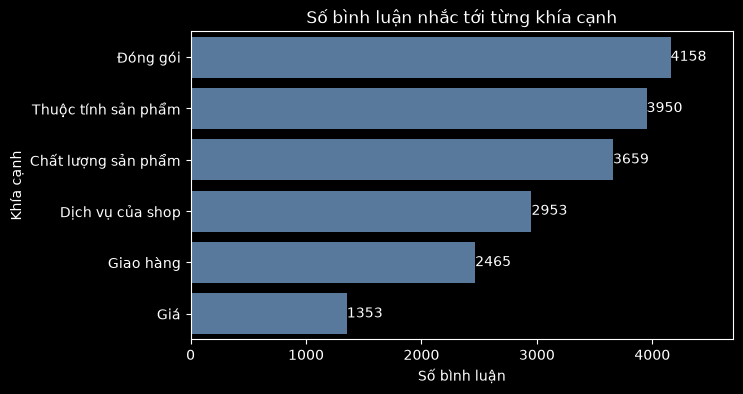

In [378]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=bang_khia_canh_absa.sort_values('so_cau', ascending=False), x='so_cau', y='khia_canh', color=MAU_CHUNG)
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot)
plt.title("Số bình luận nhắc tới từng khía cạnh")
plt.xlabel("Số bình luận")
plt.ylabel("Khía cạnh")
plt.xlim(0, 4700)
plt.show()

In [379]:
df['so_khia_canh_absa'] = df[DS_KHIA_CANH].sum(axis=1)
pd.DataFrame({'5 cột cũ': df['so_khia_canh'].value_counts(),
              '6 khía cạnh mới': df['so_khia_canh_absa'].value_counts()}).fillna(0).astype(int)

,5 cột cũ,6 khía cạnh mới
0,2899,662
1,3009,3143
2,2259,3030
3,1095,1862
4,277,699
5,45,175
6,0,13


In [380]:
print((df['so_khia_canh'] == 0).sum(), (df['so_khia_canh_absa'] == 0).sum())

2899 662


In [381]:
for binh_luan in df.loc[df['so_khia_canh_absa'] == 0, 'review'].sample(8, random_state=RANDOM_STATE):
    print('-', binh_luan[:150])

- Mình có note cho shop là lấy 4cây xanh 1 đỏ nhưng shop giao cho mình 5 cây xanh ,này.là shop kh đọc yêu cầu của khách.
- Shop ơi máy không sấy nóng được. Shop liên lạc lại với em nha
- The worst experience ever. Contacted them the day I recieved my order with the broken bottle. Only once did someone try coming to pick up the bottle w
- Kinh nghiệm sử dụng:xai kich ung da ,rat ngứa
- Nó bị nóng lên xong 1 lúc thì hết với lại bị vón cục là do da mjn k hợp hay sao ta
- Mua cho mẹ uống với cafe, hãng này cũng tốt sẽ quay lại ủng hộ shop
- vãi cả shop đóng góii.  :))
- Đã nhận được hàng rồi. Hinh anh va video chi mang tính chat minh hoa de nhan duoc xu thoi nhe


In [382]:
for binh_luan in df.loc[df['PRICE'] == 1, 'review'].sample(8, random_state=RANDOM_STATE):
    print('-', binh_luan[:150])

- Hương vị:4 vị  Đặt 33 gói mà nhận hàng về đếm thì đc có 31 gói là sao hả shop shop làm ăn gian dối vậy. Mua săn like ở shop hôm 6/6/2025 nói hay lắm c
- Giá cả hợp lý. Đóng gói cẩn thận, ship hàng nhanh chóng. Dầu gội thơm lắm
- Đã dùng nhiều loại thầy loại nào xũng sạch nhưng sẽ khô da đó mọi người lưu ý mùa đông nch ổn với giá
- Chất lượng sản phẩm tốt. Giao hàng nhanh. Đóng gói cẩn thận. Nước giặt thơm giá sale hời
- Ship hàng nhanh. Giá rẻ hơn mua ngoài . Nhà mình xài loại này lâu rồi. Thấy ok. Hình ảnh minh hoạ để nhận xu
- Hàng đúng mô tả. Săn sale được giá rẻ. Lần sau sẽ ủng hộ shop nữa. HA mang tc nhận xu. Dầu không thơm như miêu tả của KOL hơi chán
- Giá rẻ thì ko có hàng bổ đâu nha mn. Lộ rãnh môi nhiều và son màu ko tươi như ảnh.
- Mình mua dịp 12/12 săn sale mua 2 chai lớn 1000ml mà shop k gửi kèm quà tặng. Thất vọng


In [383]:
print(df['kc_gia'].sum(), df['PRICE'].sum())
print(((df['kc_gia'] == 1) & (df['PRICE'] == 0)).sum())

1628 1353
390


In [384]:
## 5. Bước 4: Tạo bộ dữ liệu ABSA - sample, concat, to_csv

In [385]:
df['lan_lon'] = ((df['co_tuong_phan'] == 1) & (df['so_khia_canh_absa'] >= 2)).astype(int)
df['khong_khia_canh'] = (df['so_khia_canh_absa'] == 0).astype(int)
print(df['lan_lon'].sum(), df['khong_khia_canh'].sum())

1246 662


In [386]:
ds_nhom = [('lan_lon', SO_CAU_LAN_LON)]
for ma in DS_KHIA_CANH:
    ds_nhom.append((ma, SO_CAU_MOI_KHIA_CANH))
ds_nhom.append(('khong_khia_canh', SO_CAU_KHONG_KHIA_CANH))
ds_nhom

[('lan_lon', 90),
 ('PRODUCT_QUALITY', 30),
 ('DELIVERY', 30),
 ('PACKAGING', 30),
 ('PRICE', 30),
 ('SELLER_SERVICE', 30),
 ('PRODUCT_FEATURE', 30),
 ('khong_khia_canh', 30)]

In [387]:
df_con_lai = df.copy()
ds_mau = []
for ten_cot, so_cau in ds_nhom:
    df_nhom = df_con_lai[df_con_lai[ten_cot] == 1].sample(so_cau, random_state=RANDOM_STATE)
    ds_mau.append(df_nhom)
    df_con_lai = df_con_lai.drop(df_nhom.index)

In [388]:
df_mau = pd.concat(ds_mau)
df_mau = df_mau.sample(frac=1, random_state=RANDOM_STATE)
print(df_mau.shape[0], df_mau['id'].nunique())

300 300


In [389]:
if os.path.exists('../dataset/nhan_tay_khia_canh.csv'):
    ds_id_da_co = pd.read_csv('../dataset/nhan_tay_khia_canh.csv')['id']
    df_mau = df[df['id'].isin(ds_id_da_co)]
print(df_mau.shape[0], df_mau['id'].nunique())

200 200


In [390]:
df_mau[DS_KHIA_CANH].sum()

PRODUCT_QUALITY    94
DELIVERY           61
PACKAGING          91
PRICE              58
SELLER_SERVICE     76
PRODUCT_FEATURE    98
dtype: int64

In [391]:
print(df_mau['label'].value_counts().to_dict())
print(df_mau['lan_lon'].sum())
print(df_mau['so_tu'].median(), df['so_tu'].median())

{'negative': 130, 'positive': 70}
70
29.5 24.0


In [392]:
bang_gan_tay = df_mau[['id', 'review']].copy()
for ma in DS_KHIA_CANH:
    bang_gan_tay[ma] = ''
bang_gan_tay.head(3)

,id,review,PRODUCT_QUALITY,DELIVERY,PACKAGING,PRICE,SELLER_SERVICE,PRODUCT_FEATURE
24,16499039180,"Kính thì dễ dán, hiệu quả chống xước, trầy tốt, dán kính cường lực sẽ giảm độ nhạy cảm ứng nhma đối với kính của mình nó giảm độ nhạy nhiều khiến mình khá k...",,,,,,
48,37032617550,Mẹo:ok Lợi ích:ok Hương thơm:ok Sản phẩm ok nên mua nha mọi người .tôi luôn chọn unileve mua sn tâm lắm giá ok la,,,,,,
107,49605414116,Hương vị:sản phẩm bị thủng mất chất lượng bên trong kém,,,,,,


In [393]:
if os.path.exists('../dataset/nhan_tay_khia_canh.csv'):
    print("File đã có, không ghi đè")
else:
    bang_gan_tay.to_csv('../dataset/nhan_tay_khia_canh.csv', index=False, encoding='utf-8-sig')
    print("Đã tạo file")

File đã có, không ghi đè


In [394]:
df['de_gan_tay'] = df['id'].isin(df_mau['id']).astype(int)
ds_cot_absa = ['id', 'review', 'rating', 'label', 'tieu_chi', 'noi_dung_absa'] + DS_KHIA_CANH + ['lan_lon', 'de_gan_tay']
df[ds_cot_absa].to_csv('../dataset/du_lieu_absa.csv', index=False)

In [395]:
df_absa = pd.read_csv('../dataset/du_lieu_absa.csv')
print(df_absa.shape)
print(df_absa['de_gan_tay'].value_counts().to_dict())

(9584, 14)
{0: 9384, 1: 200}


In [396]:
df_absa.head(3)

,id,review,rating,label,tieu_chi,noi_dung_absa,PRODUCT_QUALITY,DELIVERY,PACKAGING,PRICE,SELLER_SERVICE,PRODUCT_FEATURE,lan_lon,de_gan_tay
0,74263765409,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy gói,3,negative,Hương vị:thom,thơm chắc do bên giao hàng bị vỡ mấy gói,0,1,1,0,0,1,0,0
1,11104151002,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có Shop đóng gói cẩn thận chu đáo lắm Ship nhanh Shiper thân thiện Sẽ ủng hộ tiếp tục nha Tks,5,positive,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có,nhẹ nhàng phục hồi cấp ẩm không có shop đóng gói cẩn thận chu đáo lắm giao hàng nhanh shiper thân thiện sẽ ủng hộ tiếp tục nha cảm ơn,0,1,1,0,1,1,0,0
2,15888299382,"Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất lượng, dễ dán. Nên mua nha. Mình sẽ quay lại ủng hộ.",5,positive,Chất lượng sản phẩm:ok Đúng với mô tả:đúng,ok đúng lần đầu mua ở shop đóng gói kĩ sản phẩm chất lượng dễ dán nên mua nha mình sẽ quay lại ủng hộ,1,0,1,0,0,0,0,0


In [397]:
## 6. Bước 5: Nhận diện khía cạnh - OneVsRestClassifier

In [398]:
df_absa['van_ban_khia_canh'] = df_absa['review'].apply(lam_sach_absa)
df_absa[['noi_dung_absa', 'van_ban_khia_canh']].iloc[2].to_dict()

{'noi_dung_absa': 'ok đúng lần đầu mua ở shop đóng gói kĩ sản phẩm chất lượng dễ dán nên mua nha mình sẽ quay lại ủng hộ',
 'van_ban_khia_canh': 'chất lượng sản phẩm ok đúng với mô tả đúng lần đầu mua ở shop đóng gói kĩ sản phẩm chất lượng dễ dán nên mua nha mình sẽ quay lại ủng hộ'}

In [399]:
df_huan_luyen = df_absa[df_absa['de_gan_tay'] == 0]
df_huan_luyen.shape

(9384, 15)

In [400]:
x_data = df_huan_luyen['van_ban_khia_canh']
y_data = df_huan_luyen[DS_KHIA_CANH]
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data,
                                                    test_size=TI_LE_TEST,
                                                    random_state=RANDOM_STATE)
print(x_train.shape, x_test.shape)

(6568,) (2816,)


In [401]:
mo_hinh_khia_canh = tao_pipeline_phan_loai(
    OneVsRestClassifier(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced')))
mo_hinh_khia_canh.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('mo_hinh', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[0,1,2,3,4,5]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [402]:
print(DS_KHIA_CANH)
mo_hinh_khia_canh.predict(['giao hàng nhanh nhưng hộp móp'])

['PRODUCT_QUALITY', 'DELIVERY', 'PACKAGING', 'PRICE', 'SELLER_SERVICE', 'PRODUCT_FEATURE']


array([[0, 1, 1, 0, 0, 0]])

In [403]:
mo_hinh_khia_canh.predict_proba(['giao hàng nhanh nhưng hộp móp']).round(2)

array([[0.14, 1.  , 0.98, 0.09, 0.16, 0.08]])

In [404]:
y_du_doan = mo_hinh_khia_canh.predict(x_test)
print(classification_report(y_test, y_du_doan, target_names=DS_KHIA_CANH, digits=3, zero_division=0))

                 precision    recall  f1-score   support

PRODUCT_QUALITY      0.900     0.869     0.884      1042
       DELIVERY      0.954     0.935     0.944       725
      PACKAGING      0.980     0.923     0.951      1227
          PRICE      0.941     0.890     0.915       373
 SELLER_SERVICE      0.934     0.887     0.910       880
PRODUCT_FEATURE      0.931     0.890     0.910      1150

      micro avg      0.940     0.899     0.919      5397
      macro avg      0.940     0.899     0.919      5397
   weighted avg      0.940     0.899     0.919      5397
    samples avg      0.876     0.848     0.849      5397



In [405]:
round(accuracy_score(y_test, y_du_doan), 4)

0.7326

In [406]:
ds_dong = []
for ten_cot in ['noi_dung_absa', 'van_ban_khia_canh']:
    x_train_thu, x_test_thu, y_train_thu, y_test_thu = train_test_split(df_huan_luyen[ten_cot], y_data,
                                                                        test_size=TI_LE_TEST,
                                                                        random_state=RANDOM_STATE)
    mo_hinh_thu = tao_pipeline_phan_loai(
        OneVsRestClassifier(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced')))
    mo_hinh_thu.fit(x_train_thu, y_train_thu)
    y_du_doan_thu = mo_hinh_thu.predict(x_test_thu)
    ds_dong.append({'van_ban': ten_cot,
                    'macro_f1': round(f1_score(y_test_thu, y_du_doan_thu, average='macro'), 4),
                    'dung_ca_6': round(accuracy_score(y_test_thu, y_du_doan_thu), 4)})
pd.DataFrame(ds_dong)

,van_ban,macro_f1,dung_ca_6
0,noi_dung_absa,0.8878,0.6339
1,van_ban_khia_canh,0.9189,0.7326


In [407]:
df_test = df_huan_luyen.loc[x_test.index, ['review']].copy()
df_test['so_khia_canh_quy_tac'] = y_test.sum(axis=1)
df_test['so_khia_canh_mo_hinh'] = y_du_doan.sum(axis=1)
df_test['mo_hinh_doan'] = [[DS_KHIA_CANH[i] for i in range(len(DS_KHIA_CANH)) if dong[i] == 1] for dong in y_du_doan]

In [408]:
df_bo_sot = df_test[df_test['so_khia_canh_quy_tac'] == 0]
print(len(df_bo_sot), (df_bo_sot['so_khia_canh_mo_hinh'] > 0).sum())

192 56


In [409]:
df_mo_hinh_thay = df_bo_sot[df_bo_sot['so_khia_canh_mo_hinh'] > 0]
for i in range(10):
    print(df_mo_hinh_thay['mo_hinh_doan'].iloc[i], '|', df_mo_hinh_thay['review'].iloc[i][:110])

['DELIVERY'] | Đặt shop tphcm mà giao từ Bắc ninh, quá chậm hết giờ
['SELLER_SERVICE'] | Bảo là tăng khăn nhưng ko thấy đâu
['SELLER_SERVICE'] | Mọi lần là cos cả tag ghi rõ seri kèm chung với hóa đơn nhưng lần này không có
['PRODUCT_FEATURE'] | Mẹo:Phu hop moi loai da Kinh nghiệm sử dụng:Da su dung 1 nam  Sạch sâu,lành tính
['PRODUCT_FEATURE'] | Kinh nghiệm sử dụng:xai kich ung da ,rat ngứa
['PRODUCT_FEATURE'] | K hiểu sao dùng toner hay serum của bộ này vài ngày da quen k còn rát. Nhưng riêng với kem chống nắng lần nào 
['PACKAGING'] | phấn bị tràn ra ngoài là sao???
['SELLER_SERVICE'] | ko nhận đc khuyến mại
['PACKAGING'] | Nhận thùng sữa j mà k còn nguyên vẹn. Bịch sữa thì bịch nào cũng bụi, phải lấy khăn lau từng bịch. Sữa sắp vô 
['PRODUCT_FEATURE'] | Dữa tắm ok, nhiêu bọt và quan trong sach không bị trơn nhưnnhuwng loại sữa tăm skhaxs , cả nhà có the dung chu


In [410]:
mo_hinh_khia_canh = tao_pipeline_phan_loai(
    OneVsRestClassifier(LogisticRegression(max_iter=MAX_ITER, class_weight='balanced')))
mo_hinh_khia_canh.fit(x_data, y_data)
joblib.dump(mo_hinh_khia_canh, '../mo_hinh/mo_hinh_khia_canh.joblib')

['../mo_hinh/mo_hinh_khia_canh.joblib']

In [411]:
mo_hinh_khia_canh = joblib.load('../mo_hinh/mo_hinh_khia_canh.joblib')
ds_binh_luan_mau = [
    'Sản phẩm tốt nhưng giao hàng chậm',
    'Bao bì:đẹp  Giao nhanh, giá rẻ',
    'Mùi dễ chịu, cskh nhiệt tình',
    'Ship lẹ, đóng hàng ẩu',
    'Dùng bị châm chích, da nhạy cảm nên cân nhắc',
]

In [412]:
ds_dong = []
for binh_luan in ds_binh_luan_mau:
    ds_dong.append({'binh_luan': binh_luan,
                    'quy_tac': tim_khia_canh(binh_luan),
                    'mo_hinh': du_doan_khia_canh(binh_luan, mo_hinh_khia_canh)})
pd.DataFrame(ds_dong)

,binh_luan,quy_tac,mo_hinh
0,Sản phẩm tốt nhưng giao hàng chậm,"[PRODUCT_QUALITY, DELIVERY]","[PRODUCT_QUALITY, DELIVERY]"
1,"Bao bì:đẹp Giao nhanh, giá rẻ","[DELIVERY, PACKAGING, PRICE]","[DELIVERY, PACKAGING, PRICE, PRODUCT_FEATURE]"
2,"Mùi dễ chịu, cskh nhiệt tình","[SELLER_SERVICE, PRODUCT_FEATURE]","[SELLER_SERVICE, PRODUCT_FEATURE]"
3,"Ship lẹ, đóng hàng ẩu","[DELIVERY, PACKAGING]","[DELIVERY, PACKAGING]"
4,"Dùng bị châm chích, da nhạy cảm nên cân nhắc",[],[]


In [413]:
## 7. Bước 6: Cảm xúc theo từng khía cạnh - cắt vế, predict_proba

In [414]:
x_data = df_huan_luyen['noi_dung_absa']
y_data = df_huan_luyen['label']
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data,
                                                    test_size=TI_LE_TEST,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y_data)

In [415]:
mo_hinh_cam_xuc = tao_pipeline_phan_loai(
    LogisticRegression(C=C_CAM_XUC_ABSA, max_iter=MAX_ITER, class_weight='balanced'))
mo_hinh_cam_xuc.fit(x_train, y_train)
pd.DataFrame([danh_gia_mo_hinh('Cảm xúc ABSA', mo_hinh_cam_xuc, x_train, y_train, x_test, y_test)])

,Mô hình,Accuracy train,Accuracy test,F1 negative,F1 positive,Macro-F1
0,Cảm xúc ABSA,0.9962,0.9506,0.96,0.9356,0.9478


In [416]:
mo_hinh_cam_xuc.fit(x_data, y_data)
joblib.dump(mo_hinh_cam_xuc, '../mo_hinh/mo_hinh_cam_xuc_absa.joblib')

['../mo_hinh/mo_hinh_cam_xuc_absa.joblib']

In [417]:
cat_ve_cau('Hàng đẹp, giao nhanh nhưng hộp móp.')

['hàng đẹp', 'giao nhanh', 'hộp móp']

In [418]:
cat_ve_cau('Tuy đóng gói sơ sài nhưng sản phẩm tốt')

['đóng gói sơ sài', 'sản phẩm tốt']

In [419]:
pd.DataFrame(tach_ve_binh_luan('Bao bì:đẹp  Giao nhanh nhưng giá cao, sẽ ủng hộ tiếp'))

,ve,ds_khia_canh
0,đẹp,[PACKAGING]
1,giao nhanh,[DELIVERY]
2,giá cao,[PRICE]


In [420]:
binh_luan = 'Túi đẹp, đóng gói kĩ nhưng túi bị lỗi đường chỉ có nt qua cskh nhưng shop hỗ trợ k linh hoạt.'
bang_ve = pd.DataFrame(tach_ve_binh_luan(binh_luan))
bang_ve['xac_suat_tich_cuc'] = tinh_xac_suat_tich_cuc(mo_hinh_cam_xuc, bang_ve['ve']).round(3)
bang_ve

,ve,ds_khia_canh,xac_suat_tich_cuc
0,đóng gói kĩ,[PACKAGING],0.849
1,túi bị lỗi đường chỉ có nhắn tin qua cskh,"[PRODUCT_QUALITY, SELLER_SERVICE]",0.016
2,shop hỗ trợ không linh hoạt,[SELLER_SERVICE],0.167


In [421]:
cham_cam_xuc_khia_canh(binh_luan, mo_hinh_cam_xuc)

{'PRODUCT_QUALITY': 0.0164, 'PACKAGING': 0.8491, 'SELLER_SERVICE': 0.0915}

In [422]:
tinh_xac_suat_tich_cuc(mo_hinh_cam_xuc, [lam_sach_binh_luan_absa(binh_luan)]).round(3)

array([0.018])

In [423]:
ds_binh_luan_mau = [
    'Sản phẩm tốt nhưng giao hàng chậm',
    'Tuy đóng gói sơ sài nhưng sản phẩm tốt',
    'Bao bì:đẹp Mùi hương:hắc  Giao nhanh, giá rẻ',
    'Son lên màu đẹp, mỗi tội hơi khô môi',
    'Đóng gói, giao hàng đều tốt',
]
for binh_luan in ds_binh_luan_mau:
    print(binh_luan)
    print('  ', cham_cam_xuc_khia_canh(binh_luan, mo_hinh_cam_xuc))

Sản phẩm tốt nhưng giao hàng chậm
   {'PRODUCT_QUALITY': 0.93, 'DELIVERY': 0.0585}
Tuy đóng gói sơ sài nhưng sản phẩm tốt
   {'PRODUCT_QUALITY': 0.93, 'PACKAGING': 0.0016}
Bao bì:đẹp Mùi hương:hắc  Giao nhanh, giá rẻ
   {'DELIVERY': 0.996, 'PACKAGING': 0.9991, 'PRICE': 0.9912, 'PRODUCT_FEATURE': 0.027}
Son lên màu đẹp, mỗi tội hơi khô môi
   {'PRODUCT_FEATURE': 0.6076}
Đóng gói, giao hàng đều tốt
   {'DELIVERY': 0.7521, 'PACKAGING': 0.112}


In [424]:
df_absa['cam_xuc_khia_canh'] = df_absa['review'].apply(cham_cam_xuc_khia_canh, mo_hinh_cam_xuc=mo_hinh_cam_xuc)
df_absa[['review', 'cam_xuc_khia_canh']].head(4)

,review,cam_xuc_khia_canh
0,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy gói,"{'DELIVERY': 0.0155, 'PACKAGING': 0.0155, 'PRODUCT_FEATURE': 0.9994}"
1,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có Shop đóng gói cẩn thận chu đáo lắm Ship nhanh Shiper thân thiện Sẽ ủng hộ tiếp tục nha Tks,"{'DELIVERY': 0.9997, 'PACKAGING': 0.9997, 'SELLER_SERVICE': 0.9997, 'PRODUCT_FEATURE': 0.7616}"
2,"Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất lượng, dễ dán. Nên mua nha. Mình sẽ quay lại ủng hộ.","{'PRODUCT_QUALITY': 0.9622, 'PACKAGING': 0.8491}"
3,Độ tuổi sử dụng:em bes Chất lượng sản phẩm:tot Sản phẩm đúng mô tả sẽ mua lại hình ảnh mang tc nhận xu,{'PRODUCT_QUALITY': 0.9817}


In [425]:
(df_absa['cam_xuc_khia_canh'].apply(len) > 0).sum()

np.int64(8914)

In [426]:
ds_dong = []
for ma in DS_KHIA_CANH:
    df_khia_canh = df_absa[df_absa['cam_xuc_khia_canh'].apply(lambda ket_qua: ma in ket_qua)]
    che_theo_ve = df_khia_canh['cam_xuc_khia_canh'].apply(lambda ket_qua: ket_qua[ma] < NGUONG_KHEN_CHE)
    che_theo_ca_cau = df_khia_canh['label'] == NHAN_TIEU_CUC
    ds_dong.append({'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                    'so_cau': len(df_khia_canh),
                    'che_theo_ve': round(che_theo_ve.mean() * 100, 1),
                    'che_theo_ca_cau': round(che_theo_ca_cau.mean() * 100, 1),
                    'khac_nhan_ca_cau': round((che_theo_ve != che_theo_ca_cau).mean() * 100, 1)})
pd.DataFrame(ds_dong)

,khia_canh,so_cau,che_theo_ve,che_theo_ca_cau,khac_nhan_ca_cau
0,Chất lượng sản phẩm,3653,43.0,49.1,11.9
1,Giao hàng,2463,36.4,43.7,10.4
2,Đóng gói,4153,64.0,66.0,9.7
3,Giá,1352,30.2,37.4,12.1
4,Dịch vụ của shop,2952,85.0,81.4,6.0
5,Thuộc tính sản phẩm,3928,35.7,44.7,19.7


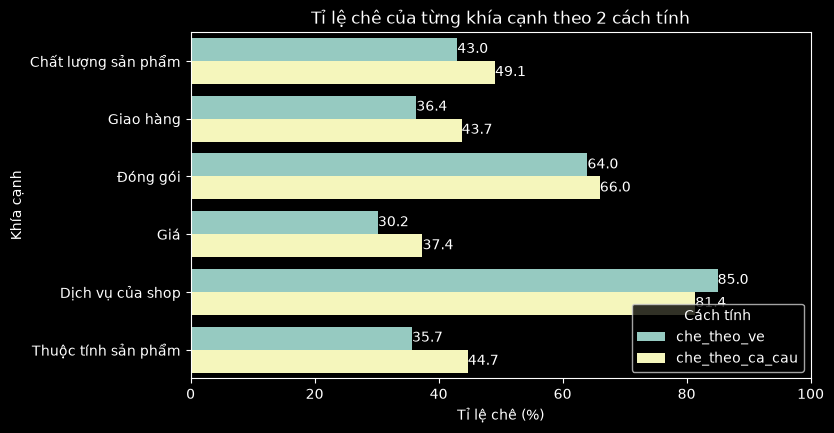

In [427]:
bang_so_che = pd.DataFrame(ds_dong).melt(id_vars='khia_canh', value_vars=['che_theo_ve', 'che_theo_ca_cau'],
                                         var_name='cach_tinh', value_name='ti_le_che')
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=bang_so_che, x='ti_le_che', y='khia_canh', hue='cach_tinh')
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot, fmt='%.1f')
plt.title("Tỉ lệ chê của từng khía cạnh theo 2 cách tính")
plt.xlabel("Tỉ lệ chê (%)")
plt.ylabel("Khía cạnh")
plt.xlim(0, 100)
plt.legend(title="Cách tính", loc='lower right')
plt.show()

In [428]:
df_absa['p_thap_nhat'] = df_absa['cam_xuc_khia_canh'].apply(lambda ket_qua: min(ket_qua.values(), default=1))
df_absa['p_cao_nhat'] = df_absa['cam_xuc_khia_canh'].apply(lambda ket_qua: max(ket_qua.values(), default=0))

In [429]:
df_absa['vua_khen_vua_che'] = ((df_absa['p_thap_nhat'] < NGUONG_KHEN_CHE) & (df_absa['p_cao_nhat'] >= NGUONG_KHEN_CHE)).astype(int)
pd.crosstab(df_absa['vua_khen_vua_che'], df_absa['label'])

label,negative,positive
vua_khen_vua_che,,
0,4995,3098
1,956,535


In [430]:
## 8. Bước 7: Ghép ABSA - phan_tich_absa, json

In [431]:
ket_qua = phan_tich_absa('Sản phẩm tốt nhưng giao hàng chậm', mo_hinh_cam_xuc)
print(json.dumps(ket_qua, ensure_ascii=False, indent=2))

{
  "review": "Sản phẩm tốt nhưng giao hàng chậm",
  "aspects": [
    {
      "aspect": "PRODUCT_QUALITY",
      "sentiment": "positive",
      "xac_suat_tich_cuc": 0.93
    },
    {
      "aspect": "DELIVERY",
      "sentiment": "negative",
      "xac_suat_tich_cuc": 0.0585
    }
  ]
}


In [432]:
ket_qua = phan_tich_absa('Bao bì:đẹp Mùi hương:hắc  Giao nhanh, giá rẻ nhưng shop trả lời chậm', mo_hinh_cam_xuc)
pd.DataFrame(ket_qua['aspects'])

,aspect,sentiment,xac_suat_tich_cuc
0,DELIVERY,positive,0.9960
1,PACKAGING,positive,0.9991
2,PRICE,positive,0.9912
3,SELLER_SERVICE,negative,0.0208
4,PRODUCT_FEATURE,negative,0.0270


In [433]:
df_absa['ket_qua_absa'] = df_absa['review'].apply(phan_tich_absa, mo_hinh_cam_xuc=mo_hinh_cam_xuc)
df_absa['so_khia_canh_ket_qua'] = df_absa['ket_qua_absa'].apply(lambda ket_qua: len(ket_qua['aspects']))
print((df_absa['so_khia_canh_ket_qua'] > 0).sum(), df_absa['so_khia_canh_ket_qua'].sum())

8922 18538


In [434]:
for ma in DS_KHIA_CANH:
    df_absa['cx_' + ma] = ''
for i in range(len(df_absa)):
    for khia_canh in df_absa['ket_qua_absa'].iloc[i]['aspects']:
        df_absa.loc[df_absa.index[i], 'cx_' + khia_canh['aspect']] = khia_canh['sentiment']

In [435]:
ds_dong = []
for ma in DS_KHIA_CANH:
    so_khen = (df_absa['cx_' + ma] == NHAN_TICH_CUC).sum()
    so_che = (df_absa['cx_' + ma] == NHAN_TIEU_CUC).sum()
    ds_dong.append({'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                    'khen': so_khen,
                    'che': so_che,
                    'ti_le_che': round(so_che / (so_khen + so_che) * 100, 1)})
pd.DataFrame(ds_dong).sort_values('ti_le_che', ascending=False)

,khia_canh,khen,che,ti_le_che
4,Dịch vụ của shop,443,2510,85.0
2,Đóng gói,1499,2659,63.9
0,Chất lượng sản phẩm,2084,1575,43.0
1,Giao hàng,1566,899,36.5
5,Thuộc tính sản phẩm,2536,1414,35.8
3,Giá,944,409,30.2


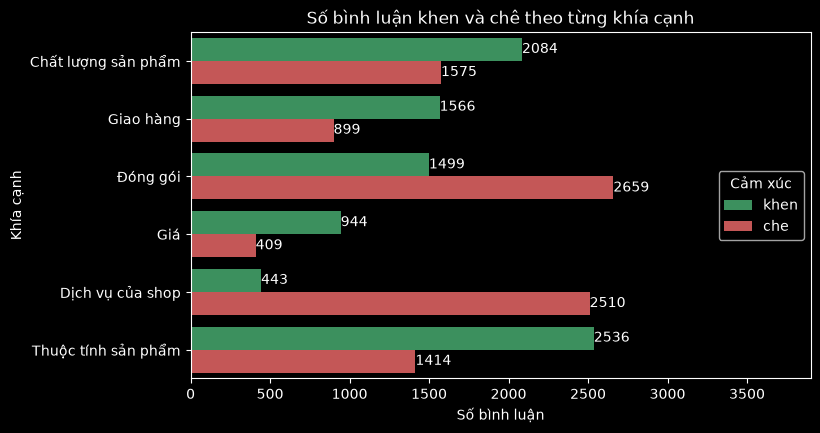

In [436]:
bang_khen_che = pd.DataFrame(ds_dong).melt(id_vars='khia_canh', value_vars=['khen', 'che'],
                                           var_name='cam_xuc', value_name='so_cau')
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=bang_khen_che, x='so_cau', y='khia_canh', hue='cam_xuc',
                 palette={'khen': MAU_TICH_CUC, 'che': MAU_TIEU_CUC})
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot)
plt.title("Số bình luận khen và chê theo từng khía cạnh")
plt.xlabel("Số bình luận")
plt.ylabel("Khía cạnh")
plt.xlim(0, 3900)
plt.legend(title="Cảm xúc", loc='center right')
plt.show()

In [437]:
df_absa['nganh_hang'] = df['nganh_hang'].values
ds_cot_ket_qua = ['id', 'rating', 'label', 'nganh_hang'] + ['cx_' + ma for ma in DS_KHIA_CANH]
df_absa[ds_cot_ket_qua].to_csv('../dataset/ket_qua_absa.csv', index=False)
df_absa[ds_cot_ket_qua].shape

(9584, 10)

In [438]:
df_ro_nganh = df_absa[df_absa['nganh_hang'] != NGANH_KHONG_RO]
bang_nganh_khia_canh = pd.DataFrame()
for ma in DS_KHIA_CANH:
    df_co_nhac = df_ro_nganh[df_ro_nganh['cx_' + ma] != ''].copy()
    df_co_nhac['la_che'] = (df_co_nhac['cx_' + ma] == NHAN_TIEU_CUC) * 100
    bang_nganh_khia_canh[TEN_KHIA_CANH_ABSA[ma]] = df_co_nhac.groupby('nganh_hang')['la_che'].mean()

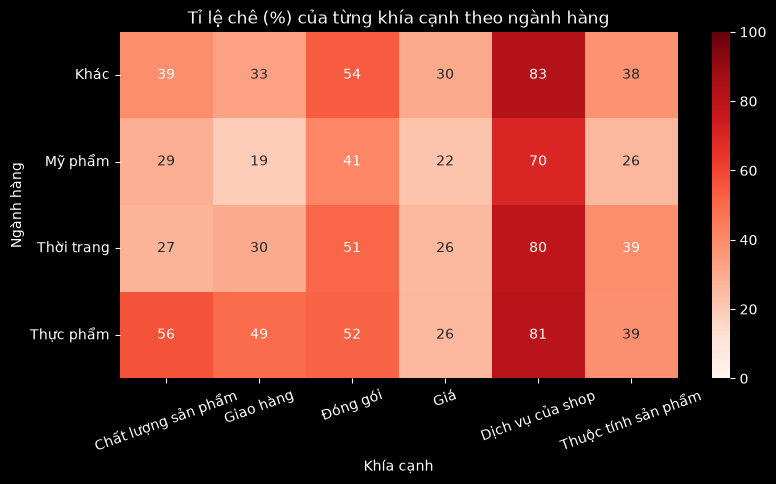

In [439]:
plt.figure(figsize=(9, 4.5))
sns.heatmap(bang_nganh_khia_canh, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100)
plt.title("Tỉ lệ chê (%) của từng khía cạnh theo ngành hàng")
plt.xlabel("Khía cạnh")
plt.ylabel("Ngành hàng")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.show()

In [440]:
## 9. Bước 8: Đánh giá trên 200 câu gán tay - precision, recall, F1

In [441]:
df_tay = pd.read_csv('../dataset/nhan_tay_khia_canh.csv')
for ma in DS_KHIA_CANH:
    df_tay[ma] = df_tay[ma].fillna('').astype(str).str.strip().str.lower()
df_tay.shape

(200, 8)

In [442]:
df_tay['co_nhan'] = (df_tay[DS_KHIA_CANH] != '').sum(axis=1) > 0
so_cau_da_gan = 0
for i in range(len(df_tay)):
    if df_tay['co_nhan'].iloc[i]:
        so_cau_da_gan = i + 1
print("Số câu đã gán tay:", so_cau_da_gan, "/", len(df_tay))

Số câu đã gán tay: 200 / 200


In [443]:
ds_nhan_la = []
for ma in DS_KHIA_CANH:
    for nhan in df_tay[ma].unique():
        if nhan != '' and nhan not in NHAN_GAN_TAY and nhan not in ds_nhan_la:
            ds_nhan_la.append(nhan)
print("Nhãn lạ:", ds_nhan_la)

Nhãn lạ: []


In [444]:
df_da_gan = df_tay.head(so_cau_da_gan).merge(df_absa[['id', 'label']], on='id')
df_da_gan['quy_tac'] = df_da_gan['review'].apply(tim_khia_canh)
df_da_gan['mo_hinh'] = df_da_gan['review'].apply(du_doan_khia_canh, mo_hinh_khia_canh=mo_hinh_khia_canh)
df_da_gan['absa'] = df_da_gan['review'].apply(phan_tich_absa, mo_hinh_cam_xuc=mo_hinh_cam_xuc)
df_tap_1 = df_da_gan.head(SO_CAU_TIM_LOI)
df_tap_2 = df_da_gan.iloc[SO_CAU_TIM_LOI:]
print(df_tap_1.shape[0], df_tap_2.shape[0])

100 100


In [445]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay. Điền file dataset/nhan_tay_khia_canh.csv rồi chạy lại từ mục 9.1.")
else:
    bang_quy_tac = cham_nhan_dien_khia_canh(df_tap_2, 'quy_tac')
    print(bang_quy_tac)
    print("Macro-F1:", round(bang_quy_tac['f1'].mean(), 3))

             khia_canh  so_cau  precision  recall     f1
0  Chất lượng sản phẩm      54      0.755   0.741  0.748
1            Giao hàng      24      0.719   0.958  0.821
2             Đóng gói      43      0.911   0.953  0.932
3                  Giá      27      0.929   0.963  0.945
4     Dịch vụ của shop      34      0.846   0.971  0.904
5  Thuộc tính sản phẩm      47      0.712   0.787  0.747
Macro-F1: 0.849


In [446]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    bang_mo_hinh = cham_nhan_dien_khia_canh(df_tap_2, 'mo_hinh')
    print(bang_mo_hinh)
    print("Macro-F1:", round(bang_mo_hinh['f1'].mean(), 3))

             khia_canh  so_cau  precision  recall     f1
0  Chất lượng sản phẩm      54      0.800   0.667  0.727
1            Giao hàng      24      0.733   0.917  0.815
2             Đóng gói      43      0.952   0.930  0.941
3                  Giá      27      0.962   0.926  0.943
4     Dịch vụ của shop      34      0.861   0.912  0.886
5  Thuộc tính sản phẩm      47      0.760   0.809  0.784
Macro-F1: 0.849


In [447]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    bang_cam_xuc = cham_cam_xuc_theo_khia_canh(df_tap_2, 'absa')
    print(bang_cam_xuc)
    so_cap = bang_cam_xuc['may_nhan_ra'].sum()
    print("Số cặp máy nhận ra:", so_cap)
    print("Đúng theo vế:", round((bang_cam_xuc['dung_absa'] * bang_cam_xuc['may_nhan_ra']).sum() / so_cap, 3))
    print("Đúng theo nhãn cả câu:", round((bang_cam_xuc['dung_nhan_ca_cau'] * bang_cam_xuc['may_nhan_ra']).sum() / so_cap, 3))

             khia_canh  so_cau  may_nhan_ra  dung_absa  dung_nhan_ca_cau
0  Chất lượng sản phẩm      54           40      0.925             0.925
1            Giao hàng      24           23      0.957             0.957
2             Đóng gói      43           41      1.000             0.927
3                  Giá      27           26      0.885             0.923
4     Dịch vụ của shop      34           33      0.970             0.970
5  Thuộc tính sản phẩm      47           37      0.838             0.838
Số cặp máy nhận ra: 200
Đúng theo vế: 0.93
Đúng theo nhãn cả câu: 0.92


In [448]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    bang_cam_xuc_ca_2 = cham_cam_xuc_theo_khia_canh(df_da_gan, 'absa')
    print(bang_cam_xuc_ca_2)
    so_cap = bang_cam_xuc_ca_2['may_nhan_ra'].sum()
    print("Số cặp máy nhận ra:", so_cap)
    print("Đúng theo vế:", round((bang_cam_xuc_ca_2['dung_absa'] * bang_cam_xuc_ca_2['may_nhan_ra']).sum() / so_cap, 3))
    print("Đúng theo nhãn cả câu:", round((bang_cam_xuc_ca_2['dung_nhan_ca_cau'] * bang_cam_xuc_ca_2['may_nhan_ra']).sum() / so_cap, 3))

             khia_canh  so_cau  may_nhan_ra  dung_absa  dung_nhan_ca_cau
0  Chất lượng sản phẩm      97           70      0.929             0.914
1            Giao hàng      49           48      0.917             0.896
2             Đóng gói      84           81      0.988             0.901
3                  Giá      54           53      0.887             0.887
4     Dịch vụ của shop      76           66      0.970             0.955
5  Thuộc tính sản phẩm      83           70      0.800             0.786
Số cặp máy nhận ra: 388
Đúng theo vế: 0.918
Đúng theo nhãn cả câu: 0.889


In [449]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    ds_dong = []
    for i in range(len(df_tap_2)):
        cam_xuc_may = {}
        for khia_canh in df_tap_2['absa'].iloc[i]['aspects']:
            cam_xuc_may[khia_canh['aspect']] = khia_canh['sentiment']
        for ma in DS_KHIA_CANH:
            nhan_tay = NHAN_GAN_TAY.get(df_tap_2[ma].iloc[i], '')
            nhan_may = cam_xuc_may.get(ma, '')
            if nhan_tay == nhan_may:
                continue
            if nhan_may == '':
                kieu_loi = 'Máy bỏ sót khía cạnh'
            elif nhan_tay == '':
                kieu_loi = 'Máy nhận thừa khía cạnh'
            else:
                kieu_loi = 'Đúng khía cạnh, sai khen chê'
            ds_dong.append({'id': df_tap_2['id'].iloc[i], 'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                            'nguoi_gan': nhan_tay, 'may': nhan_may, 'kieu_loi': kieu_loi,
                            'review': df_tap_2['review'].iloc[i]})
    bang_loi = pd.DataFrame(ds_dong)
    print(bang_loi['kieu_loi'].value_counts())
    print(pd.crosstab(bang_loi['khia_canh'], bang_loi['kieu_loi']))

kieu_loi
Máy nhận thừa khía cạnh         49
Máy bỏ sót khía cạnh            29
Đúng khía cạnh, sai khen chê    14
Name: count, dtype: int64
kieu_loi             Máy bỏ sót khía cạnh  Máy nhận thừa khía cạnh  \
khia_canh                                                            
Chất lượng sản phẩm                    14                       13   
Dịch vụ của shop                        1                        6   
Giao hàng                               1                        9   
Giá                                     1                        2   
Thuộc tính sản phẩm                    10                       15   
Đóng gói                                2                        4   

kieu_loi             Đúng khía cạnh, sai khen chê  
khia_canh                                          
Chất lượng sản phẩm                             3  
Dịch vụ của shop                                1  
Giao hàng                                       1  
Giá                                    

In [450]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    bang_quy_tac['cach'] = 'Quy tắc từ khóa'
    bang_mo_hinh['cach'] = 'Mô hình đa nhãn'
    bang_f1 = pd.concat([bang_quy_tac, bang_mo_hinh])
    bang_f1.to_csv('../dataset/ket_qua_f1_khia_canh.csv', index=False)
    print(bang_f1[['khia_canh', 'cach', 'so_cau', 'f1']])

             khia_canh             cach  so_cau     f1
0  Chất lượng sản phẩm  Quy tắc từ khóa      54  0.748
1            Giao hàng  Quy tắc từ khóa      24  0.821
2             Đóng gói  Quy tắc từ khóa      43  0.932
3                  Giá  Quy tắc từ khóa      27  0.945
4     Dịch vụ của shop  Quy tắc từ khóa      34  0.904
5  Thuộc tính sản phẩm  Quy tắc từ khóa      47  0.747
0  Chất lượng sản phẩm  Mô hình đa nhãn      54  0.727
1            Giao hàng  Mô hình đa nhãn      24  0.815
2             Đóng gói  Mô hình đa nhãn      43  0.941
3                  Giá  Mô hình đa nhãn      27  0.943
4     Dịch vụ của shop  Mô hình đa nhãn      34  0.886
5  Thuộc tính sản phẩm  Mô hình đa nhãn      47  0.784


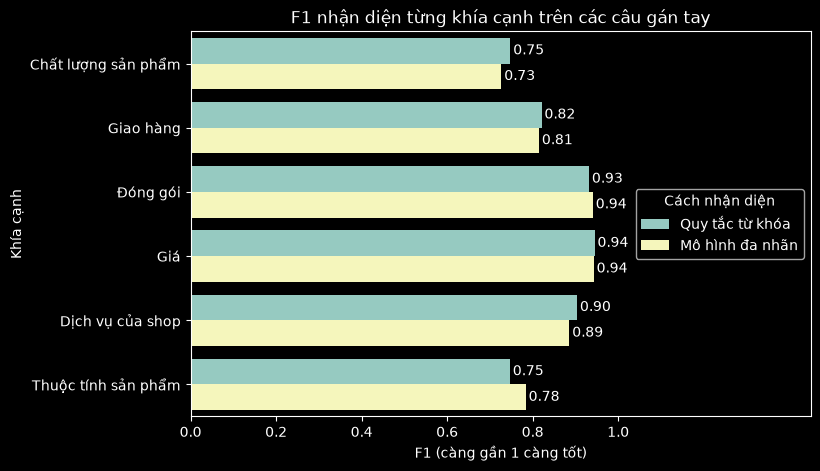

In [451]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=bang_f1, x='f1', y='khia_canh', hue='cach')
    for nhom_cot in ax.containers:
        ax.bar_label(nhom_cot, fmt='%.2f', padding=2)
    plt.title("F1 nhận diện từng khía cạnh trên các câu gán tay")
    plt.xlabel("F1 (càng gần 1 càng tốt)")
    plt.ylabel("Khía cạnh")
    plt.xlim(0, 1.45)
    plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    plt.legend(title="Cách nhận diện", loc='center right')
    plt.show()

In [452]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    tu_khoa_moi = {}
    for ma in TU_KHOA_ABSA_CU:
        tu_khoa_moi[ma] = TU_KHOA_ABSA[ma]
        TU_KHOA_ABSA[ma] = TU_KHOA_ABSA_CU[ma]
    df_da_gan['quy_tac_cu'] = df_da_gan['review'].apply(tim_khia_canh)
    for ma in tu_khoa_moi:
        TU_KHOA_ABSA[ma] = tu_khoa_moi[ma]
    print(len(TU_KHOA_ABSA['DELIVERY']), 'giao' in TU_KHOA_ABSA['DELIVERY'])

21 False


In [453]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    ds_tap = [('Tập 1', df_da_gan.head(SO_CAU_TIM_LOI)), ('Tập 2', df_da_gan.iloc[SO_CAU_TIM_LOI:])]
    ds_cach = [('Từ khóa cũ', 'quy_tac_cu'), ('Từ khóa mới', 'quy_tac')]
    ds_dong = []
    for ten_tap, df_tap in ds_tap:
        for ten_cach, ten_cot in ds_cach:
            bang = cham_nhan_dien_khia_canh(df_tap, ten_cot)
            dong = {'tap': ten_tap, 'tu_khoa': ten_cach, 'macro_f1': round(bang['f1'].mean(), 3)}
            for i in range(len(bang)):
                dong[bang['khia_canh'].iloc[i]] = bang['f1'].iloc[i]
            ds_dong.append(dong)
    bang_truoc_sau = pd.DataFrame(ds_dong)
    print(bang_truoc_sau.T)

                              0            1           2            3
tap                       Tập 1        Tập 1       Tập 2        Tập 2
tu_khoa              Từ khóa cũ  Từ khóa mới  Từ khóa cũ  Từ khóa mới
macro_f1                  0.792        0.858       0.812        0.849
Chất lượng sản phẩm       0.641        0.714       0.713        0.748
Giao hàng                 0.708        0.926        0.75        0.821
Đóng gói                   0.92         0.92       0.932        0.932
Giá                       0.947        0.947       0.945        0.945
Dịch vụ của shop          0.729        0.835       0.786        0.904
Thuộc tính sản phẩm       0.805        0.805       0.747        0.747


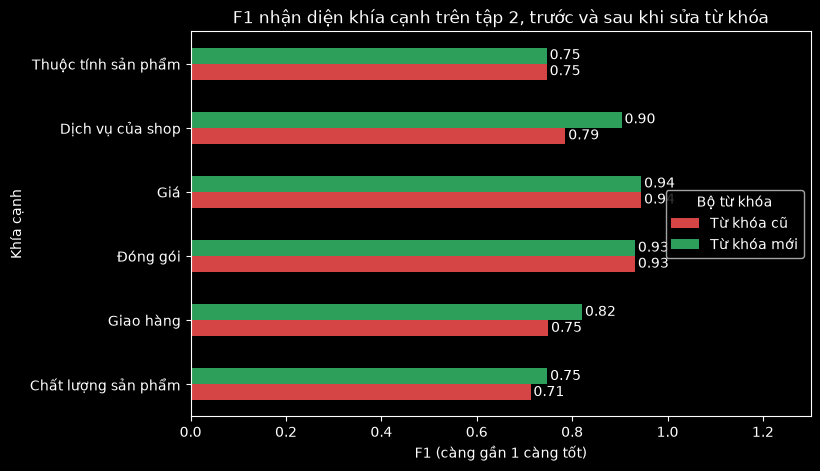

In [454]:
if so_cau_da_gan == 0:
    print("Chưa có nhãn gán tay.")
else:
    bang_ve = bang_truoc_sau[bang_truoc_sau['tap'] == 'Tập 2'].set_index('tu_khoa')
    bang_ve = bang_ve.drop(columns=['tap', 'macro_f1']).T
    ax = bang_ve.plot(kind='barh', figsize=(8, 5), color=[MAU_TIEU_CUC, MAU_TICH_CUC])
    for nhom_cot in ax.containers:
        ax.bar_label(nhom_cot, fmt='%.2f', padding=2)
    plt.title("F1 nhận diện khía cạnh trên tập 2, trước và sau khi sửa từ khóa")
    plt.xlabel("F1 (càng gần 1 càng tốt)")
    plt.ylabel("Khía cạnh")
    plt.xlim(0, 1.3)
    plt.legend(title="Bộ từ khóa", loc='center right')
    plt.show()

In [455]:
## 10. Trực quan hóa đa khía cạnh - waffle, scatter, line, area, hồi quy

In [456]:
bang_cx = df_absa[['cx_' + ma for ma in DS_KHIA_CANH]]
df_absa['so_kc_khen'] = (bang_cx == NHAN_TICH_CUC).sum(axis=1)
df_absa['so_kc_che'] = (bang_cx == NHAN_TIEU_CUC).sum(axis=1)

df_absa['kieu_binh_luan'] = 'Không nhắc khía cạnh nào'
df_absa.loc[(df_absa['so_kc_khen'] > 0) & (df_absa['so_kc_che'] == 0), 'kieu_binh_luan'] = 'Chỉ khen'
df_absa.loc[(df_absa['so_kc_khen'] == 0) & (df_absa['so_kc_che'] > 0), 'kieu_binh_luan'] = 'Chỉ chê'
df_absa.loc[(df_absa['so_kc_khen'] > 0) & (df_absa['so_kc_che'] > 0), 'kieu_binh_luan'] = 'Vừa khen vừa chê'

ds_kieu = ['Chỉ khen', 'Chỉ chê', 'Vừa khen vừa chê', 'Không nhắc khía cạnh nào']
bang_kieu = pd.DataFrame({'so_cau': df_absa['kieu_binh_luan'].value_counts()[ds_kieu]})
bang_kieu['ti_le'] = (bang_kieu['so_cau'] / len(df_absa) * 100).round(1)
bang_kieu

,so_cau,ti_le
kieu_binh_luan,,
Chỉ khen,3078,32.1
Chỉ chê,4353,45.4
Vừa khen vừa chê,1491,15.6
Không nhắc khía cạnh nào,662,6.9


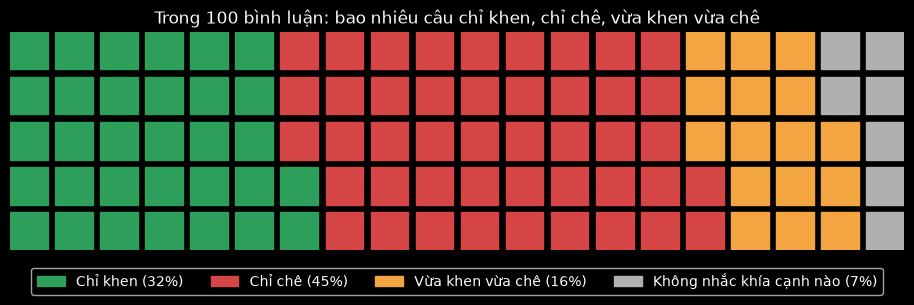

In [457]:
so_o = bang_kieu['ti_le'].round().astype(int)
plt.figure(FigureClass=Waffle, rows=5, columns=20, values=list(so_o), figsize=(10, 3.5),
           colors=[MAU_TICH_CUC, MAU_TIEU_CUC, '#f2a541', '#b0b0b0'],
           labels=[ds_kieu[i] + " (" + str(so_o.iloc[i]) + "%)" for i in range(len(ds_kieu))],
           legend={'loc': 'upper center', 'bbox_to_anchor': (0.5, -0.05), 'ncol': 4})
plt.title("Trong 100 bình luận: bao nhiêu câu chỉ khen, chỉ chê, vừa khen vừa chê")
plt.show()

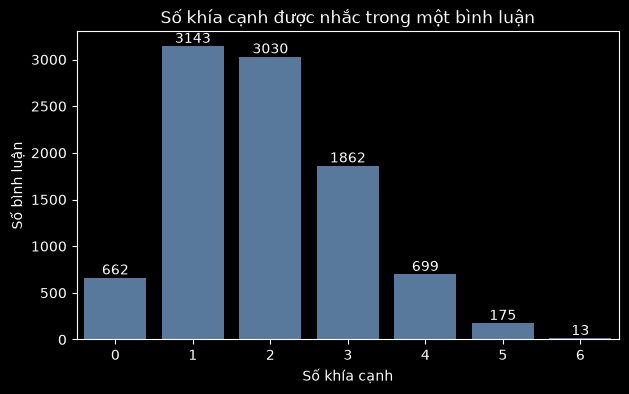

Số khía cạnh trung bình: 1.93
Tỉ lệ bình luận nhắc từ 2 khía cạnh trở lên: 60.3 %


In [458]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df_absa, x='so_khia_canh_ket_qua', color=MAU_CHUNG)
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot)
plt.title("Số khía cạnh được nhắc trong một bình luận")
plt.xlabel("Số khía cạnh")
plt.ylabel("Số bình luận")
plt.show()
print("Số khía cạnh trung bình:", round(df_absa['so_khia_canh_ket_qua'].mean(), 2))
print("Tỉ lệ bình luận nhắc từ 2 khía cạnh trở lên:", round((df_absa['so_khia_canh_ket_qua'] >= 2).mean() * 100, 1), "%")

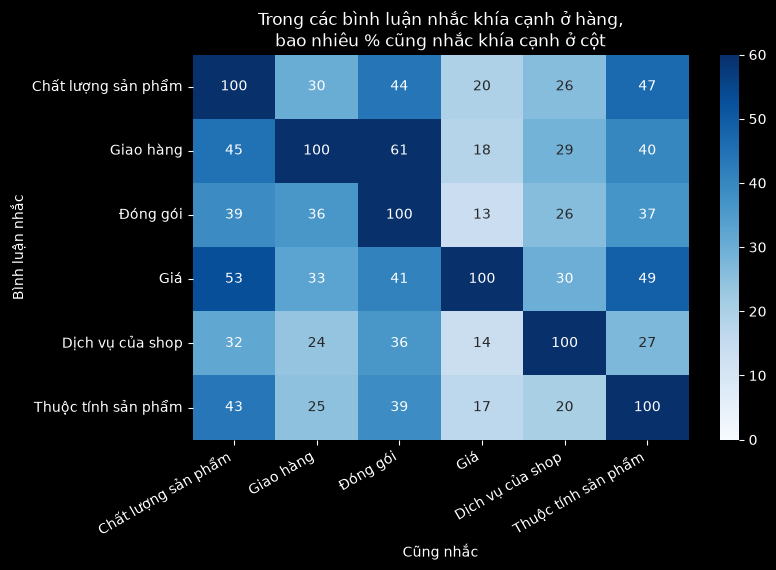

In [459]:
bang_co_nhac = (bang_cx != '').astype(int)
bang_co_nhac.columns = [TEN_KHIA_CANH_ABSA[ma] for ma in DS_KHIA_CANH]
bang_cung_nhac = bang_co_nhac.T.dot(bang_co_nhac)
bang_ti_le_cung_nhac = bang_cung_nhac.div(bang_co_nhac.sum(), axis=0) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(bang_ti_le_cung_nhac, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=60)
plt.title("Trong các bình luận nhắc khía cạnh ở hàng,\nbao nhiêu % cũng nhắc khía cạnh ở cột")
plt.xlabel("Cũng nhắc")
plt.ylabel("Bình luận nhắc")
plt.xticks(rotation=30, ha='right')
plt.show()

In [460]:
ds_dong = []
for nganh in df_ro_nganh['nganh_hang'].unique():
    df_nganh = df_ro_nganh[df_ro_nganh['nganh_hang'] == nganh]
    for ma in DS_KHIA_CANH:
        if ma == KHIA_CANH_TIEU_CHI_CON_LAI:
            continue
        df_co_nhac = df_nganh[df_nganh['cx_' + ma] != '']
        ds_dong.append({'nganh_hang': nganh,
                        'khia_canh': TEN_KHIA_CANH_ABSA[ma],
                        'so_cau_nhac': len(df_co_nhac),
                        'ti_le_nhac': round(len(df_co_nhac) / len(df_nganh) * 100, 1),
                        'ti_le_che': round((df_co_nhac['cx_' + ma] == NHAN_TIEU_CUC).mean() * 100, 1)})
bang_uu_tien = pd.DataFrame(ds_dong)
print("Trung bình tỉ lệ nhắc:", round(bang_uu_tien['ti_le_nhac'].mean(), 1),
      "| Trung bình tỉ lệ chê:", round(bang_uu_tien['ti_le_che'].mean(), 1))
bang_uu_tien[(bang_uu_tien['ti_le_nhac'] > bang_uu_tien['ti_le_nhac'].mean())
             & (bang_uu_tien['ti_le_che'] > bang_uu_tien['ti_le_che'].mean())]

Trung bình tỉ lệ nhắc: 34.6 | Trung bình tỉ lệ chê: 44.9


,nganh_hang,khia_canh,so_cau_nhac,ti_le_nhac,ti_le_che
0,Thực phẩm,Chất lượng sản phẩm,149,42.3,56.4
1,Thực phẩm,Giao hàng,140,39.8,49.3
2,Thực phẩm,Đóng gói,316,89.8,51.6
12,Khác,Đóng gói,756,57.4,53.6


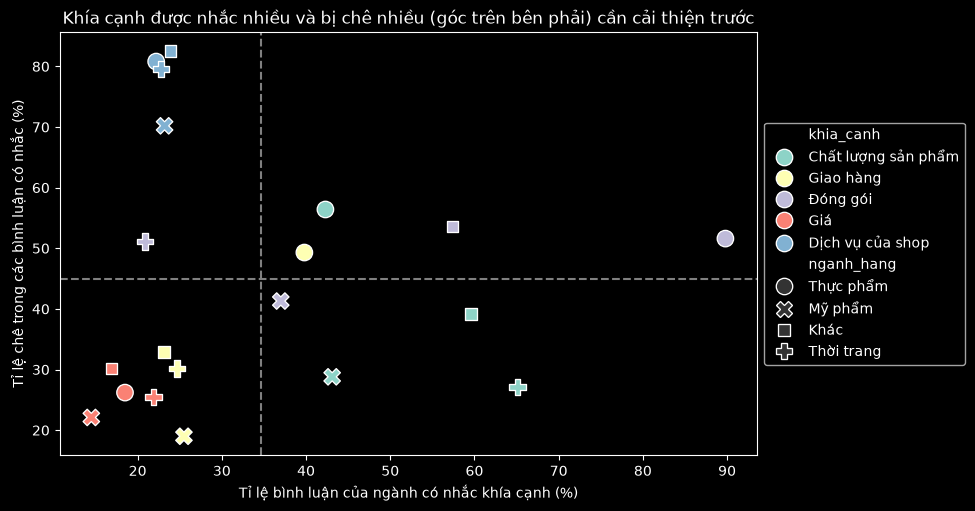

In [461]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=bang_uu_tien, x='ti_le_nhac', y='ti_le_che', hue='khia_canh', style='nganh_hang', s=140)
plt.axvline(bang_uu_tien['ti_le_nhac'].mean(), color='gray', linestyle='--')
plt.axhline(bang_uu_tien['ti_le_che'].mean(), color='gray', linestyle='--')
plt.title("Khía cạnh được nhắc nhiều và bị chê nhiều (góc trên bên phải) cần cải thiện trước")
plt.xlabel("Tỉ lệ bình luận của ngành có nhắc khía cạnh (%)")
plt.ylabel("Tỉ lệ chê trong các bình luận có nhắc (%)")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [462]:
ds_dong = []
for ma in DS_KHIA_CANH:
    df_co_nhac = df_absa[df_absa['cx_' + ma] != ''].copy()
    df_co_nhac['la_che'] = (df_co_nhac['cx_' + ma] == NHAN_TIEU_CUC) * 100
    ti_le_theo_sao = df_co_nhac.groupby('rating')['la_che'].mean()
    so_che_theo_sao = df_co_nhac.groupby('rating')['la_che'].sum() / 100
    for so_sao in ti_le_theo_sao.index:
        ds_dong.append({'khia_canh': TEN_KHIA_CANH_ABSA[ma], 'rating': so_sao,
                        'ti_le_che': round(ti_le_theo_sao[so_sao], 1),
                        'so_luot_che': int(so_che_theo_sao[so_sao])})
bang_che_theo_sao = pd.DataFrame(ds_dong)
bang_che_theo_sao.pivot(index='khia_canh', columns='rating', values='ti_le_che')

rating,1,2,3,4,5
khia_canh,,,,,
Chất lượng sản phẩm,88.2,79.4,66.3,31.2,5.7
Dịch vụ của shop,99.1,97.6,94.3,68.0,26.6
Giao hàng,91.0,77.5,60.1,23.1,2.9
Giá,82.1,67.4,55.6,25.0,4.2
Thuộc tính sản phẩm,74.6,66.9,55.7,29.5,10.4
Đóng gói,94.5,88.5,83.5,53.5,11.8


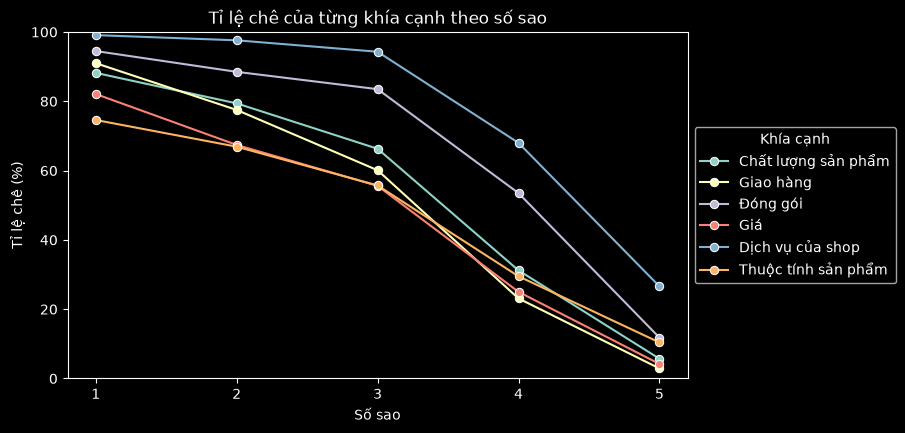

In [463]:
plt.figure(figsize=(8, 4.5))
sns.lineplot(data=bang_che_theo_sao, x='rating', y='ti_le_che', hue='khia_canh', marker='o')
plt.title("Tỉ lệ chê của từng khía cạnh theo số sao")
plt.xlabel("Số sao")
plt.ylabel("Tỉ lệ chê (%)")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 100)
plt.legend(title="Khía cạnh", loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [464]:
bang_luot_che = bang_che_theo_sao.pivot(index='rating', columns='khia_canh', values='so_luot_che')
bang_luot_che['Tổng'] = bang_luot_che.sum(axis=1)
bang_luot_che

khia_canh,Chất lượng sản phẩm,Dịch vụ của shop,Giao hàng,Giá,Thuộc tính sản phẩm,Đóng gói,Tổng
rating,,,,,,,
1,809,1467,456,215,539,1178,4664
2,304,410,169,60,277,549,1769
3,344,477,229,95,361,749,2255
4,15,17,6,5,18,23,84
5,103,139,39,34,219,160,694


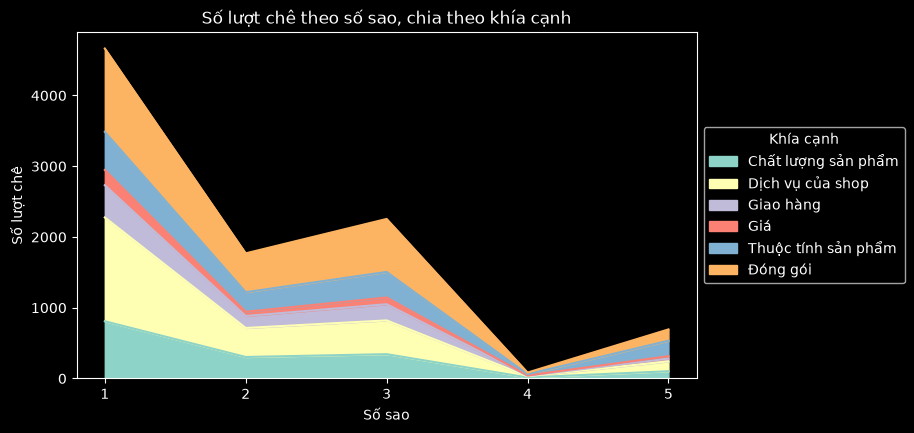

In [465]:
bang_luot_che.drop(columns='Tổng').plot(kind='area', stacked=True, figsize=(8, 4.5))
plt.title("Số lượt chê theo số sao, chia theo khía cạnh")
plt.xlabel("Số sao")
plt.ylabel("Số lượt chê")
plt.xticks([1, 2, 3, 4, 5])
plt.legend(title="Khía cạnh", loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [466]:
bang_diem = pd.DataFrame()
for ma in DS_KHIA_CANH:
    bang_diem[ma] = (df_absa['cx_' + ma] == NHAN_TICH_CUC).astype(int) - (df_absa['cx_' + ma] == NHAN_TIEU_CUC).astype(int)
df_absa['diem_khia_canh'] = bang_diem.sum(axis=1)

lm = LinearRegression()
lm.fit(df_absa[['diem_khia_canh']], df_absa['rating'])
print("Hệ số chặn a:", round(lm.intercept_, 3))
print("Hệ số góc b:", round(lm.coef_[0], 3))
print("R^2:", round(lm.score(df_absa[['diem_khia_canh']], df_absa['rating']), 3))
df_absa.groupby('diem_khia_canh')['rating'].agg(['mean', 'count']).round(2).T

Hệ số chặn a: 3.024
Hệ số góc b: 0.642
R^2: 0.54


diem_khia_canh,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
mean,1.0,1.21,1.46,1.62,1.75,1.91,2.82,4.35,4.75,4.87,4.9,4.89,4.0
count,2.0,28.00,123.00,558.00,1502.00,2527.00,1289.00,1225.00,1188.00,781.00,297.0,61.00,3.0


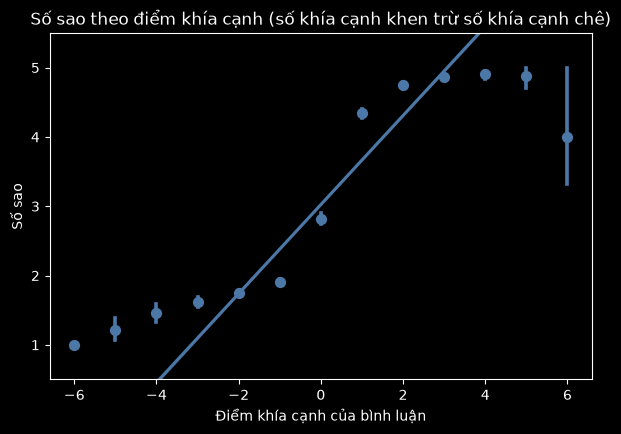

In [467]:
plt.figure(figsize=(7, 4.5))
sns.regplot(x='diem_khia_canh', y='rating', data=df_absa, x_estimator=np.mean, color=MAU_CHUNG)
plt.title("Số sao theo điểm khía cạnh (số khía cạnh khen trừ số khía cạnh chê)")
plt.xlabel("Điểm khía cạnh của bình luận")
plt.ylabel("Số sao")
plt.ylim(0.5, 5.5)
plt.show()

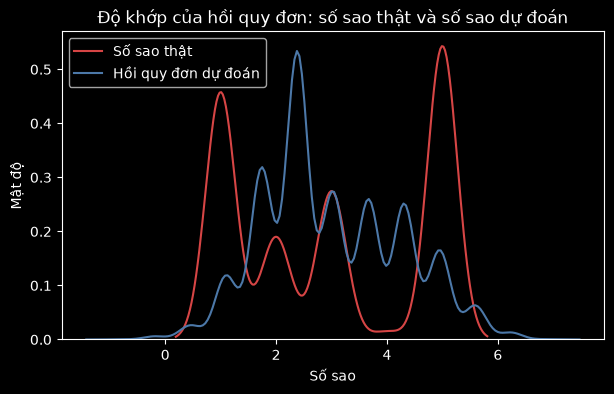

In [468]:
yhat_don = lm.predict(df_absa[['diem_khia_canh']])
plt.figure(figsize=(7, 4))
ax1 = sns.kdeplot(data=df_absa, x='rating', color=MAU_TIEU_CUC, label="Số sao thật")
sns.kdeplot(x=yhat_don, ax=ax1, color=MAU_CHUNG, label="Hồi quy đơn dự đoán")
plt.title("Độ khớp của hồi quy đơn: số sao thật và số sao dự đoán")
plt.xlabel("Số sao")
plt.ylabel("Mật độ")
plt.legend()
plt.show()

In [469]:
lm_boi = LinearRegression()
lm_boi.fit(bang_diem, df_absa['rating'])
yhat_boi = lm_boi.predict(bang_diem)
print("Hệ số chặn a:", round(lm_boi.intercept_, 3))
print("R^2:", round(lm_boi.score(bang_diem, df_absa['rating']), 3))
bang_he_so = pd.DataFrame({'khia_canh': [TEN_KHIA_CANH_ABSA[ma] for ma in DS_KHIA_CANH],
                           'he_so': lm_boi.coef_.round(3)}).sort_values('he_so', ascending=False)
bang_he_so

Hệ số chặn a: 3.095
R^2: 0.549


,khia_canh,he_so
4,Dịch vụ của shop,0.932
0,Chất lượng sản phẩm,0.671
5,Thuộc tính sản phẩm,0.625
2,Đóng gói,0.579
1,Giao hàng,0.555
3,Giá,0.471


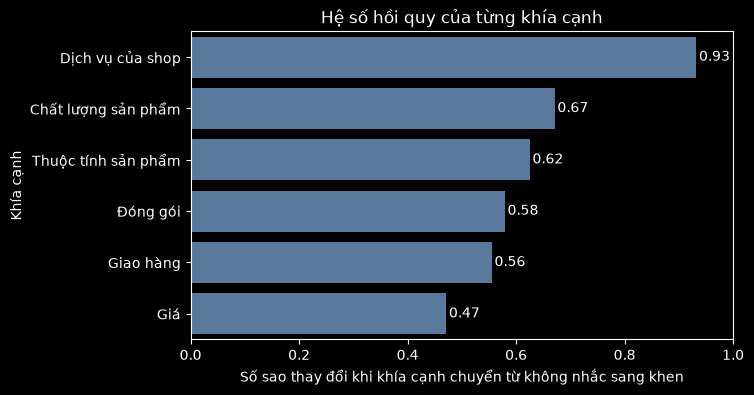

In [470]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=bang_he_so, x='he_so', y='khia_canh', color=MAU_CHUNG)
for nhom_cot in ax.containers:
    ax.bar_label(nhom_cot, fmt='%.2f', padding=2)
plt.title("Hệ số hồi quy của từng khía cạnh")
plt.xlabel("Số sao thay đổi khi khía cạnh chuyển từ không nhắc sang khen")
plt.ylabel("Khía cạnh")
plt.xlim(0, 1)
plt.show()

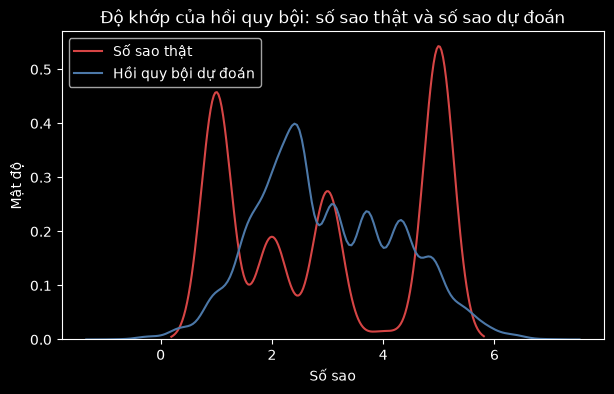

In [471]:
plt.figure(figsize=(7, 4))
ax1 = sns.kdeplot(data=df_absa, x='rating', color=MAU_TIEU_CUC, label="Số sao thật")
sns.kdeplot(x=yhat_boi, ax=ax1, color=MAU_CHUNG, label="Hồi quy bội dự đoán")
plt.title("Độ khớp của hồi quy bội: số sao thật và số sao dự đoán")
plt.xlabel("Số sao")
plt.ylabel("Mật độ")
plt.legend()
plt.show()

In [472]:
x_train, x_test, y_train, y_test = train_test_split(bang_diem, df_absa['rating'], test_size=0.2, random_state=0)
print(x_train.shape, x_test.shape)

(7667, 6) (1917, 6)


In [473]:
ds_bac = [1, 2, 3, 4, 5, 6]
ds_dong = []
for bac in ds_bac:
    Input = [('ss', StandardScaler()),
             ('pf', PolynomialFeatures(degree=bac, include_bias=False)),
             ('lm', LinearRegression())]
    pipe = Pipeline(Input)
    pipe.fit(x_train, y_train)
    ds_dong.append({'bac': bac,
                    'so_dac_trung': pipe.named_steps['pf'].n_output_features_,
                    'mse_train': mean_squared_error(y_train, pipe.predict(x_train)),
                    'mse_test': mean_squared_error(y_test, pipe.predict(x_test)),
                    'r2_train': pipe.score(x_train, y_train),
                    'r2_test': pipe.score(x_test, y_test)})
bang_bac = pd.DataFrame(ds_dong).set_index('bac')
bang_bac.round(4)

,so_dac_trung,mse_train,mse_test,r2_train,r2_test
bac,,,,,
1,6,1.2808,1.2961,0.5485,0.5472
2,27,1.1904,1.1929,0.5803,0.5832
3,83,1.0577,1.1183,0.6271,0.6093
4,209,1.0202,1.0962,0.6403,0.6170
5,461,0.9706,1.1546,0.6578,0.5966
6,923,0.9526,1.6740,0.6642,0.4151


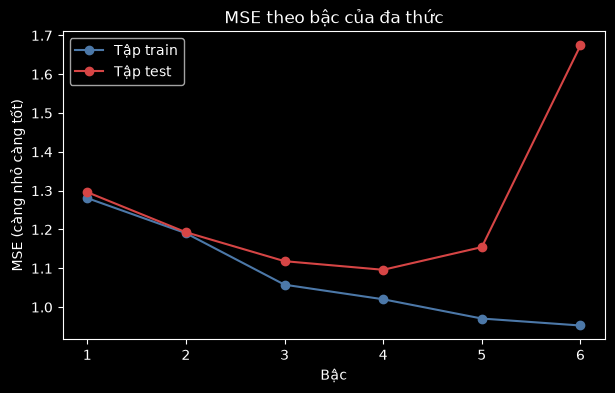

In [474]:
bang_bac[['mse_train', 'mse_test']].plot(marker='o', figsize=(7, 4), color=[MAU_CHUNG, MAU_TIEU_CUC])
plt.title("MSE theo bậc của đa thức")
plt.xlabel("Bậc")
plt.ylabel("MSE (càng nhỏ càng tốt)")
plt.legend(["Tập train", "Tập test"])
plt.show()

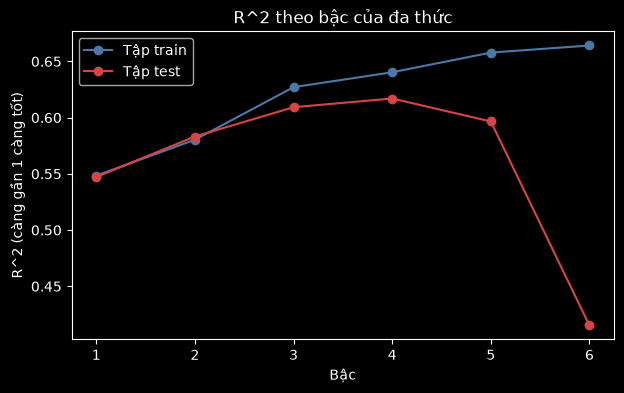

In [475]:
bang_bac[['r2_train', 'r2_test']].plot(marker='o', figsize=(7, 4), color=[MAU_CHUNG, MAU_TIEU_CUC])
plt.title("R^2 theo bậc của đa thức")
plt.xlabel("Bậc")
plt.ylabel("R^2 (càng gần 1 càng tốt)")
plt.legend(["Tập train", "Tập test"])
plt.show()

Bậc được chọn: 4


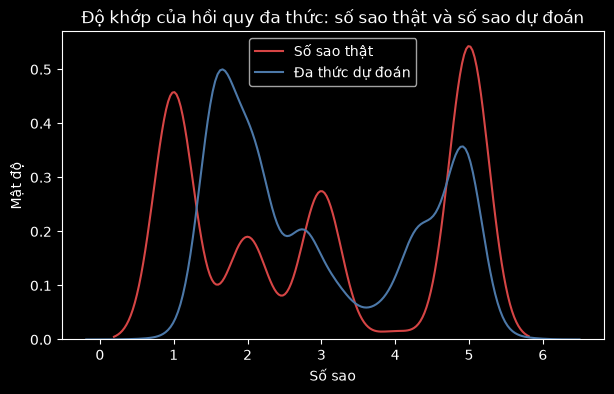

In [476]:
bac_chon = bang_bac['r2_test'].idxmax()
print("Bậc được chọn:", bac_chon)
Input = [('ss', StandardScaler()),
         ('pf', PolynomialFeatures(degree=bac_chon, include_bias=False)),
         ('lm', LinearRegression())]
pipe = Pipeline(Input)
pipe.fit(x_train, y_train)
yhat_da_thuc = pipe.predict(bang_diem)
plt.figure(figsize=(7, 4))
ax1 = sns.kdeplot(data=df_absa, x='rating', color=MAU_TIEU_CUC, label="Số sao thật")
sns.kdeplot(x=yhat_da_thuc, ax=ax1, color=MAU_CHUNG, label="Đa thức dự đoán")
plt.title("Độ khớp của hồi quy đa thức: số sao thật và số sao dự đoán")
plt.xlabel("Số sao")
plt.ylabel("Mật độ")
plt.legend()
plt.show()

In [477]:
## 11. Điểm khía cạnh theo ngành hàng - thang 10

In [478]:
bang_diem_10 = ((100 - bang_nganh_khia_canh) / 10).round(1)
ds_diem_chung = []
for ma in DS_KHIA_CANH:
    df_co_nhac = df_absa[df_absa['cx_' + ma] != '']
    ds_diem_chung.append(round((df_co_nhac['cx_' + ma] == NHAN_TICH_CUC).mean() * 10, 1))
bang_diem_10.loc['Tất cả bình luận'] = ds_diem_chung
bang_diem_10

,Chất lượng sản phẩm,Giao hàng,Đóng gói,Giá,Dịch vụ của shop,Thuộc tính sản phẩm
nganh_hang,,,,,,
Khác,6.1,6.7,4.6,7.0,1.7,6.2
Mỹ phẩm,7.1,8.1,5.9,7.8,3.0,7.4
Thời trang,7.3,7.0,4.9,7.4,2.0,6.1
Thực phẩm,4.4,5.1,4.8,7.4,1.9,6.1
Tất cả bình luận,5.7,6.4,3.6,7.0,1.5,6.4


In [479]:
bang_so_nhac = pd.DataFrame()
for ma in DS_KHIA_CANH:
    df_co_nhac = df_ro_nganh[df_ro_nganh['cx_' + ma] != '']
    bang_so_nhac[TEN_KHIA_CANH_ABSA[ma]] = df_co_nhac.groupby('nganh_hang').size()
bang_so_nhac

,Chất lượng sản phẩm,Giao hàng,Đóng gói,Giá,Dịch vụ của shop,Thuộc tính sản phẩm
nganh_hang,,,,,,
Khác,785,304,756,222,315,706
Mỹ phẩm,580,343,499,195,312,1347
Thời trang,140,53,45,47,49,215
Thực phẩm,149,140,316,65,78,352


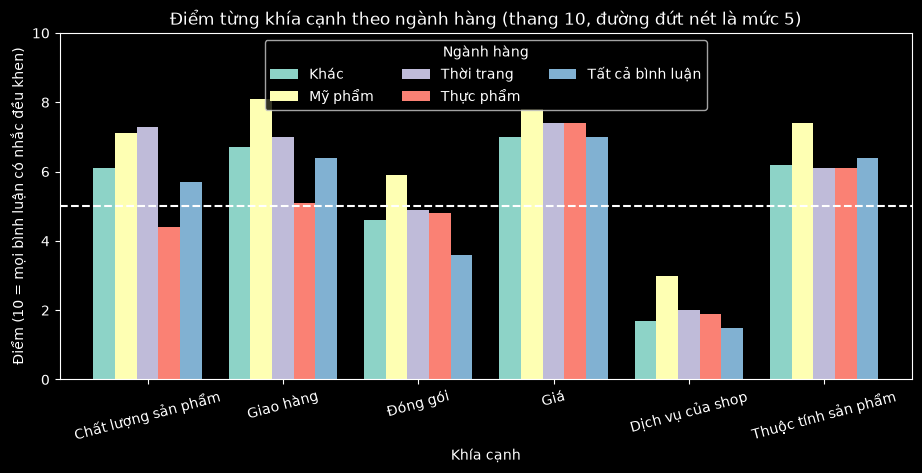

In [480]:
ax = bang_diem_10.T.plot(kind='bar', figsize=(11, 4.5), rot=15, width=0.8)
plt.axhline(5, color=MAU_NET, linestyle='--')
plt.title("Điểm từng khía cạnh theo ngành hàng (thang 10, đường đứt nét là mức 5)")
plt.xlabel("Khía cạnh")
plt.ylabel("Điểm (10 = mọi bình luận có nhắc đều khen)")
plt.ylim(0, 10)
plt.legend(title="Ngành hàng", ncol=3, loc='upper center')
plt.show()

In [481]:
## 12. Kiểm tra nhanh - du_doan, phan_tich_absa

In [482]:
ds_cau_thu = [
    ('Hàng đẹp, giao nhanh, đóng gói cẩn thận', TEN_TICH_CUC,
     {'PRODUCT_QUALITY': NHAN_TICH_CUC, 'DELIVERY': NHAN_TICH_CUC, 'PACKAGING': NHAN_TICH_CUC}),
    ('Sản phẩm kém chất lượng, dùng 2 ngày đã hỏng', TEN_TIEU_CUC,
     {'PRODUCT_QUALITY': NHAN_TIEU_CUC}),
    ('Sản phẩm tốt nhưng giao hàng chậm', '',
     {'PRODUCT_QUALITY': NHAN_TICH_CUC, 'DELIVERY': NHAN_TIEU_CUC}),
    ('Mua 1 tặng 1 nhưng chỉ giao 1, không thấy quà tặng', TEN_TIEU_CUC,
     {'SELLER_SERVICE': NHAN_TIEU_CUC}),
    ('Giá rẻ, mùi thơm, sẽ ủng hộ shop', TEN_TICH_CUC,
     {'PRICE': NHAN_TICH_CUC, 'PRODUCT_FEATURE': NHAN_TICH_CUC}),
    ('Đóng gói sơ sài, hộp móp méo hết', TEN_TIEU_CUC,
     {'PACKAGING': NHAN_TIEU_CUC}),
    ('Shop tư vấn nhiệt tình, giao hàng nhanh', TEN_TICH_CUC,
     {'DELIVERY': NHAN_TICH_CUC, 'SELLER_SERVICE': NHAN_TICH_CUC}),
    ('Bao bì:đẹp Mùi hương:hắc  Giao nhanh, giá rẻ', '',
     {'DELIVERY': NHAN_TICH_CUC, 'PACKAGING': NHAN_TICH_CUC, 'PRICE': NHAN_TICH_CUC, 'PRODUCT_FEATURE': NHAN_TIEU_CUC}),
    ('Đóng gói, giao hàng đều tốt', TEN_TICH_CUC,
     {'DELIVERY': NHAN_TICH_CUC, 'PACKAGING': NHAN_TICH_CUC}),
    ('Không có gì để chê về giao hàng', TEN_TICH_CUC,
     {'DELIVERY': NHAN_TICH_CUC}),
]
len(ds_cau_thu)

10

In [483]:
mo_hinh_web = joblib.load('../mo_hinh/mo_hinh.joblib')
ds_dong = []
for binh_luan, nhan_mong_doi, khia_canh_mong_doi in ds_cau_thu:
    nhan_may = du_doan(binh_luan, mo_hinh_web)['nhan']
    khia_canh_may = {}
    for khia_canh in phan_tich_absa(binh_luan, mo_hinh_cam_xuc)['aspects']:
        khia_canh_may[khia_canh['aspect']] = khia_canh['sentiment']
    ds_dong.append({'binh_luan': binh_luan,
                    'nhan_may': nhan_may,
                    'dung_nhan': nhan_mong_doi == '' or nhan_may == nhan_mong_doi,
                    'khia_canh_may': khia_canh_may,
                    'dung_khia_canh': khia_canh_may == khia_canh_mong_doi})
bang_kiem_tra = pd.DataFrame(ds_dong)
bang_kiem_tra

,binh_luan,nhan_may,dung_nhan,khia_canh_may,dung_khia_canh
0,"Hàng đẹp, giao nhanh, đóng gói cẩn thận",Tích cực,True,"{'PRODUCT_QUALITY': 'positive', 'DELIVERY': 'positive', 'PACKAGING': 'positive'}",True
1,"Sản phẩm kém chất lượng, dùng 2 ngày đã hỏng",Tiêu cực,True,{'PRODUCT_QUALITY': 'negative'},True
2,Sản phẩm tốt nhưng giao hàng chậm,Tiêu cực,True,"{'PRODUCT_QUALITY': 'positive', 'DELIVERY': 'negative'}",True
3,"Mua 1 tặng 1 nhưng chỉ giao 1, không thấy quà tặng",Tiêu cực,True,{'SELLER_SERVICE': 'negative'},True
4,"Giá rẻ, mùi thơm, sẽ ủng hộ shop",Tích cực,True,"{'PRICE': 'positive', 'PRODUCT_FEATURE': 'positive'}",True
5,"Đóng gói sơ sài, hộp móp méo hết",Tiêu cực,True,{'PACKAGING': 'negative'},True
6,"Shop tư vấn nhiệt tình, giao hàng nhanh",Tích cực,True,"{'DELIVERY': 'positive', 'SELLER_SERVICE': 'positive'}",True
7,"Bao bì:đẹp Mùi hương:hắc Giao nhanh, giá rẻ",Tích cực,True,"{'DELIVERY': 'positive', 'PACKAGING': 'positive', 'PRICE': 'positive', 'PRODUCT_FEATURE': 'negative'}",True
8,"Đóng gói, giao hàng đều tốt",Trung lập,False,"{'DELIVERY': 'positive', 'PACKAGING': 'negative'}",False
9,Không có gì để chê về giao hàng,Tiêu cực,False,{'DELIVERY': 'negative'},False


In [484]:
print("Đúng nhãn cả câu:", bang_kiem_tra['dung_nhan'].sum(), "/", len(bang_kiem_tra))
print("Đúng mọi khía cạnh:", bang_kiem_tra['dung_khia_canh'].sum(), "/", len(bang_kiem_tra))

Đúng nhãn cả câu: 8 / 10
Đúng mọi khía cạnh: 8 / 10
